# TPI IA 2026 Primavera — Comprensión visual de escenas
## Grupo 4 (5K3A)

### Qué hace este notebook

Para cada imagen produce un **SceneJSON**: los objetos de las 120 categorías del TPI (caja, máscara y confianza),
sus atributos derivados de la máscara (centroide, área relativa, zona de la imagen y tamaño) y relaciones espaciales
entre ellos. Sobre ese SceneJSON responde preguntas de dos maneras: un **modo determinista** que usa los campos
estructurados de cada pregunta y un **modo LLM** que interpreta el texto libre. El notebook corre todo de punta a punta
en Kaggle y escribe `submission.csv`.

### La pipeline

```
imagen
  ├─ Grounding DINO base ─────────────────┐   (vocabulario abierto, 120 nombres de categoría)
  ├─ EVA-02-L LVIS+O365: imagen y 2x2 ────┤   (detector supervisado en LVIS; también da máscaras)
  ├─ EVA-02-L LVIS (segunda opinión) ─────┤
  └─ SAM 3 (cajas ≥ 2 % de la imagen) ────┘
        ↓ todos los candidatos juntos
  re-puntaje aprendido: P(acierto) por candidato (HistGradientBoosting + árboles extremos)
        ↓ supresión de duplicados (NMS) y umbral
  máscaras: EVA-02 en objetos chicos, SAM 3 en medianos y grandes, SAM2 si no hay otra
        ↓
  SceneJSON: atributos desde la máscara + relaciones (una por objeto, con su mejor pareja)
        ↓
  preguntas: modo determinista y modo LLM (Qwen3-1.7B interpreta, el motor responde)
```

Cada elección (fuentes, modelo de re-puntaje, umbrales, máscaras, relaciones) se toma **dentro del notebook** con
validación por mitades: se elige en una mitad de las 120 imágenes de desarrollo y se mide en la otra. Una variante
reemplaza a la actual sólo si gana por más de 0.002.

### Resultados por versión

| Versión | Cambio principal | Local (desarrollo) | Público (Kaggle) |
|---|---|---|---|
| 3 | Grounding DINO + OWLv2, re-puntaje de candidatos | 0.664 | — |
| 7 | recortes 2x2, máscaras ampliadas para objetos chicos | 0.668 | — |
| 8 | ViTDet-H entrenado en LVIS como detector principal | 0.7548 | 0.7927 |
| 11 | Soft-NMS, máscaras de SAM 3, relaciones "pareja" | 0.7615 | 0.8028 |
| 12 | mezcla de clasificadores (HGB + árboles extremos) | 0.7738 | 0.8115 |
| 13 | **EVA-02-L en lugar de ViTDet-H** | **0.7930** | **0.8255** |

Local = puntaje completo de la métrica sobre las 120 imágenes de desarrollo, cada una evaluada con modelos que no
la vieron (sección 7). Público = 40 % del test (unas 24 imágenes): varía ±0.03 por azar.

### Modelos y recursos

| Etapa | Modelo | Datos de entrenamiento (según sus autores) | Licencia |
|---|---|---|---|
| Detección | Grounding DINO base (`IDEA-Research/grounding-dino-base`) | COCO, Objects365, GoldG, Cap4M, OpenImages, ODinW-35, RefCOCO | Apache-2.0 |
| Detección y máscaras | EVA-02-L Cascade Mask R-CNN `eva02_L_lvis_sys` y `eva02_L_lvis_sys_o365` (BAAI, `Yuxin-CV/EVA-02`, revisión fija y SHA-256 verificado) | LVIS v1 train (+ Objects365); preentrenamiento MIM en ImageNet-21K, sin COCO | código MIT, pesos Apache-2.0 |
| Candidatos y máscaras | SAM 3 (Meta; copia `tkclam/sam3` en revisión fija, idéntica a `facebook/sam3`: mismo SHA-256) | SA-Co (Meta) | SAM License |
| Segmentación | SAM2.1 hiera-large (`facebook/sam2.1-hiera-large`) | SA-1B, SA-V | Apache-2.0 |
| Re-puntaje | HistGradientBoostingClassifier y ExtraTreesClassifier (scikit-learn) | las 120 imágenes de desarrollo | BSD-3 |
| Modo LLM | Qwen3-1.7B (`Qwen/Qwen3-1.7B`) | — | Apache-2.0 |
| Métrica local | copia de la métrica oficial de la competencia | — | de la cátedra |

**Sobre los datos de entrenamiento.** Las imágenes del TPI salen de LVIS val, que a su vez salen de COCO. Los
autores de EVA-02 inician sus modelos de LVIS desde ImageNet-21K justamente para no entrenar con imágenes de COCO.
Grounding DINO base, en cambio, declara COCO entre sus datos: lo declaramos aquí para que quede a la vista. Ningún
modelo se ajusta con imágenes del test.

### Uso de las anotaciones

Las anotaciones de desarrollo (`gt`, `qa_refs`) se usan para el análisis exploratorio, para medir y elegir
parámetros, y para entrenar los modelos de re-puntaje. **Nunca para producir la predicción de una imagen con sus
propias anotaciones**: cada imagen de desarrollo se puntúa con modelos entrenados en la otra mitad; las 20 del
benchmark de preguntas, con modelos entrenados en las otras 100; el test, con modelos entrenados en las 120. La
pipeline procesa cualquier imagen sin anotaciones (ver la demo `TPI_IA_2026P_4_demo`).

### Contenido

0. Entorno · 1. Análisis exploratorio · 2. Detección · 3. Re-puntaje · 4. Segmentación · 5. SceneJSON y máscaras ·
6. Preguntas · 7. Evaluación · 8. Envío · 9. Trazabilidad · Anexo: lo que se probó y no se usa

## 0. Entorno y módulos

El código de la pipeline está en módulos (`tpi_*.py`) que se escriben a `/kaggle/working`.

In [1]:
!pip install -q "transformers==5.20.0" pycocotools jsonschema
import torch, transformers
print(transformers.__version__, torch.__version__, torch.cuda.get_device_name(0), "| GPU:", torch.cuda.device_count())

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.8/12.8 MB 95.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 846.4/846.4 kB 38.0 MB/s eta 0:00:00
5.20.0 2.11.0+cu128 Tesla T4 | GPU: 2


EVA-02 corre sobre la copia de Detectron2 de su repositorio, en un commit fijo. Es de 2023: en la sección 2 se
agregan módulos mínimos para xformers (la atención de PyTorch hace el mismo cálculo) y mmcv (no se usa), y los
nombres que quitaron Pillow 10 y NumPy 2.

In [2]:
!git clone -q --depth 1 --filter=blob:none --sparse https://github.com/baaivision/EVA /tmp/eva
!git -C /tmp/eva fetch -q --depth 1 origin 5623d08bb08a8268c7bc18e1d9b8b4bd651fe4d9 && git -C /tmp/eva checkout -q 5623d08bb08a8268c7bc18e1d9b8b4bd651fe4d9
!git -C /tmp/eva sparse-checkout set EVA-02/det && git -C /tmp/eva rev-parse HEAD
!pip install -q einops && pip install -q --no-build-isolation /tmp/eva/EVA-02/det 2>&1 | tail -3

remote: Enumerating objects: 2, done.
remote: Counting objects: 100% (2/2), done.
remote: Compressing objects: 100% (2/2), done.
remote: Total 2 (delta 0), reused 1 (delta 0), pack-reused 0 (from 0)
Receiving objects: 100% (2/2), 1.55 KiB | 1.55 MiB/s, done.
remote: Enumerating objects: 860, done.
remote: Counting objects: 100% (860/860), done.
remote: Compressing objects: 100% (615/615), done.
remote: Total 860 (delta 247), reused 831 (delta 239), pack-reused 0 (from 0)
Receiving objects: 100% (860/860), 1.02 MiB | 18.31 MiB/s, done.
Resolving deltas: 100% (247/247), done.
5623d08bb08a8268c7bc18e1d9b8b4bd651fe4d9
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 153.9/153.9 kB 5.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 168.8/168.8 kB 6.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 129.7/129.7 kB 6.9 MB/s eta 0:00:00


In [3]:
%%writefile /kaggle/working/tpi_core.py
"""Herramientas base del TPI IA 2026 (fase 0).

- RLE no comprimido column-major (el formato que exige la métrica).
- Geometría de cada objeto calculada igual que la métrica oficial
  (centroide, área relativa, posición 3x3, tamaño, bbox).
- Construcción del SceneJSON y de sus relaciones.
- Carga de las anotaciones de desarrollo y armado de una "solución privada"
  local con el mismo formato que usa Kaggle, para evaluar con la métrica
  oficial sin gastar envíos.

Funciona igual en local y dentro de un notebook de Kaggle.
"""

from __future__ import annotations

import json
import re
import sys
from collections import defaultdict
from pathlib import Path
from typing import Any

import numpy as np
import pandas as pd

LOCAL_DATA_DIR = Path(__file__).resolve().parents[1] / "data"


def _find_data_dir() -> Path:
    """En Kaggle la ruta de montaje de la competencia varía; se busca el schema."""
    kaggle_input = Path("/kaggle/input")
    if kaggle_input.exists():
        for depth in ("*", "*/*", "*/*/*"):
            for schema in sorted(kaggle_input.glob(f"{depth}/scene_schema.json")):
                return schema.parent
    return LOCAL_DATA_DIR


DATA_DIR = _find_data_dir()

POSITIONS = (
    "top_left", "top_center", "top_right",
    "middle_left", "center", "middle_right",
    "bottom_left", "bottom_center", "bottom_right",
)

# Frases de las preguntas de relación -> predicado del SceneJSON.
RELATION_PHRASES = {
    "a la izquierda de": "left_of",
    "a la derecha de": "right_of",
    "por encima de": "above",
    "por debajo de": "below",
}


# --------------------------------------------------------------------------
# RLE
# --------------------------------------------------------------------------

def mask_to_rle(mask: np.ndarray) -> dict[str, Any]:
    """Máscara binaria (H, W) -> RLE no comprimido column-major.

    ``counts`` alterna fondo/objeto y siempre empieza por fondo (puede ser 0).
    """
    mask = np.asarray(mask, dtype=bool)
    height, width = mask.shape
    flat = mask.ravel(order="F")
    change = np.flatnonzero(flat[1:] != flat[:-1]) + 1
    bounds = np.concatenate(([0], change, [flat.size]))
    counts = np.diff(bounds).tolist()
    if flat[0]:
        counts = [0] + counts
    return {"size": [int(height), int(width)], "counts": [int(c) for c in counts]}


def rle_to_mask(rle: dict[str, Any]) -> np.ndarray:
    height, width = rle["size"]
    flat = np.zeros(height * width, dtype=bool)
    position = 0
    for index, run in enumerate(rle["counts"]):
        if index % 2 == 1:
            flat[position:position + run] = True
        position += run
    return flat.reshape((height, width), order="F")


# --------------------------------------------------------------------------
# Geometría (mismas reglas que la métrica oficial)
# --------------------------------------------------------------------------

def mask_geometry(mask: np.ndarray) -> tuple[int, float, float, tuple[int, int, int, int]]:
    """Área, centroide (x, y) y bbox xyxy de la máscara, como ``rle_geometry``."""
    ys, xs = np.nonzero(mask)
    if xs.size == 0:
        return 0, 0.0, 0.0, (0, 0, 0, 0)
    bbox = (int(xs.min()), int(ys.min()), int(xs.max()) + 1, int(ys.max()) + 1)
    return int(xs.size), float(xs.mean()), float(ys.mean()), bbox


def position_of(cx: float, cy: float, width: int, height: int) -> str:
    horizontal = "left" if cx < width / 3 else "right" if cx >= 2 * width / 3 else "center"
    vertical = "top" if cy < height / 3 else "bottom" if cy >= 2 * height / 3 else "middle"
    if vertical == "middle" and horizontal == "center":
        return "center"
    return f"{vertical}_{horizontal}"


def size_of(area_ratio: float) -> str:
    if area_ratio < 0.02:
        return "small"
    if area_ratio < 0.15:
        return "medium"
    return "large"


def clip_box(box, width: int, height: int) -> list[float] | None:
    """Recorta una caja xyxy a la imagen; None si queda degenerada."""
    x0, y0, x1, y1 = (float(v) for v in box)
    x0, x1 = max(0.0, min(x0, width)), max(0.0, min(x1, width))
    y0, y1 = max(0.0, min(y0, height)), max(0.0, min(y1, height))
    if x1 <= x0 or y1 <= y0:
        return None
    return [x0, y0, x1, y1]


# --------------------------------------------------------------------------
# SceneJSON
# --------------------------------------------------------------------------

def make_object(
    object_id: str,
    category_id: int,
    confidence: float,
    mask: np.ndarray,
    box=None,
    **extra: Any,
) -> dict[str, Any] | None:
    """Objeto del SceneJSON con todos los campos consistentes con su máscara.

    ``box`` (xyxy) es la caja del detector; si falta se usa la de la máscara.
    Devuelve None si la máscara está vacía (la métrica la rechazaría).
    """
    height, width = mask.shape
    area, cx, cy, mask_box = mask_geometry(mask)
    if area == 0:
        return None
    bbox = clip_box(box, width, height) if box is not None else None
    if bbox is None:
        bbox = [float(v) for v in mask_box]
    area_ratio = area / (width * height)
    obj = {
        "id": object_id,
        "category_id": int(category_id),
        "confidence": float(min(1.0, max(0.0, confidence))),
        "bbox": bbox,
        "mask": mask_to_rle(mask),
        "centroid": [cx, cy],
        "area_ratio": area_ratio,
        "position": position_of(cx, cy, width, height),
        "size": size_of(area_ratio),
    }
    obj.update(extra)
    return obj


def build_relations(
    objects: list[dict[str, Any]],
    min_confidence: float = 0.0,
    include_overlaps: bool = False,
    masks: dict[str, np.ndarray] | None = None,
) -> list[dict[str, str]]:
    """Relaciones espaciales entre todos los pares de objetos confiables.

    Igual que la métrica, left/right/above/below se deciden por centroide de
    máscara. ``overlaps`` necesita las máscaras (``masks`` por id de objeto).
    """
    kept = [o for o in objects if o["confidence"] >= min_confidence]
    relations = []
    for i, a in enumerate(kept):
        for b in kept[i + 1:]:
            (ax, ay), (bx, by) = a["centroid"], b["centroid"]
            pairs = []
            if ax < bx:
                pairs += [(a, "left_of", b), (b, "right_of", a)]
            elif ax > bx:
                pairs += [(a, "right_of", b), (b, "left_of", a)]
            if ay < by:
                pairs += [(a, "above", b), (b, "below", a)]
            elif ay > by:
                pairs += [(a, "below", b), (b, "above", a)]
            if include_overlaps and masks is not None and np.any(masks[a["id"]] & masks[b["id"]]):
                pairs += [(a, "overlaps", b), (b, "overlaps", a)]
            relations += [{"subject": s["id"], "predicate": p, "object": o["id"]} for s, p, o in pairs]
    return relations


def build_relations_anchor(objects: list[dict[str, Any]], width: int, height: int,
                           n_anchors: int = 1) -> list[dict[str, str]]:
    """Relaciones contra "anclas": los ``n_anchors`` objetos más confiables.

    La métrica cuenta una relación como correcta sólo si sus dos objetos son aciertos, y premia que
    cada objeto real aparezca en al menos una relación correcta. Relacionar cada objeto con un ancla
    muy confiable cubre todos los objetos con pocas relaciones. Se usa un solo predicado por par, el
    del eje en que los centroides más se separan (relativo al ancho o alto), que es el menos sensible
    a que el centroide predicho se corra unos píxeles.
    """
    ranked = sorted(objects, key=lambda o: o["confidence"], reverse=True)
    anchors = ranked[:n_anchors]
    relations = []
    for a in ranked:
        for b in anchors:
            if a is b or (a in anchors and anchors.index(a) > anchors.index(b)):
                continue
            dx = (a["centroid"][0] - b["centroid"][0]) / width
            dy = (a["centroid"][1] - b["centroid"][1]) / height
            if dx == 0 and dy == 0:
                continue
            if abs(dx) >= abs(dy):
                predicate = "left_of" if dx < 0 else "right_of"
            else:
                predicate = "above" if dy < 0 else "below"
            relations.append({"subject": a["id"], "predicate": predicate, "object": b["id"]})
    return relations


def build_relations_partner(objects: list[dict[str, Any]], width: int, height: int,
                            min_separation: float = 0.05, n_partners: int = 1, any_partner: bool = False,
                            inside_min: float = 0.5) -> list[dict[str, str]]:
    """Una relación por objeto, con su mejor "pareja" entre los objetos más confiables que él.

    La métrica cuenta una relación sólo si sus dos objetos son aciertos y el predicado es cierto con las máscaras
    reales; para la cobertura alcanza con que cada objeto esté en una relación correcta. Por eso cada objeto se
    relaciona una sola vez, con la pareja que maximiza (confianza de la pareja) x (claridad del predicado):
    - "overlaps" si más de la mitad del objeto cae dentro de la máscara de la pareja (una perilla sobre un mueble):
      con las máscaras reales casi siempre se tocan;
    - si no, el eje en que más se separan los centroides; la claridad crece con la separación (relativa al ancho o
      alto) hasta ``min_separation``, para no apostar a predicados que dependen de pocos píxeles.
    El objeto más confiable se relaciona con el segundo, así también queda cubierto.
    ``n_partners`` > 1 relaciona cada objeto con sus mejores parejas; ``any_partner`` busca la pareja entre todos los
    objetos y no sólo entre los más confiables; ``inside_min``: fracción del objeto dentro de la pareja para "overlaps".
    """
    ranked = sorted(objects, key=lambda o: o["confidence"], reverse=True)
    if len(ranked) < 2:
        return []
    masks = [rle_to_mask(o["mask"]) for o in ranked]
    areas = [max(1, int(m.sum())) for m in masks]
    relations, seen = [], set()
    for k, a in enumerate(ranked):
        if any_partner:
            candidates = [j for j in range(len(ranked)) if j != k]
        else:
            candidates = range(k) if k > 0 else [1]
        options = []
        for j in candidates:
            b = ranked[j]
            inside = np.logical_and(masks[k], masks[j]).sum() / areas[k]
            if inside > inside_min:
                predicate, clarity = "overlaps", 1.0
            else:
                dx = (a["centroid"][0] - b["centroid"][0]) / width
                dy = (a["centroid"][1] - b["centroid"][1]) / height
                if abs(dx) >= abs(dy):
                    predicate = "left_of" if dx < 0 else "right_of"
                else:
                    predicate = "above" if dy < 0 else "below"
                clarity = min(1.0, max(abs(dx), abs(dy)) / min_separation)
            options.append((b["confidence"] * clarity, predicate, b))
        options.sort(key=lambda t: -t[0])
        for value, predicate, b in options[:n_partners]:
            key = frozenset((a["id"], b["id"]))
            if value > 0 and (key not in seen or (n_partners == 1 and not any_partner)):
                seen.add(key)
                relations.append({"subject": a["id"], "predicate": predicate, "object": b["id"]})
    return relations


def build_scene(
    image_id: str,
    width: int,
    height: int,
    objects: list[dict[str, Any]],
    relations: list[dict[str, str]] | None = None,
    questions: list[dict[str, Any]] | None = None,
    questions_llm: list[dict[str, Any]] | None = None,
) -> dict[str, Any]:
    scene = {
        "image": {"id": image_id, "width": int(width), "height": int(height)},
        "objects": objects,
        "relations": relations if relations is not None else build_relations(objects),
    }
    if questions is not None:
        scene["questions"] = questions
    if questions_llm is not None:
        scene["questions_llm"] = questions_llm
    return scene


def scene_to_json(scene: dict[str, Any]) -> str:
    return json.dumps(scene, ensure_ascii=False, separators=(",", ":"))


# --------------------------------------------------------------------------
# Datos
# --------------------------------------------------------------------------

def load_categories(data_dir: Path = DATA_DIR) -> pd.DataFrame:
    return pd.read_csv(data_dir / "tpi_ia_2026_competition_public" / "categories.csv")


def load_questions(data_dir: Path = DATA_DIR) -> list[dict[str, Any]]:
    path = data_dir / "tpi_2026_qa_public" / "questions_dev.jsonl"
    return [json.loads(line) for line in path.read_text().splitlines() if line.strip()]


def load_test_images(data_dir: Path = DATA_DIR) -> pd.DataFrame:
    return pd.read_csv(data_dir / "tpi_ia_2026_competition_public" / "test_images.csv")


def image_path(image_id: str, data_dir: Path = DATA_DIR) -> Path:
    if image_id.startswith("test_"):
        return data_dir / "tpi_ia_2026_competition_public" / "test_images" / f"{image_id}.jpg"
    return data_dir / "development" / "images" / f"{image_id}.jpg"


def dev_image_id(file_name: str) -> str:
    return Path(file_name).stem  # "tpi_0001.jpg" -> "tpi_0001"


def load_dev_annotations(data_dir: Path = DATA_DIR) -> dict[str, dict[str, Any]]:
    """Anotaciones de desarrollo por image_id, con máscaras ya decodificadas."""
    from pycocotools import mask as mask_utils

    coco = json.loads((data_dir / "development" / "annotations.json").read_text())
    anns_by_image = defaultdict(list)
    for ann in coco["annotations"]:
        anns_by_image[ann["image_id"]].append(ann)

    images = {}
    for img in coco["images"]:
        height, width = img["height"], img["width"]
        objects = []
        for ann in anns_by_image[img["id"]]:
            segmentation = ann["segmentation"]
            if isinstance(segmentation, list):
                rles = mask_utils.frPyObjects(segmentation, height, width)
                rle = mask_utils.merge(rles)
            elif isinstance(segmentation.get("counts"), list):
                rle = mask_utils.frPyObjects(segmentation, height, width)
            else:
                rle = segmentation
            mask = mask_utils.decode(rle).astype(bool)
            x, y, w, h = ann["bbox"]
            objects.append({
                "ann_id": ann["id"],
                "category_id": ann["category_id"],
                "box": [x, y, x + w, y + h],
                "mask": mask,
            })
        images[dev_image_id(img["file_name"])] = {
            "coco_id": img["id"],
            "width": width,
            "height": height,
            "neg": list(img.get("neg_category_ids", [])),
            "not_exhaustive": list(img.get("not_exhaustive_category_ids", [])),
            "objects": objects,
        }
    return images


def gt_scene(image_id: str, gt: dict[str, Any], relations: bool = True) -> dict[str, Any]:
    """SceneJSON "perfecto" construido desde la anotación (oráculo para tests)."""
    objects = [
        make_object(f"gt_{k}", o["category_id"], 1.0, o["mask"], o["box"])
        for k, o in enumerate(gt["objects"])
    ]
    objects = [o for o in objects if o is not None]
    rels = build_relations(objects) if relations else []
    if len(objects) == 1:
        rels = []  # con un solo objeto la métrica premia no emitir relaciones
    return build_scene(image_id, gt["width"], gt["height"], objects, rels)


# --------------------------------------------------------------------------
# Referencia QA local (reconstruida desde las anotaciones de desarrollo)
# --------------------------------------------------------------------------

def _relation_predicate(question: str) -> str | None:
    for phrase, predicate in RELATION_PHRASES.items():
        if phrase in question:
            return predicate
    return None


def qa_reference(
    questions: list[dict[str, Any]],
    gt: dict[str, dict[str, Any]],
    category_names: dict[int, str],
) -> dict[str, list[dict[str, Any]]]:
    """Respuestas esperadas por image_id, en el formato ``_qa_ground_truth``.

    Es una reconstrucción: la referencia oficial es privada. Las preguntas
    cerradas apuntan a instancias únicas, así que deberían coincidir. Para
    las descripciones, el idioma de ``reference_facts`` no se conoce; se usan
    los nombres en inglés de ``categories.csv``.
    """
    name_to_id = {v: k for k, v in category_names.items()}
    by_image: dict[str, list[dict[str, Any]]] = defaultdict(list)
    for q in questions:
        image_id = dev_image_id(q["image_file"])
        image = gt[image_id]
        width, height = image["width"], image["height"]

        def instances(name):
            return [o for o in image["objects"] if o["category_id"] == name_to_id[name]]

        ref = {"question_id": q["question_id"], "type": q["type"]}
        if q["type"] == "description":
            counts = defaultdict(int)
            for o in image["objects"]:
                counts[category_names[o["category_id"]]] += 1
            ref["reference_facts"] = {
                "category_counts": [{"category": c, "count": n} for c, n in counts.items()]
            }
        elif q["type"] == "count":
            ref["expected_normalized_answer"] = len(instances(q["class_en"][0]))
        elif q["type"] == "existence":
            ref["expected_normalized_answer"] = "yes" if instances(q["class_en"][0]) else "no"
        elif q["type"] in ("position", "size"):
            (obj,) = instances(q["class_en"][0])
            area, cx, cy, _ = mask_geometry(obj["mask"])
            ref["expected_normalized_answer"] = (
                position_of(cx, cy, width, height)
                if q["type"] == "position"
                else size_of(area / (width * height))
            )
        elif q["type"] == "relation":
            (a,) = instances(q["class_en"][0])
            (b,) = instances(q["class_en"][1])
            _, ax, ay, _ = mask_geometry(a["mask"])
            _, bx, by, _ = mask_geometry(b["mask"])
            predicate = _relation_predicate(q["question"])
            truth = {
                "left_of": ax < bx, "right_of": ax > bx,
                "above": ay < by, "below": ay > by,
            }[predicate]
            ref["expected_normalized_answer"] = "yes" if truth else "no"
        by_image[image_id].append(ref)
    return dict(by_image)


# --------------------------------------------------------------------------
# Evaluación local con la métrica oficial
# --------------------------------------------------------------------------

def _load_metric():
    """Importa la métrica oficial (copiada en reference/tpi_metric.py)."""
    candidates = [
        Path(__file__).resolve().parents[1] / "reference",
        Path("/kaggle/input/tpi-metric"),
        Path("/kaggle/working"),
    ]
    for folder in candidates:
        if (folder / "tpi_metric.py").exists() and str(folder) not in sys.path:
            sys.path.insert(0, str(folder))
    import tpi_metric

    return tpi_metric


def build_dev_solution(
    gt: dict[str, dict[str, Any]],
    image_ids: list[str],
    qa_refs: dict[str, list[dict[str, Any]]] | None = None,
) -> pd.DataFrame:
    """Arma un solution.csv local con el formato privado de Kaggle."""
    rows = []
    for image_id in image_ids:
        image = gt[image_id]
        payload = {
            "image": {"width": image["width"], "height": image["height"]},
            "objects": [
                {"category_id": o["category_id"], "bbox": o["box"], "mask": mask_to_rle(o["mask"])}
                for o in image["objects"]
                if o["mask"].any()
            ],
            "neg": image["neg"],
            "not_exhaustive": image["not_exhaustive"],
        }
        if qa_refs and image_id in qa_refs:
            payload["_qa_ground_truth"] = qa_refs[image_id]
        rows.append({"image_id": image_id, "SceneJSON": json.dumps(payload)})
    return pd.DataFrame(rows)


def scenes_to_submission(scenes: dict[str, dict[str, Any]]) -> pd.DataFrame:
    return pd.DataFrame(
        [{"image_id": image_id, "SceneJSON": scene_to_json(s)} for image_id, s in scenes.items()]
    )


def evaluate(
    scenes: dict[str, dict[str, Any]],
    gt: dict[str, dict[str, Any]],
    qa_refs: dict[str, list[dict[str, Any]]] | None = None,
) -> dict[str, Any]:
    """PipelineScore local sobre las imágenes de desarrollo presentes en ``scenes``."""
    metric = _load_metric()
    image_ids = list(scenes)
    solution = build_dev_solution(gt, image_ids, qa_refs)
    return metric.score_components(solution, scenes_to_submission(scenes), "image_id")


def validate_submission(submission: pd.DataFrame, data_dir: Path = DATA_DIR) -> list[str]:
    """Chequea el envío como lo haría Kaggle antes de puntuar. Devuelve errores."""
    import jsonschema

    metric = _load_metric()
    schema = json.loads((data_dir / "scene_schema.json").read_text())
    sample = pd.read_csv(data_dir / "sample_submission.csv")
    errors = []
    if list(submission.columns) != ["image_id", "SceneJSON"]:
        errors.append(f"columnas inválidas: {list(submission.columns)}")
    if set(submission["image_id"]) != set(sample["image_id"]) or len(submission) != len(sample):
        errors.append("los image_id no coinciden con sample_submission.csv")
    dims = {
        row.image_id: (row.width, row.height) for row in load_test_images(data_dir).itertuples()
    }
    for row in submission.itertuples():
        try:
            metric._parse_scene_cell(row.SceneJSON, str(row.image_id))
            payload = json.loads(row.SceneJSON)
            jsonschema.validate(payload, schema)
        except Exception as exc:  # noqa: BLE001 - se informa cualquier falla
            errors.append(f"{row.image_id}: {exc}")
            continue
        if row.image_id in dims and dims[row.image_id] != (
            payload["image"]["width"], payload["image"]["height"]
        ):
            errors.append(f"{row.image_id}: dimensiones distintas a test_images.csv")
        if str(row.image_id).startswith("tpi_") and not (
            payload.get("questions") and payload.get("questions_llm")
        ):
            errors.append(f"{row.image_id}: faltan questions/questions_llm (QA = 0)")
    return errors

Writing /kaggle/working/tpi_core.py


In [4]:
%%writefile /kaggle/working/tpi_pipeline.py
"""Pipeline del TPI (fase 1): Grounding DINO -> SAM2 -> SceneJSON -> QA determinista.

Separado en dos etapas para poder calibrar sin volver a correr los modelos:

1. ``run_raw``: corre los modelos con un umbral bajo y guarda TODOS los
   candidatos (caja, puntaje, máscara RLE). Es lo caro (GPU).
2. ``build_scene_from_candidates``: aplica umbral, arma objetos y relaciones.
   Es barato, así que se puede barrer el umbral contra la métrica local.
"""

from __future__ import annotations

import gzip
import json
from pathlib import Path
from typing import Any

import numpy as np

import tpi_core as tc

GDINO_ID = "IDEA-Research/grounding-dino-base"
SAM2_ID = "facebook/sam2.1-hiera-large"

# Nombres que Grounding DINO entiende mejor que el nombre LVIS.
# Los de "diagnóstico" se eligieron por categoría: cada uno mejoró el F1 de cajas de su categoría en más de 0.02, y en
# conjunto mejoraron +0.02 en imágenes no usadas para elegirlos.
PROMPT_NAMES = {
    "jean": "jeans",
    "fireplug": "fire hydrant",
    "spectacles": "glasses",
    "short pants": "shorts",
    "flowerpot": "flower pot",
    # diagnóstico
    "cabinet": "cupboard",
    "jersey": "sports shirt",
    "awning": "shop awning",
    "napkin": "paper napkin",
    "knob": "control knob",
    "strap": "bag strap",
    "pole": "metal pole",
    "handle": "door handle",
    "book": "books",
    "curtain": "window curtain",
    "doorknob": "door knob",
    "wall socket": "power outlet",
    "vent": "ventilation grille",
    "tag": "price tag",
    "banner": "hanging banner",
    "signboard": "shop sign board",
    "taillight": "car tail light",
    "television set": "tv screen",
    "drinking glass": "glass of water",
    "flower arrangement": "bouquet of flowers",
    "button": "small round button",
    "belt": "leather belt",
    "ski boot": "ski boots",
    "trash can": "garbage bin",
    "street sign": "street name sign",
}

# Variantes de nombre por categoría ("prompt ensembling"): el detector busca la categoría con varias frases y
# se queda con la que mejor responde. Pensado para las categorías que el detector casi nunca propone (awning,
# button, tag, strap, napkin...) o confunde (cabinet/drawer, knob/doorknob). Son sinónimos y descripciones
# generales del idioma, no salen de las imágenes.
PROMPT_VARIANTS = {
    "awning": ["canopy over a storefront", "sunshade over a window"],
    "banner": ["advertising banner", "cloth banner"],
    "button": ["shirt button", "coat button"],
    "cabinet": ["kitchen cabinet", "wooden cabinet"],
    "earring": ["dangling earring"],
    "jersey": ["team jersey", "football jersey"],
    "knob": ["drawer knob", "dial knob"],
    "napkin": ["cloth napkin", "serviette"],
    "signboard": ["sign", "information sign"],
    "tag": ["label tag", "clothing tag"],
    "taillight": ["rear light of a car", "brake light"],
    "television set": ["television"],
    "vent": ["air vent", "exhaust vent"],
    "strap": ["shoulder strap", "watch strap"],
    "handle": ["cabinet handle", "bag handle"],
    "shirt": ["t-shirt", "dress shirt"],
    "book": ["book on a shelf", "book spine"],
    "belt": ["waist belt"],
    "computer keyboard": ["keyboard"],
    "cup": ["coffee cup", "mug"],
    "doorknob": ["round door handle"],
    "pole": ["post", "lamp post"],
    "street sign": ["road sign", "traffic sign"],
    "cell phone": ["mobile phone", "smartphone"],
    "streetlight": ["street lamp"],
    "boot": ["leather boot"],
    "sunglasses": ["dark glasses"],
    "ring": ["finger ring"],
    "sock": ["socks"],
    "necktie": ["tie"],
    "curtain": ["drapes"],
    "flower arrangement": ["flowers in a vase"],
    "mirror": ["wall mirror", "rearview mirror"],
    "lamp": ["table lamp", "floor lamp"],
    "drinking glass": ["wine glass", "glass cup"],
    "knife": ["table knife", "kitchen knife"],
    "plastic bag": ["shopping bag"],
    "wall socket": ["electrical outlet"],
    "license plate": ["number plate"],
    "headlight": ["car headlight"],
    "windshield wiper": ["wiper blade"],
    "computer monitor": ["monitor screen"],
    "glove": ["gloves"],
    "watch": ["wristwatch"],
    "handbag": ["purse"],
    "trash can": ["waste bin"],
    "bracelet": ["wristband"],
    "basket": ["wicker basket"],
    "box": ["cardboard box"],
    "spectacles": ["eyeglasses"],
    "goggles": ["ski goggles", "swimming goggles"],
    "jean": ["denim pants"],
    "trousers": ["pants"],
    "flowerpot": ["plant pot"],
    "pillow": ["cushion"],
    "baseball cap": ["cap"],
}


def prompt_variants(name: str) -> list[str]:
    """Nombre del prompt + sus variantes (sin repetir), en minúsculas."""
    base = PROMPT_NAMES.get(name, name)
    candidates = [base, name, *PROMPT_VARIANTS[name]] if name in PROMPT_VARIANTS else [base]
    out = []
    for v in candidates:
        if v.lower() not in out:
            out.append(v.lower())
    return out


def make_chunks_pairs(pairs: list[tuple[int, str]], chunk_size: int = 24) -> list[dict[str, Any]]:
    """Como ``make_chunks`` pero con pares (categoría, texto): una categoría puede aparecer con varios textos."""
    chunks = []
    for start in range(0, len(pairs), chunk_size):
        spans, text = [], ""
        for category_id, prompt_name in pairs[start:start + chunk_size]:
            spans.append((category_id, len(text), len(text) + len(prompt_name)))
            text += prompt_name + ". "
        chunks.append({"text": text.strip(), "spans": spans})
    return chunks


# Nombres en español (los de questions_dev.jsonl cuando existen).
SPANISH_NAMES = {
    "sofa": "sofá", "laptop": "computadora portátil", "pillow": "almohada", "bench": "banco",
    "jacket": "chaqueta", "signboard": "cartel", "backpack": "mochila", "traffic light": "semáforo",
    "umbrella": "paraguas", "horse": "caballo", "handle": "manija", "chair": "silla",
    "clock": "reloj", "napkin": "servilleta", "pizza": "pizza", "flag": "bandera",
    "person": "persona", "trousers": "pantalón", "trash can": "tacho de basura", "sock": "calcetín",
    "vase": "jarrón", "bicycle": "bicicleta", "tennis racket": "raqueta de tenis", "necklace": "collar",
    "cell phone": "teléfono celular", "book": "libro", "sunglasses": "anteojos de sol", "lamp": "lámpara",
    "bottle": "botella", "glove": "guante", "shoe": "zapato", "blanket": "manta",
    "computer keyboard": "teclado de computadora", "dog": "perro", "jean": "jean",
    "short pants": "pantalón corto", "flower arrangement": "arreglo floral", "ski": "esquí",
    "cat": "gato", "wheel": "rueda", "faucet": "grifo", "helmet": "casco", "table": "mesa",
    "drinking glass": "vaso", "headlight": "faro delantero", "streetlight": "farola",
    "television set": "televisor", "belt": "cinturón", "bird": "pájaro", "knife": "cuchillo",
    "watch": "reloj de pulsera", "handbag": "cartera", "street sign": "señal de tránsito",
    "bowl": "bol", "ski pole": "bastón de esquí", "hat": "sombrero", "plate": "plato", "car": "auto",
    "curtain": "cortina", "elephant": "elefante", "bed": "cama", "drawer": "cajón", "earring": "aro",
    "boat": "bote", "necktie": "corbata", "skateboard": "patineta", "wall socket": "tomacorriente",
    "fork": "tenedor", "bus": "colectivo", "giraffe": "jirafa", "toilet": "inodoro",
    "surfboard": "tabla de surf", "motorcycle": "moto", "cabinet": "gabinete", "taillight": "luz trasera",
    "train": "tren", "baseball cap": "gorra de béisbol", "airplane": "avión", "jersey": "camiseta deportiva",
    "pole": "poste", "doorknob": "pomo de puerta", "baseball bat": "bate de béisbol", "shirt": "camisa",
    "license plate": "patente", "banana": "banana", "mirror": "espejo", "kite": "barrilete",
    "frisbee": "frisbee", "sink": "pileta", "spectacles": "anteojos", "button": "botón",
    "goggles": "antiparras", "zebra": "cebra", "suitcase": "valija", "baseball glove": "guante de béisbol",
    "basket": "canasta", "refrigerator": "heladera", "ski boot": "bota de esquí", "tablecloth": "mantel",
    "bracelet": "pulsera", "teddy bear": "oso de peluche", "windshield wiper": "limpiaparabrisas",
    "computer mouse": "mouse", "box": "caja", "cup": "taza", "dress": "vestido",
    "computer monitor": "monitor", "broccoli": "brócoli", "strap": "correa", "knob": "perilla",
    "plastic bag": "bolsa de plástico", "ring": "anillo", "awning": "toldo", "vent": "rejilla de ventilación",
    "banner": "pancarta", "cow": "vaca", "flowerpot": "maceta", "tag": "etiqueta",
    "fireplug": "hidrante", "boot": "bota",
}

# otros nombres en español para la misma categoría: los que usan las preguntas de la competencia (vistos en las de
# desarrollo) cuando difieren del nombre de arriba, y sinónimos comunes
SPANISH_ALIASES = {
    "handle": ["mango", "asa"], "handbag": ["bolso"], "computer mouse": ["mouse de computadora", "ratón"],
    "trousers": ["pantalones"],
}


def spanish_names(categories: dict[int, str], questions: list[dict[str, Any]]) -> dict[str, str]:
    names = dict(SPANISH_NAMES)
    for q in questions:  # los nombres de la cátedra tienen prioridad
        for en, es in zip(q.get("class_en", []), q.get("class_es", [])):
            names[en] = es
    return {en: names.get(en, en) for en in categories.values()}


# --------------------------------------------------------------------------
# Modelos
# --------------------------------------------------------------------------

class Models:
    def __init__(self, device: str | None = None, gdino_id: str = GDINO_ID, sam2_id: str = SAM2_ID):
        import torch
        from transformers import (
            AutoModelForZeroShotObjectDetection,
            AutoProcessor,
            Sam2Model,
            Sam2Processor,
        )

        if device is None:
            device = "cuda" if torch.cuda.is_available() else "mps" if torch.backends.mps.is_available() else "cpu"
        self.device = device
        self.torch = torch
        self.gdino_processor = AutoProcessor.from_pretrained(gdino_id)
        self.gdino = AutoModelForZeroShotObjectDetection.from_pretrained(gdino_id).to(device).eval()
        self.sam_processor = Sam2Processor.from_pretrained(sam2_id)
        self.sam = Sam2Model.from_pretrained(sam2_id).to(device).eval()


def make_chunks(categories: dict[int, str], chunk_size: int = 24) -> list[dict[str, Any]]:
    """Parte las categorías en prompts y guarda qué tokens son de cada una."""
    items = sorted(categories.items())
    chunks = []
    for start in range(0, len(items), chunk_size):
        part = items[start:start + chunk_size]
        spans, text = [], ""
        for category_id, name in part:
            prompt_name = PROMPT_NAMES.get(name, name).lower()
            spans.append((category_id, len(text), len(text) + len(prompt_name)))
            text += prompt_name + ". "
        chunks.append({"text": text.strip(), "spans": spans})
    return chunks


def _token_index(chunks: list[dict[str, Any]], tokenizer) -> list[list[tuple[int, list[int]]]]:
    """Para cada tanda: [(category_id, [índices de token]), ...]."""
    result = []
    for chunk in chunks:
        offsets = tokenizer(chunk["text"], return_offsets_mapping=True)["offset_mapping"]
        cats = []
        for category_id, start, end in chunk["spans"]:
            idx = [i for i, (a, b) in enumerate(offsets) if b > a and a >= start and b <= end]
            cats.append((category_id, idx))
        result.append(cats)
    return result


def detect(models: Models, image, chunks, token_index, min_score: float = 0.1,
           nms_iou: float = 0.5, max_candidates: int = 200, chunk_batch: int | None = None,
           top_k: int = 1) -> list[dict[str, Any]]:
    """Cajas candidatas con categoría y puntaje (media sigmoide de sus tokens).

    ``top_k`` > 1 emite la misma caja con sus ``top_k`` categorías más probables (cada una con
    su propio puntaje), para los casos en que el detector duda entre categorías parecidas.

    ``chunk_batch`` limita cuántas tandas de texto entran juntas a la GPU (los modelos
    grandes no entran con las 5 a la vez en una T4). Sirve para cualquier modelo con la
    interfaz de Grounding DINO (MM-Grounding-DINO, LLMDet).
    """
    torch = models.torch
    from torchvision.ops import batched_nms

    width, height = image.size
    step = chunk_batch or len(chunks)
    prob_parts, box_parts = [], []
    for start in range(0, len(chunks), step):
        part = chunks[start:start + step]
        inputs = models.gdino_processor(
            images=[image] * len(part), text=[c["text"] for c in part],
            return_tensors="pt", padding=True,
        ).to(models.device)
        with torch.no_grad():
            outputs = models.gdino(**inputs)
        prob_parts.append(outputs.logits.sigmoid().float().cpu())  # [tandas, queries, tokens]
        box_parts.append(outputs.pred_boxes.float().cpu())         # cxcywh normalizado
    probs, boxes = torch.cat(prob_parts), torch.cat(box_parts)

    all_boxes, all_scores, all_cats, all_ranks = [], [], [], []
    for k, cats in enumerate(token_index):
        per_cat = torch.stack([probs[k][:, idx].mean(dim=1) for _, idx in cats], dim=1)
        top_scores, top_which = per_cat.topk(min(top_k, per_cat.shape[1]), dim=1)
        for j in range(top_scores.shape[1]):
            score, which = top_scores[:, j], top_which[:, j]
            keep = score >= min_score
            if not keep.any():
                continue
            cxcywh = boxes[k][keep]
            xyxy = torch.stack([
                (cxcywh[:, 0] - cxcywh[:, 2] / 2) * width, (cxcywh[:, 1] - cxcywh[:, 3] / 2) * height,
                (cxcywh[:, 0] + cxcywh[:, 2] / 2) * width, (cxcywh[:, 1] + cxcywh[:, 3] / 2) * height,
            ], dim=1)
            xyxy[:, 0::2] = xyxy[:, 0::2].clamp(0, width)
            xyxy[:, 1::2] = xyxy[:, 1::2].clamp(0, height)
            cat_ids = torch.tensor([cats[i][0] for i in which[keep].tolist()])
            all_boxes.append(xyxy)
            all_scores.append(score[keep])
            all_cats.append(cat_ids)
            all_ranks.append(torch.full((len(cat_ids),), j + 1))
    if not all_boxes:
        return []
    boxes_t, scores_t, cats_t = torch.cat(all_boxes), torch.cat(all_scores), torch.cat(all_cats)
    ranks_t = torch.cat(all_ranks)
    valid = (boxes_t[:, 2] - boxes_t[:, 0] >= 1) & (boxes_t[:, 3] - boxes_t[:, 1] >= 1)
    boxes_t, scores_t, cats_t, ranks_t = boxes_t[valid], scores_t[valid], cats_t[valid], ranks_t[valid]
    keep = batched_nms(boxes_t, scores_t, cats_t, nms_iou)[:max_candidates]
    out = [
        {"category_id": int(cats_t[i]), "score": float(scores_t[i]), "box": [float(v) for v in boxes_t[i]]}
        for i in keep.tolist()
    ]
    if top_k > 1:  # 1 = categoría más probable de su caja, 2 = segunda, ...
        for c, i in zip(out, keep.tolist()):
            c["rank"] = int(ranks_t[i])
    return out


def segment(models: Models, image, boxes: list[list[float]], batch: int = 64):
    """Máscara SAM2 para cada caja. Devuelve (lista de máscaras bool, lista de iou_scores)."""
    torch = models.torch
    masks, scores = [], []
    for start in range(0, len(boxes), batch):
        part = boxes[start:start + batch]
        inputs = models.sam_processor(images=image, input_boxes=[part], return_tensors="pt").to(models.device)
        with torch.no_grad():
            out = models.sam(**inputs, multimask_output=False)
        full = models.sam_processor.post_process_masks(out.pred_masks.cpu(), inputs["original_sizes"].cpu())[0]
        masks += [m[0].numpy().astype(bool) for m in full]
        scores += out.iou_scores[0, :, 0].float().cpu().tolist()
    return masks, scores


def segment_zoomed(models: Models, image, boxes: list[list[float]], rows: int = 2, cols: int = 2,
                   overlap: float = 0.25) -> list[np.ndarray | None]:
    """Máscaras SAM2 de cajas chicas con más resolución: SAM2 corre sobre recortes superpuestos de la imagen
    (cada uno agrandado a 1024 px por el procesador) y cada caja se segmenta en el recorte que la contiene con
    más margen. Son ``rows * cols`` pasadas del codificador por imagen, sin importar cuántas cajas haya.
    Devuelve una máscara del tamaño de la imagen por caja, o None si ningún recorte la contiene entera."""
    from tpi_detectors import tiles

    width, height = image.size
    parts = list(tiles(width, height, rows, cols, overlap))
    by_tile: dict[int, list[int]] = {}
    for k, (x0, y0, x1, y1) in enumerate(boxes):
        margins = [min(x0 - tx0, y0 - ty0, tx1 - x1, ty1 - y1) for tx0, ty0, tx1, ty1 in parts]
        best = int(np.argmax(margins))
        if margins[best] >= 0:
            by_tile.setdefault(best, []).append(k)
    out: list[np.ndarray | None] = [None] * len(boxes)
    for t, ks in by_tile.items():
        tx0, ty0, tx1, ty1 = parts[t]
        local = [[boxes[k][0] - tx0, boxes[k][1] - ty0, boxes[k][2] - tx0, boxes[k][3] - ty0] for k in ks]
        masks, _ = segment(models, image.crop((tx0, ty0, tx1, ty1)), local)
        for k, m in zip(ks, masks):
            if m.any():
                full = np.zeros((height, width), dtype=bool)
                full[ty0:ty1, tx0:tx1] = m[: ty1 - ty0, : tx1 - tx0]
                out[k] = full
    return out


def box_mask(box, height: int, width: int) -> np.ndarray:
    x0, y0, x1, y1 = box
    mask = np.zeros((height, width), dtype=bool)
    mask[int(y0):max(int(y0) + 1, int(np.ceil(y1))), int(x0):max(int(x0) + 1, int(np.ceil(x1)))] = True
    return mask


def run_raw(models: Models, image_ids: list[str], categories: dict[int, str],
            min_score: float = 0.1, chunk_size: int = 24, log_every: int = 20) -> dict[str, Any]:
    """Corre detector + SAM2 en cada imagen y guarda todos los candidatos."""
    from PIL import Image

    chunks = make_chunks(categories, chunk_size)
    token_index = _token_index(chunks, models.gdino_processor.tokenizer)
    raw = {}
    for n, image_id in enumerate(image_ids):
        image = Image.open(tc.image_path(image_id)).convert("RGB")
        width, height = image.size
        candidates = detect(models, image, chunks, token_index, min_score=min_score)
        if candidates:
            masks, sam_scores = segment(models, image, [c["box"] for c in candidates])
            for cand, mask, sam_score in zip(candidates, masks, sam_scores):
                if not mask.any():
                    mask = box_mask(cand["box"], height, width)
                cand["sam_score"] = float(sam_score)
                cand["mask"] = tc.mask_to_rle(mask)
        raw[image_id] = {"width": width, "height": height, "candidates": candidates}
        if log_every and (n + 1) % log_every == 0:
            print(f"{n + 1}/{len(image_ids)} imágenes", flush=True)
    return raw


def save_raw(raw: dict[str, Any], path: Path) -> None:
    with gzip.open(path, "wt") as f:
        json.dump(raw, f)


def load_raw(path: Path) -> dict[str, Any]:
    with gzip.open(path, "rt") as f:
        return json.load(f)


# --------------------------------------------------------------------------
# SceneJSON desde candidatos
# --------------------------------------------------------------------------

def build_scene_from_candidates(
    image_id: str,
    entry: dict[str, Any],
    threshold: float = 0.3,
    box_source: str = "detector",
    relation_threshold: float = 0.5,
    max_relation_objects: int = 30,
    max_objects: int = 300,
    class_thresholds: dict[int, float] | None = None,
    sam_alpha: float = 0.0,
    mask_fallback_iou: float = 0.0,
    relation_mode: str = "all",
    n_anchors: int = 1,
    small_threshold: float | None = None,
    relation_key: str | None = None,
    relation_min: float = 0.0,
    partner_kw: dict[str, Any] | None = None,
) -> dict[str, Any]:
    """Aplica el umbral y arma objetos y relaciones.

    - ``class_thresholds`` (categoría -> umbral) reemplaza a ``threshold`` donde existe.
    - ``sam_alpha`` > 0 combina el puntaje del detector con la confianza de SAM2 en su máscara:
      ``score ** (1 - a) * sam_score ** a``. Una caja a la que SAM2 no le encuentra un objeto claro
      suele ser un falso positivo.
    - ``mask_fallback_iou`` > 0: si la caja de la máscara y la del detector se superponen menos que
      eso (SAM2 segmentó otra cosa), se usa la caja del detector como máscara.
    - ``relation_mode``: "all" (todos los pares de objetos confiables), "anchor" (cada objeto contra
      los ``n_anchors`` más confiables, ver ``tc.build_relations_anchor``) o "partner" (una relación por objeto
      con su mejor pareja, ver ``tc.build_relations_partner``).
    - ``small_threshold``: umbral propio para las cajas chicas (< 2 % de la imagen); el resto usa ``threshold``.
    - ``relation_key``: si se da (por ejemplo "p_match", la probabilidad de que el candidato corresponda a un objeto
      anotado), sólo se relacionan los objetos con ese valor >= ``relation_min``, ordenados por ese valor en lugar de
      la confianza. La métrica sólo cuenta relaciones entre objetos anotados: relacionar uno de una categoría que no
      se anotó en la imagen siempre resta precisión.
    - ``partner_kw``: opciones de ``tc.build_relations_partner`` (parejas por objeto, separación mínima, etc.).
    """
    width, height = entry["width"], entry["height"]
    class_thresholds = class_thresholds or {}

    def score(c):
        if sam_alpha <= 0:
            return c["score"]
        sam = min(1.0, max(1e-6, c.get("sam_score", 1.0)))
        return c["score"] ** (1 - sam_alpha) * sam ** sam_alpha

    def base_threshold(c):
        if small_threshold is None:
            return threshold
        x0, y0, x1, y1 = c["box"]
        return small_threshold if (x1 - x0) * (y1 - y0) / (width * height) < 0.02 else threshold

    kept = sorted(
        ((score(c), c) for c in entry["candidates"]
         if score(c) >= class_thresholds.get(c["category_id"], base_threshold(c))),
        key=lambda sc: sc[0], reverse=True,
    )[:max_objects]
    objects, pairs = [], []
    for k, (conf, cand) in enumerate(kept):
        mask = tc.rle_to_mask(cand["mask"])
        box = cand["box"] if box_source == "detector" else None
        if mask_fallback_iou > 0:
            _, _, _, mask_box = tc.mask_geometry(mask)
            if not mask.any() or _box_iou(mask_box, cand["box"]) < mask_fallback_iou:
                mask, box = box_mask(cand["box"], height, width), cand["box"]
        obj = tc.make_object(f"obj_{k + 1}", cand["category_id"], conf, mask, box)
        if obj is not None:
            objects.append(obj)
            pairs.append((obj, cand))
    if relation_key:
        rel_objects = sorted(({**o, "confidence": float(c.get(relation_key, 0.0))} for o, c in pairs
                              if c.get(relation_key, 0.0) >= relation_min),
                             key=lambda o: o["confidence"], reverse=True)[:max_relation_objects]
    else:
        rel_objects = [o for o in objects if o["confidence"] >= relation_threshold][:max_relation_objects]
    if len(objects) <= 1:
        relations = []
    elif relation_mode == "anchor":
        relations = tc.build_relations_anchor(rel_objects, width, height, n_anchors)
    elif relation_mode == "partner":
        relations = tc.build_relations_partner(rel_objects, width, height, **(partner_kw or {}))
    else:
        relations = tc.build_relations(rel_objects)
    return tc.build_scene(image_id, width, height, objects, relations)


def _box_iou(a, b) -> float:
    ix = max(0.0, min(a[2], b[2]) - max(a[0], b[0]))
    iy = max(0.0, min(a[3], b[3]) - max(a[1], b[1]))
    union = (a[2] - a[0]) * (a[3] - a[1]) + (b[2] - b[0]) * (b[3] - b[1]) - ix * iy
    return ix * iy / union if union > 0 else 0.0


# --------------------------------------------------------------------------
# QA determinista: reglas fijas sobre el SceneJSON
# --------------------------------------------------------------------------

def _instances(scene, category_id, min_conf=0.0):
    objs = [o for o in scene["objects"] if o["category_id"] == category_id and o["confidence"] >= min_conf]
    return sorted(objs, key=lambda o: o["confidence"], reverse=True)


def execute_query(query: dict[str, Any], scene: dict[str, Any], name_to_id: dict[str, int],
                  es_names: dict[str, str], count_threshold: float = 0.35) -> dict[str, Any]:
    """Motor lógico. ``query`` = {"operation", "category", "category_b"?, "predicate"?}.

    Lo usan los dos modos: el determinista arma la consulta desde los metadatos
    de la pregunta y el modo LLM la arma desde el texto libre.
    """
    op = query["operation"]
    if op == "description":
        objs = [o for o in scene["objects"] if o["confidence"] >= count_threshold]
        counts: dict[int, list[str]] = {}
        for o in objs:
            counts.setdefault(o["category_id"], []).append(o["id"])
        id_to_name = {v: k for k, v in name_to_id.items()}
        ranked = sorted(counts.items(), key=lambda kv: -len(kv[1]))
        if not ranked:
            return {"value": "No se detectaron objetos con suficiente confianza.", "evidence": [], "confidence": 0.1}
        parts = [f"{len(ids)} {id_to_name[c]} ({es_names[id_to_name[c]]})" for c, ids in ranked[:8]]
        text = "La escena contiene " + ", ".join(parts) + "."
        evidence = [i for _, ids in ranked[:8] for i in ids]
        return {"value": text, "evidence": evidence, "confidence": 0.7}

    cat = name_to_id.get(query.get("category", ""))
    if cat is None:
        return {"value": "unsupported", "evidence": [], "confidence": 0.0}
    if op == "count":
        objs = _instances(scene, cat, count_threshold)
        return {"value": len(objs), "evidence": [o["id"] for o in objs], "confidence": 0.6}
    if op == "existence":
        objs = _instances(scene, cat, count_threshold)
        conf = objs[0]["confidence"] if objs else 0.6
        return {"value": "yes" if objs else "no", "evidence": [o["id"] for o in objs[:1]], "confidence": conf}
    if op in ("position", "size"):
        objs = _instances(scene, cat)
        if not objs:
            return {"value": "unsupported", "evidence": [], "confidence": 0.0}
        return {"value": objs[0][op], "evidence": [objs[0]["id"]], "confidence": objs[0]["confidence"]}
    if op == "relation":
        a = _instances(scene, cat)
        b = _instances(scene, name_to_id.get(query.get("category_b", ""), -1))
        if not a or not b:
            return {"value": "unsupported", "evidence": [], "confidence": 0.0}
        (ax, ay), (bx, by) = a[0]["centroid"], b[0]["centroid"]
        truth = {"left_of": ax < bx, "right_of": ax > bx, "above": ay < by, "below": ay > by}[query["predicate"]]
        return {"value": "yes" if truth else "no", "evidence": [a[0]["id"], b[0]["id"]],
                "confidence": min(a[0]["confidence"], b[0]["confidence"])}
    return {"value": "unsupported", "evidence": [], "confidence": 0.0}


def structured_query(question: dict[str, Any]) -> dict[str, Any]:
    """Consulta del modo determinista, a partir de los metadatos publicados."""
    query = {"operation": question["type"]}
    if question.get("class_en"):
        query["category"] = question["class_en"][0]
    if question["type"] == "relation":
        query["category_b"] = question["class_en"][1]
        query["predicate"] = tc._relation_predicate(question["question"])
    return query


def verbalize(question: dict[str, Any], result: dict[str, Any]) -> str:
    value = result["value"]
    if question["type"] == "description" or value == "unsupported":
        return str(value)
    if question["type"] == "count":
        return f"Hay {value} instancia(s)."
    if question["type"] in ("existence", "relation"):
        return "Sí." if value == "yes" else "No."
    return str(value)


def placeholder_llm(answers: list[dict[str, Any]]) -> list[dict[str, Any]]:
    """questions_llm provisorio hasta la fase del LLM.

    El schema exige ``interpreted_query``. Se marca como pendiente a propósito:
    la métrica sólo da puntos a las preguntas cerradas si la operación la
    interpretó un LLM, y esto no lo es. Sólo suma la descripción.
    """
    return [{**a, "interpreted_query": {"operation": "pending_llm"}} for a in answers]


def answer_deterministic(questions, scene, name_to_id, es_names, count_threshold=0.35, type_thresholds=None):
    """``type_thresholds`` (tipo de pregunta -> umbral) reemplaza a ``count_threshold`` donde existe."""
    answers = []
    for q in questions:
        th = (type_thresholds or {}).get(q["type"], count_threshold)
        result = execute_query(structured_query(q), scene, name_to_id, es_names, th)
        answers.append({
            "question_id": q["question_id"], "type": q["type"], "question": q["question"],
            "answer": verbalize(q, result), "normalized_answer": result["value"],
            "evidence": result["evidence"], "confidence": float(result["confidence"]),
        })
    return answers

Writing /kaggle/working/tpi_pipeline.py


In [5]:
%%writefile /kaggle/working/tpi_thresholds.py
"""Umbrales: curva precisión-recall y un umbral por categoría.

Cada candidato crudo se etiqueta una sola vez como acierto (tp), falso
positivo (fp) o ignorado, con las mismas reglas que ``_match_objects`` de la
métrica oficial:

- por categoría, en orden de confianza, cada candidato se empareja con la caja
  real libre de mayor IoU; si IoU >= 0.5 es acierto;
- un candidato sin pareja es fp, salvo que su categoría no sea exhaustiva en
  esa imagen (ignorado);
- un candidato de una categoría ausente sólo es fp si la imagen la marca como
  negativa; si no, se ignora (LVIS no la verificó).

Como el emparejamiento sigue el orden de confianza, la etiqueta no depende del
umbral: subir el umbral sólo saca candidatos de la cola. Así cualquier
combinación de umbrales se evalúa contando, sin rearmar escenas.
"""

from __future__ import annotations

from typing import Any

import numpy as np
import pandas as pd

import tpi_core as tc

GRID = [round(0.10 + 0.02 * k, 2) for k in range(16)]  # 0.10 … 0.40


def box_iou(a, b) -> float:
    ix = max(0.0, min(a[2], b[2]) - max(a[0], b[0]))
    iy = max(0.0, min(a[3], b[3]) - max(a[1], b[1]))
    inter = ix * iy
    union = (a[2] - a[0]) * (a[3] - a[1]) + (b[2] - b[0]) * (b[3] - b[1]) - inter
    return inter / union if union > 0 else 0.0


def candidate_box(cand: dict[str, Any], box_source: str) -> list[float]:
    if box_source == "detector":
        return cand["box"]
    _, _, _, bbox = tc.mask_geometry(tc.rle_to_mask(cand["mask"]))
    return [float(v) for v in bbox]


def label_candidates(raw: dict[str, Any], gt: dict[str, Any], image_ids: list[str],
                     box_source: str = "mask", iou_threshold: float = 0.5) -> tuple[pd.DataFrame, pd.DataFrame]:
    """Devuelve (candidatos etiquetados, cajas reales por imagen y categoría)."""
    rows, gt_rows = [], []
    for image_id in image_ids:
        ref = gt[image_id]
        neg, not_exhaustive = set(ref["neg"]), set(ref["not_exhaustive"])
        gt_by_cat: dict[int, list[list[float]]] = {}
        for o in ref["objects"]:
            if o["mask"].any():
                gt_by_cat.setdefault(o["category_id"], []).append(o["box"])
        for cat, boxes in gt_by_cat.items():
            gt_rows.append({"image_id": image_id, "category_id": cat, "n_gt": len(boxes)})

        by_cat: dict[int, list[dict[str, Any]]] = {}
        for cand in raw[image_id]["candidates"]:
            by_cat.setdefault(cand["category_id"], []).append(cand)
        for cat, cands in by_cat.items():
            cands = sorted(cands, key=lambda c: c["score"], reverse=True)
            boxes = gt_by_cat.get(cat)
            matched: set[int] = set()
            for cand in cands:
                if boxes is None:
                    label = "fp" if cat in neg else "ignore"
                else:
                    box = candidate_box(cand, box_source)
                    free = [(k, box_iou(b, box)) for k, b in enumerate(boxes) if k not in matched]
                    best, iou = max(free, key=lambda t: t[1], default=(-1, 0.0))
                    if iou >= iou_threshold:
                        matched.add(best)
                        label = "tp"
                    else:
                        label = "ignore" if cat in not_exhaustive else "fp"
                rows.append({"image_id": image_id, "category_id": cat, "score": cand["score"], "label": label})
    return pd.DataFrame(rows), pd.DataFrame(gt_rows)


def pr_curve(labels: pd.DataFrame, n_gt: int) -> pd.DataFrame:
    """Precisión, recall y F1 para cada umbral posible (un único umbral global)."""
    df = labels[labels.label != "ignore"].sort_values("score", ascending=False)
    tp = (df.label == "tp").cumsum().to_numpy()
    fp = (df.label == "fp").cumsum().to_numpy()
    precision = tp / np.maximum(tp + fp, 1)
    recall = tp / max(n_gt, 1)
    f1 = 2 * tp / np.maximum(tp + fp + n_gt, 1)
    return pd.DataFrame({"threshold": df.score.to_numpy(), "precision": precision, "recall": recall, "f1": f1})


def _counts(labels: pd.DataFrame, grid: list[float]) -> dict[int, np.ndarray]:
    """Por categoría: matriz [len(grid), 2] con (tp, fp) que sobreviven a cada umbral."""
    out = {}
    for cat, g in labels[labels.label != "ignore"].groupby("category_id"):
        scores, is_tp = g.score.to_numpy(), (g.label == "tp").to_numpy()
        out[cat] = np.array([[np.sum(is_tp & (scores >= t)), np.sum(~is_tp & (scores >= t))] for t in grid])
    return out


def micro_f1(labels: pd.DataFrame, gt_counts: pd.DataFrame, default: float,
             class_thresholds: dict[int, float] | None = None) -> dict[str, float]:
    class_thresholds = class_thresholds or {}
    kept = labels[labels.score >= labels.category_id.map(lambda c: class_thresholds.get(c, default))]
    tp, fp = int((kept.label == "tp").sum()), int((kept.label == "fp").sum())
    n_gt = int(gt_counts.n_gt.sum())
    return {"tp": tp, "fp": fp, "fn": n_gt - tp, "f1": 2 * tp / max(2 * tp + fp + (n_gt - tp), 1)}


def fit_class_thresholds(labels: pd.DataFrame, gt_counts: pd.DataFrame, default: float,
                         grid: list[float] = GRID, min_gt: int = 8, passes: int = 3) -> dict[int, float]:
    """Umbral por categoría que maximiza el F1 global de cajas (ascenso por coordenadas).

    Sólo se ajustan las categorías con al menos ``min_gt`` objetos reales; el
    resto queda en ``default``, porque con pocos ejemplos el umbral elegido es
    ruido. Se maximiza el F1 de todas las categorías juntas, que es lo que mide
    la métrica, y no el F1 de cada una por separado.
    """
    counts = _counts(labels, grid)
    n_gt_cat = gt_counts.groupby("category_id").n_gt.sum()
    n_gt = int(n_gt_cat.sum())
    tunable = [c for c in counts if n_gt_cat.get(c, 0) >= min_gt]
    k_default = min(range(len(grid)), key=lambda k: abs(grid[k] - default))
    choice = {c: k_default for c in counts}

    def totals():
        tp = sum(counts[c][choice[c]][0] for c in counts)
        fp = sum(counts[c][choice[c]][1] for c in counts)
        return tp, fp

    for _ in range(passes):
        changed = False
        for c in tunable:
            tp, fp = totals()
            tp_rest, fp_rest = tp - counts[c][choice[c]][0], fp - counts[c][choice[c]][1]
            f1 = [2 * (tp_rest + a) / max(tp_rest + a + fp_rest + b + n_gt, 1) for a, b in counts[c]]
            best = int(np.argmax(f1))
            if f1[best] > f1[choice[c]] + 1e-12:
                choice[c], changed = best, True
        if not changed:
            break
    return {c: grid[choice[c]] for c in tunable if grid[choice[c]] != grid[k_default]}

Writing /kaggle/working/tpi_thresholds.py


In [6]:
%%writefile /kaggle/working/tpi_diagnose.py
"""Diagnóstico: por qué no encontramos un objeto real.

Cada objeto anotado de desarrollo cae en uno de estos casos, mirando los
candidatos crudos (todo lo que el detector propuso con puntaje >= 0.10):

- ``encontrado``: hay un candidato de su categoría con IoU >= 0.5 y puntaje >= umbral.
- ``puntaje bajo``: lo hay, pero con puntaje menor al umbral.
- ``otra categoría``: ningún candidato de su categoría lo cubre, pero sí uno de otra.
- ``caja corrida``: hay un candidato de su categoría que lo toca (IoU 0.1–0.5), pero mal ubicado.
- ``nunca propuesto``: nada de su categoría ni de otra lo cubre.

Es un diagnóstico por objeto, no la métrica: un mismo candidato puede contar
para dos objetos.
"""

from __future__ import annotations

from typing import Any

import pandas as pd

import tpi_core as tc
from tpi_thresholds import box_iou, candidate_box

STATUSES = ["encontrado", "puntaje bajo", "otra categoría", "caja corrida", "nunca propuesto"]


def diagnose_objects(raw: dict[str, Any], gt: dict[str, Any], image_ids: list[str], threshold: float,
                     box_source: str = "mask") -> pd.DataFrame:
    rows = []
    for image_id in image_ids:
        ref = gt[image_id]
        area_total = ref["width"] * ref["height"]
        cands = [(c["category_id"], c["score"], candidate_box(c, box_source)) for c in raw[image_id]["candidates"]]
        for k, obj in enumerate(ref["objects"]):
            if not obj["mask"].any():
                continue
            area_ratio = float(obj["mask"].sum()) / area_total
            same = [(score, box_iou(obj["box"], box)) for cat, score, box in cands if cat == obj["category_id"]]
            other = [(cat, score, box_iou(obj["box"], box)) for cat, score, box in cands if cat != obj["category_id"]]
            hits = [s for s, iou in same if iou >= 0.5]
            best_same_iou = max((iou for _, iou in same), default=0.0)
            other_hits = sorted((o for o in other if o[2] >= 0.5), key=lambda o: o[1], reverse=True)
            if hits and max(hits) >= threshold:
                status = "encontrado"
            elif hits:
                status = "puntaje bajo"
            elif other_hits:
                status = "otra categoría"
            elif best_same_iou >= 0.1:
                status = "caja corrida"
            else:
                status = "nunca propuesto"
            rows.append({
                "image_id": image_id, "obj": k, "category_id": obj["category_id"],
                "tamaño": tc.size_of(area_ratio), "area_ratio": area_ratio, "estado": status,
                "mejor puntaje propio": max(hits, default=None),
                "mejor IoU propio": best_same_iou,
                "confundido con": other_hits[0][0] if other_hits else None,
                "puntaje de la otra": other_hits[0][1] if other_hits else None,
            })
    return pd.DataFrame(rows)

Writing /kaggle/working/tpi_diagnose.py


In [7]:
%%writefile /kaggle/working/tpi_detectors.py
"""Detectores open-vocabulary alternativos, con la misma salida que ``tpi_pipeline.detect``.

- Grounding DINO, MM-Grounding-DINO y LLMDet comparten interfaz: se reutiliza ``detect``.
- OWLv2 recibe una consulta de texto por categoría y devuelve un puntaje por consulta.
- YOLO-World (Ultralytics) recibe la lista de nombres como vocabulario fijo.

Todos devuelven candidatos ``{"category_id", "score", "box" xyxy en píxeles}``.
"""

from __future__ import annotations

from types import SimpleNamespace
from typing import Any

import tpi_pipeline as tp

# Candidatos evaluados. "fuente" = de dónde sale el modelo, para declararlo en el reporte.
DETECTORS = {
    "gdino_base": {"id": "IDEA-Research/grounding-dino-base", "kind": "gdino", "chunk_batch": None,
                   "fuente": "IDEA Research, Apache-2.0 (el actual)"},
    "mm_gdino_large": {"id": "openmmlab-community/mm_grounding_dino_large_o365v2_oiv6_goldg", "kind": "gdino",
                       "chunk_batch": 1,
                       "fuente": "OpenMMLab, Apache-2.0; O365v2 + OpenImages v6 + GoldG; zero-shot en COCO"},
    "llmdet_large": {"id": "iSEE-Laboratory/llmdet_large", "kind": "gdino", "chunk_batch": 1,
                     "fuente": "iSEE Lab, Apache-2.0; O365v2 + OpenImages v6 + GoldG + GroundingCap-1M; "
                               "reporta zero-shot en LVIS val (no lo usó para entrenar)"},
    "owlv2_large": {"id": "google/owlv2-large-patch14-ensemble", "kind": "owl", "chunk_batch": None,
                    "fuente": "Google, Apache-2.0"},
    "yolo_world_x": {"id": "yolov8x-worldv2.pt", "kind": "yolo", "imgsz": 640,
                     "fuente": "Ultralytics/Tencent AILab, AGPL-3.0; Objects365 + GoldG"},
    "yolo_world_x_1280": {"id": "yolov8x-worldv2.pt", "kind": "yolo", "imgsz": 1280,
                          "fuente": "el mismo modelo con la imagen a 1280 px (objetos chicos)"},
}


def load(name: str, device: str = "cuda"):
    import torch
    from transformers import AutoModelForZeroShotObjectDetection, AutoProcessor, Owlv2ForObjectDetection, Owlv2Processor

    spec = DETECTORS[name]
    info = None
    if spec["kind"] == "yolo":
        from ultralytics import YOLOWorld
        return SimpleNamespace(name=name, spec=spec, torch=torch, device=device, gdino_processor=None,
                               gdino=YOLOWorld(spec["id"]), info=None)
    if spec["kind"] == "gdino":
        processor = AutoProcessor.from_pretrained(spec["id"])
        model, info = AutoModelForZeroShotObjectDetection.from_pretrained(spec["id"], output_loading_info=True)
        model = model.to(device).eval()
    else:
        processor = Owlv2Processor.from_pretrained(spec["id"])
        model = Owlv2ForObjectDetection.from_pretrained(spec["id"]).to(device).eval()
    return SimpleNamespace(name=name, spec=spec, torch=torch, device=device,
                           gdino_processor=processor, gdino=model, info=info)


def prepare(det, categories: dict[int, str], variants: bool = False) -> dict[str, Any]:
    """Textos de entrada según el tipo de modelo, con los nombres de ``tp.PROMPT_NAMES``.

    ``variants=True``: cada categoría se busca con varias frases (``tp.prompt_variants``); cada caja se queda con
    la categoría de la frase que mejor respondió, así que el puntaje de una categoría es el máximo de sus frases.
    """
    if variants:
        pairs = [(c, v) for c in sorted(categories) for v in tp.prompt_variants(categories[c])]
        if det.spec["kind"] == "gdino":
            chunks = tp.make_chunks_pairs(pairs, 24)
            # con todas las frases juntas no entra en una T4: de a tantas tandas como sin variantes
            return {"chunks": chunks, "token_index": tp._token_index(chunks, det.gdino_processor.tokenizer),
                    "method": "propio", "chunk_batch": -(-len(categories) // 24)}
        return {"ids": [c for c, _ in pairs], "queries": [f"a photo of a {v}" for _, v in pairs]}
    if det.spec["kind"] == "gdino":
        chunks = tp.make_chunks(categories, 24)
        return {"chunks": chunks, "token_index": tp._token_index(chunks, det.gdino_processor.tokenizer),
                "method": "propio"}
    ids = sorted(categories)
    if det.spec["kind"] == "yolo":
        names = [tp.PROMPT_NAMES.get(categories[c], categories[c]).lower() for c in ids]
        det.gdino.set_classes(names)
        return {"ids": ids, "names": names}
    queries = [f"a photo of a {tp.PROMPT_NAMES.get(categories[c], categories[c]).lower()}" for c in ids]
    return {"ids": ids, "queries": queries}


def detect(det, image, prepared: dict[str, Any], min_score: float = 0.05, nms_iou: float = 0.5,
           max_candidates: int = 300, top_k: int = 1) -> list[dict[str, Any]]:
    """``top_k`` > 1: cada caja sale con sus ``top_k`` categorías más probables (no aplica a YOLO-World)."""
    if det.spec["kind"] == "gdino" and prepared.get("method") == "oficial":
        return detect_official(det, image, prepared, min_score, nms_iou, max_candidates)
    if det.spec["kind"] == "gdino":
        return tp.detect(det, image, prepared["chunks"], prepared["token_index"], min_score=min_score,
                         nms_iou=nms_iou, max_candidates=max_candidates, chunk_batch=prepared.get("chunk_batch", det.spec["chunk_batch"]),
                         top_k=top_k)
    if det.spec["kind"] == "yolo":
        return _detect_yolo(det, image, prepared, min_score, nms_iou, max_candidates)
    return _detect_owl(det, image, prepared, min_score, nms_iou, max_candidates, top_k)


def detect_official(det, image, prepared, min_score, nms_iou, max_candidates):
    """Igual que el ejemplo de la ficha del modelo: lista de nombres por tanda y
    ``post_process_grounded_object_detection``. La etiqueta de texto que devuelve se
    traduce a categoría por nombre; si no coincide con ninguno, el candidato se descarta."""
    torch = det.torch
    from torchvision.ops import batched_nms

    width, height = image.size
    boxes, scores, cats = [], [], []
    for chunk in prepared["chunks"]:
        names = chunk["text"].rstrip(".").split(". ")
        by_name = {n: cid for n, (cid, _, _) in zip(names, chunk["spans"])}
        inputs = det.gdino_processor(images=image, text=[names], return_tensors="pt").to(det.device)
        with torch.no_grad():
            outputs = det.gdino(**inputs)
        result = det.gdino_processor.post_process_grounded_object_detection(
            outputs, inputs.input_ids, threshold=min_score, text_threshold=min_score,
            target_sizes=[(height, width)])[0]
        labels = result.get("text_labels", result.get("labels"))
        for box, score, label in zip(result["boxes"].float().cpu(), result["scores"].float().cpu(), labels):
            cid = _name_to_category(str(label).strip(), by_name)
            if cid is not None:
                boxes.append(box); scores.append(score); cats.append(cid)
    if not boxes:
        return []
    boxes_t, scores_t, cats_t = torch.stack(boxes), torch.stack(scores), torch.tensor(cats)
    boxes_t[:, 0::2] = boxes_t[:, 0::2].clamp(0, width)
    boxes_t[:, 1::2] = boxes_t[:, 1::2].clamp(0, height)
    valid = (boxes_t[:, 2] - boxes_t[:, 0] >= 1) & (boxes_t[:, 3] - boxes_t[:, 1] >= 1)
    boxes_t, scores_t, cats_t = boxes_t[valid], scores_t[valid], cats_t[valid]
    order = batched_nms(boxes_t, scores_t, cats_t, nms_iou)[:max_candidates]
    return [{"category_id": int(cats_t[i]), "score": float(scores_t[i]), "box": [float(v) for v in boxes_t[i]]}
            for i in order.tolist()]


def _name_to_category(label: str, by_name: dict[str, int]) -> int | None:
    """Nombre exacto; si no, el nombre más largo que contenga la etiqueta (o al revés)."""
    if label in by_name:
        return by_name[label]
    close = [n for n in by_name if label and (label in n or n in label)]
    return by_name[max(close, key=len)] if close else None


def _detect_yolo(det, image, prepared, min_score, nms_iou, max_candidates):
    result = det.gdino.predict(image, conf=min_score, iou=nms_iou, max_det=max_candidates,
                               imgsz=det.spec["imgsz"], verbose=False)[0]
    width, height = image.size
    out = []
    for box, score, k in zip(result.boxes.xyxy.cpu().tolist(), result.boxes.conf.cpu().tolist(),
                             result.boxes.cls.cpu().tolist()):
        x0, y0, x1, y1 = max(0.0, box[0]), max(0.0, box[1]), min(width, box[2]), min(height, box[3])
        if x1 - x0 >= 1 and y1 - y0 >= 1:
            out.append({"category_id": prepared["ids"][int(k)], "score": float(score), "box": [x0, y0, x1, y1]})
    return out


def _detect_owl(det, image, prepared, min_score, nms_iou, max_candidates, top_k=1):
    """OWLv2 rellena la imagen hasta hacerla cuadrada (abajo y a la derecha) antes de achicarla,
    así que sus cajas están normalizadas al lado del cuadrado, no al ancho y alto reales."""
    torch = det.torch
    width, height = image.size
    inputs = det.gdino_processor(text=[prepared["queries"]], images=image, return_tensors="pt").to(det.device)
    with torch.no_grad():
        outputs = det.gdino(**inputs)
    return _owl_candidates(outputs.logits[0].sigmoid().float().cpu(), outputs.pred_boxes[0].float().cpu(),
                           width, height, prepared, min_score, nms_iou, max_candidates, top_k)


def _owl_candidates(probs, boxes, width, height, prepared, min_score, nms_iou, max_candidates, top_k=1):
    """De la salida de OWLv2 para una imagen (``probs`` [cajas, consultas], ``boxes`` cxcywh normalizado al lado
    del cuadrado) a candidatos en píxeles."""
    import torch
    from torchvision.ops import batched_nms

    side = max(width, height)
    top_scores, top_which = probs.topk(min(top_k, probs.shape[1]), dim=1)
    box_index = torch.arange(probs.shape[0]).unsqueeze(1).expand_as(top_scores)
    rank = torch.arange(1, top_scores.shape[1] + 1).repeat(probs.shape[0])
    score, which, box_index = top_scores.flatten(), top_which.flatten(), box_index.flatten()
    keep = score >= min_score
    if not keep.any():
        return []
    cxcywh = boxes[box_index[keep]] * side
    xyxy = torch.stack([cxcywh[:, 0] - cxcywh[:, 2] / 2, cxcywh[:, 1] - cxcywh[:, 3] / 2,
                        cxcywh[:, 0] + cxcywh[:, 2] / 2, cxcywh[:, 1] + cxcywh[:, 3] / 2], dim=1)
    xyxy[:, 0::2] = xyxy[:, 0::2].clamp(0, width)
    xyxy[:, 1::2] = xyxy[:, 1::2].clamp(0, height)
    cats = torch.tensor([prepared["ids"][i] for i in which[keep].tolist()])
    scores, rank = score[keep], rank[keep]
    valid = (xyxy[:, 2] - xyxy[:, 0] >= 1) & (xyxy[:, 3] - xyxy[:, 1] >= 1)
    xyxy, scores, cats, rank = xyxy[valid], scores[valid], cats[valid], rank[valid]
    order = batched_nms(xyxy, scores, cats, nms_iou)[:max_candidates]
    out = [{"category_id": int(cats[i]), "score": float(scores[i]), "box": [float(v) for v in xyxy[i]]}
           for i in order.tolist()]
    if top_k > 1:
        for c, i in zip(out, order.tolist()):
            c["rank"] = int(rank[i])
    return out


def tiles(width: int, height: int, rows: int, cols: int, overlap: float = 0.25):
    """Recortes de ``rows`` x ``cols`` que cubren la imagen y se superponen ``overlap`` de su lado."""
    tw = width / (1 + (cols - 1) * (1 - overlap))
    th = height / (1 + (rows - 1) * (1 - overlap))
    for r in range(rows):
        for c in range(cols):
            x0, y0 = c * tw * (1 - overlap), r * th * (1 - overlap)
            yield (int(round(x0)), int(round(y0)), int(round(min(width, x0 + tw))), int(round(min(height, y0 + th))))


SMALL_TILE_LIMIT = 0.02  # los recortes 3x3 sólo aportan cajas de menos del 2 % de la imagen


def detect_tiled(det, image, prepared: dict[str, Any], rows: int = 2, cols: int = 2, overlap: float = 0.25,
                 edge: float = 3.0, **kwargs) -> list[dict[str, Any]]:
    """Detecta en cada recorte (el modelo lo agranda a su resolución de entrada, así que los
    objetos chicos ocupan más píxeles) y lleva las cajas a coordenadas de la imagen completa.

    Se descartan las cajas que tocan un borde interno del recorte: son objetos cortados, y la
    superposición entre recortes o la pasada sobre la imagen completa los ve enteros.
    """
    width, height = image.size
    out = []
    for x0, y0, x1, y1 in tiles(width, height, rows, cols, overlap):
        for c in detect(det, image.crop((x0, y0, x1, y1)), prepared, **kwargs):
            bx0, by0, bx1, by1 = c["box"]
            if ((x0 > 0 and bx0 <= edge) or (y0 > 0 and by0 <= edge)
                    or (x1 < width and bx1 >= x1 - x0 - edge) or (y1 < height and by1 >= y1 - y0 - edge)):
                continue
            out.append({**c, "box": [bx0 + x0, by0 + y0, bx1 + x0, by1 + y0]})
    return out



# --------------------------------------------------------------------------
# Vistas de prueba (test-time augmentation): la misma imagen vista de otra forma
# --------------------------------------------------------------------------

def clahe(image, clip: float = 2.0, grid: int = 8):
    """Contraste local (CLAHE) sobre la luminancia: realza objetos chicos en zonas oscuras o de poco contraste
    sin quemar el resto de la imagen."""
    import cv2
    import numpy as np
    from PIL import Image

    lab = cv2.cvtColor(np.array(image), cv2.COLOR_RGB2LAB)
    lab[..., 0] = cv2.createCLAHE(clipLimit=clip, tileGridSize=(grid, grid)).apply(lab[..., 0])
    return Image.fromarray(cv2.cvtColor(lab, cv2.COLOR_LAB2RGB))


def detect_view(det, image, prepared: dict[str, Any], view: str, **kwargs) -> list[dict[str, Any]]:
    """Candidatos de una vista, en coordenadas de la imagen original.

    - ``flip``: espejo horizontal (las cajas se vuelven a espejar);
    - ``clahe``: contraste local aumentado;
    - ``hr``: Grounding DINO con lado corto 1200 en vez de 800 (los procesadores re-escalan la imagen a un
      tamaño fijo, así que agrandar la imagen de entrada no cambia nada: hay que cambiar el procesador).
    """
    from PIL import ImageOps

    width = image.size[0]
    if view == "flip":
        cands = detect(det, ImageOps.mirror(image), prepared, **kwargs)
        return [{**c, "box": [width - c["box"][2], c["box"][1], width - c["box"][0], c["box"][3]]} for c in cands]
    if view == "clahe":
        return detect(det, clahe(image), prepared, **kwargs)
    if view == "hr":
        proc = det.gdino_processor.image_processor
        saved, saved_batch = proc.size, det.spec["chunk_batch"]  # el objeto original, para restaurarlo tal cual
        try:
            proc.size = type(saved)(shortest_edge=1200, longest_edge=2000)  # mismo tipo (dict o SizeDict)
            det.spec["chunk_batch"] = 1
            return detect(det, image, prepared, **kwargs)
        finally:
            proc.size, det.spec["chunk_batch"] = saved, saved_batch
    raise ValueError(view)



def detect_tiled_batched(det, image, prepared: dict[str, Any], rows: int = 2, cols: int = 2, overlap: float = 0.25,
                         edge: float = 3.0, min_score: float = 0.05, nms_iou: float = 0.5,
                         max_candidates: int = 300) -> list[dict[str, Any]]:
    """Igual que ``detect_tiled`` pero, para OWLv2, los recortes pasan juntos por el modelo (una sola pasada en
    lugar de una por recorte). Mismos candidatos, más rápido. Si no entra en memoria, vuelve a la versión de a uno."""
    if det.spec["kind"] != "owl":
        return detect_tiled(det, image, prepared, rows, cols, overlap, edge, min_score=min_score, nms_iou=nms_iou,
                            max_candidates=max_candidates)
    torch = det.torch
    width, height = image.size
    boxes_xy = list(tiles(width, height, rows, cols, overlap))
    crops = [image.crop(b) for b in boxes_xy]
    try:
        inputs = det.gdino_processor(text=[prepared["queries"]] * len(crops), images=crops, return_tensors="pt").to(det.device)
        with torch.no_grad():
            outputs = det.gdino(**inputs)
    except torch.cuda.OutOfMemoryError:
        torch.cuda.empty_cache()
        return detect_tiled(det, image, prepared, rows, cols, overlap, edge, min_score=min_score, nms_iou=nms_iou,
                            max_candidates=max_candidates)
    probs_all = outputs.logits.sigmoid().float().cpu()
    boxes_all = outputs.pred_boxes.float().cpu()
    out = []
    for b, (x0, y0, x1, y1) in enumerate(boxes_xy):
        cands = _owl_candidates(probs_all[b], boxes_all[b], x1 - x0, y1 - y0, prepared, min_score, nms_iou, max_candidates)
        for c in cands:
            bx0, by0, bx1, by1 = c["box"]
            if ((x0 > 0 and bx0 <= edge) or (y0 > 0 and by0 <= edge)
                    or (x1 < width and bx1 >= x1 - x0 - edge) or (y1 < height and by1 >= y1 - y0 - edge)):
                continue
            out.append({**c, "box": [bx0 + x0, by0 + y0, bx1 + x0, by1 + y0]})
    return out



# --------------------------------------------------------------------------
# OWLv2 con ejemplos visuales (few-shot): buscar "cosas que se parecen a este recorte"
# --------------------------------------------------------------------------

def owl_query_embeddings(det, crops: list, batch: int = 16):
    """Embedding de consulta de cada recorte de ejemplo, como hace ``image_guided_detection`` de OWLv2: el modelo
    detecta dentro del recorte y toma el embedding de la caja que mejor lo cubre."""
    torch = det.torch
    out = []
    for start in range(0, len(crops), batch):
        px = det.gdino_processor(images=crops[start:start + batch], return_tensors="pt")["pixel_values"].to(det.device)
        with torch.no_grad():
            fmap = det.gdino.image_embedder(pixel_values=px)[0]
            n, h, w, d = fmap.shape
            q, _, _ = det.gdino.embed_image_query(fmap.reshape(n, h * w, d), fmap)
        out.append(q.reshape(n, -1).float())
    return torch.cat(out) if out else None


def detect_visual(det, image, protos, proto_cats: list[int], min_score: float = 0.02, nms_iou: float = 0.5,
                  max_candidates: int = 200) -> list[dict[str, Any]]:
    """Candidatos de OWLv2 buscando con ejemplos visuales en lugar de texto. El puntaje de una categoría en una
    caja es el máximo sobre sus ejemplos."""
    torch = det.torch
    width, height = image.size
    px = det.gdino_processor(images=image, return_tensors="pt")["pixel_values"].to(det.device)
    with torch.no_grad():
        fmap = det.gdino.image_embedder(pixel_values=px)[0]
        n, h, w, d = fmap.shape
        feats = fmap.reshape(n, h * w, d)
        logits, _ = det.gdino.class_predictor(feats, protos.to(det.device, fmap.dtype)[None])
        boxes = det.gdino.box_predictor(feats, fmap)
    probs = logits[0].sigmoid().float().cpu()  # [cajas, ejemplos]
    cats = sorted(set(proto_cats))
    owner = torch.tensor([cats.index(c) for c in proto_cats])
    per_cat = torch.stack([probs[:, owner == k].max(dim=1).values for k in range(len(cats))], dim=1)
    return _owl_candidates(per_cat, boxes[0].float().cpu(), width, height, {"ids": cats}, min_score, nms_iou,
                           max_candidates)

Writing /kaggle/working/tpi_detectors.py


In [8]:
%%writefile /kaggle/working/tpi_ensemble.py
"""Combinación de dos detectores: por categoría, por tamaño o unión.

Los puntajes de modelos distintos no son comparables (OWLv2 y Grounding DINO
calibran distinto), así que cada candidato se reescala con el umbral de su
modelo: s' = (s - umbral) / (1 - umbral). Los dos umbrales quedan en 0 y el
orden de confianza dentro de cada modelo se conserva.

- ``por categoría``: cada categoría usa los candidatos de un solo modelo.
- ``por tamaño``: un modelo aporta las cajas chicas (< 2 % de la imagen, el mismo
  corte que el atributo ``size``) y el otro las medianas y grandes.
- ``unión``: todos los candidatos de los dos modelos.

En los tres casos, si dos cajas de la misma categoría se superponen (IoU >= 0.5)
queda la de mayor puntaje reescalado, para no contar dos veces el mismo objeto.
"""

from __future__ import annotations

from typing import Any

import pandas as pd

import tpi_thresholds as tt

SMALL = 0.02


def _nms(cands: list[dict[str, Any]], iou: float) -> list[dict[str, Any]]:
    """Supresión de duplicados por categoría, en orden de puntaje."""
    if not cands:
        return []
    import torch
    from torchvision.ops import batched_nms

    boxes = torch.tensor([c["box"] for c in cands], dtype=torch.float32)
    scores = torch.tensor([c["score"] for c in cands], dtype=torch.float32)
    cats = torch.tensor([c["category_id"] for c in cands])
    return [cands[i] for i in batched_nms(boxes, scores, cats, iou).tolist()]


def split_by_size(raw: dict[str, Any]) -> tuple[dict[str, Any], dict[str, Any]]:
    """Separa los candidatos en (chicos, resto) por el área de la caja, para darles umbrales distintos."""
    small, rest = {}, {}
    for image_id, entry in raw.items():
        area = entry["width"] * entry["height"]
        is_small = [(c["box"][2] - c["box"][0]) * (c["box"][3] - c["box"][1]) / area < SMALL
                    for c in entry["candidates"]]
        small[image_id] = {**entry, "candidates": [c for c, s in zip(entry["candidates"], is_small) if s]}
        rest[image_id] = {**entry, "candidates": [c for c, s in zip(entry["candidates"], is_small) if not s]}
    return small, rest


def fit_thresholds(score_fn, sources: list[str], grid: list[float], start: float = 0.22,
                   passes: int = 2) -> tuple[dict[str, float], float]:
    """Un umbral por fuente que maximiza ``score_fn`` (ascenso por coordenadas)."""
    th = {s: start for s in sources}
    best = score_fn(th)
    for _ in range(passes):
        changed = False
        for s in sources:
            for t in grid:
                if t != th[s]:
                    cand = {**th, s: t}
                    f = score_fn(cand)
                    if f > best + 1e-9:
                        best, th, changed = f, cand, True
        if not changed:
            break
    return th, best


def fuse(raws: dict[str, dict[str, Any]], image_ids: list[str], thresholds: dict[str, float],
         rule: str = "unión", small_from: str | None = None, category_source: dict[int, str] | None = None,
         default_source: str | None = None, nms_iou: float = 0.5) -> dict[str, Any]:
    """Candidatos combinados (con puntaje reescalado) para cada imagen."""
    out = {}
    for image_id in image_ids:
        first = raws[next(iter(raws))][image_id]
        width, height = first["width"], first["height"]
        cands = []
        for model, raw in raws.items():
            th = thresholds[model]
            for c in raw[image_id]["candidates"]:
                if c["score"] < th:
                    continue
                if rule == "por tamaño":
                    x0, y0, x1, y1 = c["box"]
                    small = (x1 - x0) * (y1 - y0) / (width * height) < SMALL
                    if (model == small_from) != small:
                        continue
                elif rule == "por categoría":
                    if (category_source or {}).get(c["category_id"], default_source) != model:
                        continue
                cands.append({**c, "score": (c["score"] - th) / (1 - th), "modelo": model})
        out[image_id] = {"width": width, "height": height, "candidates": _nms(cands, nms_iou)}
    return out


def _category_counts(labels: pd.DataFrame, th: float) -> pd.DataFrame:
    kept = labels[(labels.score >= th) & (labels.label != "ignore")]
    return kept.groupby("category_id").label.agg(tp=lambda s: int((s == "tp").sum()),
                                                 fp=lambda s: int((s == "fp").sum()))


def choose_per_category(labels_by: dict[str, pd.DataFrame], gt_counts: pd.DataFrame,
                        thresholds: dict[str, float], default_source: str, min_gt: int = 5,
                        passes: int = 3) -> dict[int, str]:
    """Modelo por categoría que maximiza el F1 global de cajas (ascenso por coordenadas).

    Se parte de ``default_source`` en todas las categorías y sólo se cambian las que
    tienen al menos ``min_gt`` objetos reales, para no elegir por ruido. Dentro de una
    categoría los candidatos de un modelo no interactúan con los del otro, así que el
    F1 global se arma sumando los aciertos y falsos positivos de cada elección.
    """
    counts = {m: _category_counts(labels_by[m], thresholds[m]) for m in labels_by}
    n_gt_cat = gt_counts.groupby("category_id").n_gt.sum()
    n_gt = int(n_gt_cat.sum())
    cats = sorted(set().union(*[set(c.index) for c in counts.values()]))

    def tpfp(model, cat):
        c = counts[model]
        return (int(c.tp.get(cat, 0)), int(c.fp.get(cat, 0))) if cat in c.index else (0, 0)

    choice = {c: default_source for c in cats}
    for _ in range(passes):
        changed = False
        for cat in cats:
            if n_gt_cat.get(cat, 0) < min_gt:
                continue
            tp = sum(tpfp(choice[c], c)[0] for c in cats)
            fp = sum(tpfp(choice[c], c)[1] for c in cats)
            cur_tp, cur_fp = tpfp(choice[cat], cat)

            def f1(model):
                a, b = tpfp(model, cat)
                t = tp - cur_tp + a
                return 2 * t / max(t + fp - cur_fp + b + n_gt, 1)

            best = max(labels_by, key=f1)
            if f1(best) > f1(choice[cat]) + 1e-12:
                choice[cat], changed = best, True
        if not changed:
            break
    return {c: m for c, m in choice.items() if m != default_source}

Writing /kaggle/working/tpi_ensemble.py


In [9]:
%%writefile /kaggle/working/tpi_rescore.py
"""Re-puntaje aprendido de candidatos.

Juntando imagen completa y recortes de los dos detectores, el 91 % de los objetos chicos de desarrollo
tiene algún candidato correcto, pero con un umbral sobre el puntaje del detector sólo se queda el 60 %:
el candidato correcto existe pero tiene puntaje bajo, mezclado con muchos falsos. La hipótesis es que
otras señales separan mejor que el puntaje solo:

- ¿coinciden los dos detectores (y los recortes) en esa caja y esa categoría?
- ¿compite con otra categoría en la misma caja?
- tamaño y forma de la caja, categoría elegida en 1.º o 2.º lugar, cuántos candidatos parecidos hay.

Un clasificador chico (gradient boosting) aprende P(acierto) desde esas señales. Se entrena con las
anotaciones de desarrollo (ajuste de la pipeline) y en inferencia sólo usa los candidatos, nunca anotaciones.
Después del re-puntaje, los duplicados de la misma categoría se suprimen (NMS) y se aplica un umbral.
"""

from __future__ import annotations

from typing import Any

import numpy as np

SOURCES = ["gdino", "owl", "gdino_2x2", "owl_2x2", "owl_3x3"]


def pool(raws: dict[str, dict[str, Any]], image_ids: list[str], min_score: float = 0.05) -> dict[str, Any]:
    """Todos los candidatos de todas las fuentes, marcados con su fuente."""
    out = {}
    for i in image_ids:
        first = next(iter(raws.values()))[i]
        cands = [{**c, "fuente": name} for name, raw in raws.items() for c in raw[i]["candidates"]
                 if c["score"] >= min_score]
        out[i] = {"width": first["width"], "height": first["height"], "candidates": cands}
    return out


def _pairwise_iou(boxes: np.ndarray) -> np.ndarray:
    x0, y0, x1, y1 = (boxes[:, k] for k in range(4))
    area = (x1 - x0) * (y1 - y0)
    iw = np.clip(np.minimum(x1[:, None], x1[None]) - np.maximum(x0[:, None], x0[None]), 0, None)
    ih = np.clip(np.minimum(y1[:, None], y1[None]) - np.maximum(y0[:, None], y0[None]), 0, None)
    inter = iw * ih
    return inter / np.maximum(area[:, None] + area[None] - inter, 1e-9)


def feature_names(sources: list[str]) -> list[str]:
    return (["puntaje", "rango", "log_area", "log_aspecto", "toca_borde"]
            + [f"fuente={s}" for s in sources] + [f"acuerdo_{s}" for s in sources]
            + ["n_misma_categoria", "mejor_otra_categoria", "margen_otra_categoria"])


def image_features(entry: dict[str, Any], sources: list[str]) -> np.ndarray:
    cands = entry["candidates"]
    n_feat = len(feature_names(sources))
    if not cands:
        return np.zeros((0, n_feat))
    w, h = entry["width"], entry["height"]
    boxes = np.array([c["box"] for c in cands], dtype=float)
    scores = np.array([c["score"] for c in cands])
    cats = np.array([c["category_id"] for c in cands])
    src = np.array([sources.index(c["fuente"]) for c in cands])
    rank = np.array([c.get("rank", 1) for c in cands], dtype=float)
    bw, bh = boxes[:, 2] - boxes[:, 0], boxes[:, 3] - boxes[:, 1]
    border = ((boxes[:, 0] <= 2) | (boxes[:, 1] <= 2) | (boxes[:, 2] >= w - 2) | (boxes[:, 3] >= h - 2)).astype(float)

    iou = _pairwise_iou(boxes)
    np.fill_diagonal(iou, 0.0)
    same = cats[:, None] == cats[None]
    cols = [scores, rank, np.log(np.maximum(bw * bh / (w * h), 1e-6)), np.log(np.maximum(bw, 1) / np.maximum(bh, 1)), border]
    cols += [(src == k).astype(float) for k in range(len(sources))]
    for k in range(len(sources)):
        agree = same & (iou >= 0.5) & (src[None] == k)
        cols.append(np.where(agree, scores[None], 0.0).max(axis=1))
    cols.append(np.log1p((same & (scores[None] >= 0.2)).sum(axis=1)))
    rival = np.where(~same & (iou >= 0.7), scores[None], 0.0).max(axis=1)
    cols += [rival, scores - rival]
    return np.stack(cols, axis=1)


def labels(entry: dict[str, Any], ref: dict[str, Any], iou_threshold: float = 0.5) -> np.ndarray:
    """1 si la caja coincide con un objeto real de su categoría, 0 si la métrica la contaría como falsa,
    -1 si la métrica la ignoraría (categoría no verificada o no exhaustiva). No es el emparejamiento
    codicioso de la métrica: los duplicados también valen 1, porque después los suprime el NMS."""
    gt_by_cat: dict[int, list] = {}
    for o in ref["objects"]:
        if o["mask"].any():
            gt_by_cat.setdefault(o["category_id"], []).append(o["box"])
    neg, not_exhaustive = set(ref["neg"]), set(ref["not_exhaustive"])
    out = []
    for c in entry["candidates"]:
        gts = gt_by_cat.get(c["category_id"])
        if gts is None:
            out.append(0 if c["category_id"] in neg else -1)
            continue
        b = np.array([c["box"]], dtype=float)
        best = _pairwise_iou(np.vstack([b, np.array(gts, dtype=float)]))[0, 1:].max()
        out.append(1 if best >= iou_threshold else (-1 if c["category_id"] in not_exhaustive else 0))
    return np.array(out)


def dataset(pooled: dict[str, Any], gt: dict[str, Any] | None, image_ids: list[str], sources: list[str]):
    """(X, y, image_id por fila). ``y`` es None si no se pasan anotaciones (inferencia)."""
    xs, ys, ids = [], [], []
    for i in image_ids:
        xs.append(image_features(pooled[i], sources))
        ids += [i] * len(pooled[i]["candidates"])
        if gt is not None:
            ys.append(labels(pooled[i], gt[i]))
    X = np.vstack(xs) if xs else np.zeros((0, len(feature_names(sources))))
    return X, (np.concatenate(ys) if gt is not None else None), np.array(ids)


HGB_PARAMS = {"max_iter": 300, "learning_rate": 0.05, "max_leaf_nodes": 15, "l2_regularization": 1.0,
              "min_samples_leaf": 40}


def make_model(seed: int = 0, categorical=None, **params):
    """``categorical``: máscara booleana de columnas categóricas (por ejemplo la categoría del objeto).
    ``params`` reemplaza hiperparámetros de ``HGB_PARAMS``."""
    from sklearn.ensemble import HistGradientBoostingClassifier

    return HistGradientBoostingClassifier(**{**HGB_PARAMS, **params}, random_state=seed,
                                          categorical_features=categorical)


class MixET:
    """Promedio del clasificador de re-puntaje (HGB) con árboles extremos: se equivocan distinto y el promedio
    cancela parte de los errores. Los árboles no aceptan NaN: ven las señales faltantes como 0."""

    def __init__(self, seed: int = 0, categorical=None, params=None, leaf: int = 20, weight: float = 0.5,
                 n_trees: int = 500, max_features: float = 0.5):
        self.seed, self.categorical, self.params = seed, categorical, dict(params or {})
        self.leaf, self.weight, self.n_trees, self.max_features = leaf, weight, n_trees, max_features

    def fit(self, X, y):
        from sklearn.ensemble import ExtraTreesClassifier

        self.hgb = make_model(self.seed, self.categorical, **self.params).fit(X, y)
        self.et = ExtraTreesClassifier(self.n_trees, min_samples_leaf=self.leaf, max_features=self.max_features,
                                       n_jobs=-1, random_state=self.seed).fit(np.nan_to_num(X), y)
        return self

    def predict_proba(self, X):
        return (1 - self.weight) * self.hgb.predict_proba(X) + self.weight * self.et.predict_proba(np.nan_to_num(X))


class SizeSplit:
    """Dos clasificadores: uno para cajas chicas (< ``cut`` de la imagen, 2 % por defecto) y otro para el resto.

    Las cajas chicas son el 80 % de los candidatos y dominan un modelo único; separadas, cada grupo aprende
    sus propias reglas sin arrastrar al otro.
    """

    def __init__(self, seed: int = 0, categorical=None, cut: float = 0.02, params: dict | None = None):
        self.seed, self.categorical, self.cut, self.params = seed, categorical, cut, params or {}

    def _small(self, X):
        return X[:, 2] < np.log(getattr(self, "cut", 0.02))  # columna "log_area" de ``feature_names``

    def fit(self, X, y):
        small = self._small(X)
        self.models = {k: make_model(self.seed, self.categorical, **self.params).fit(X[rows], y[rows])
                       for k, rows in [("chicas", small), ("resto", ~small)]}
        return self

    def predict_proba(self, X):
        out = np.zeros((len(X), 2))
        small = self._small(X)
        for k, rows in [("chicas", small), ("resto", ~small)]:
            if rows.any():
                out[rows] = self.models[k].predict_proba(X[rows])
        return out


def wbf(cands: list[dict[str, Any]], iou: float = 0.55) -> list[dict[str, Any]]:
    """Weighted Boxes Fusion por categoría: en vez de quedarse con una caja y descartar las que coinciden (NMS),
    promedia las cajas que coinciden pesadas por su puntaje. Con varias fuentes, la caja promedio suele quedar
    mejor ubicada, y en objetos chicos unos píxeles deciden si el IoU pasa 0.5."""
    out = []
    by_cat: dict[int, list] = {}
    for c in sorted(cands, key=lambda c: -c["score"]):
        by_cat.setdefault(c["category_id"], []).append(c)
    for group in by_cat.values():
        clusters: list[list[dict[str, Any]]] = []
        fused = np.zeros((0, 4))
        for c in group:
            b = np.array(c["box"], dtype=float)
            j = -1
            if len(fused):  # IoU de la caja contra todas las cajas fusionadas a la vez
                iw = np.clip(np.minimum(fused[:, 2], b[2]) - np.maximum(fused[:, 0], b[0]), 0, None)
                ih = np.clip(np.minimum(fused[:, 3], b[3]) - np.maximum(fused[:, 1], b[1]), 0, None)
                inter = iw * ih
                union = (fused[:, 2] - fused[:, 0]) * (fused[:, 3] - fused[:, 1]) + (b[2] - b[0]) * (b[3] - b[1]) - inter
                ious = inter / np.maximum(union, 1e-9)
                j = int(np.argmax(ious)) if ious.max() >= iou else -1
            if j >= 0:
                clusters[j].append(c)
                w = np.array([m["score"] for m in clusters[j]])
                fused[j] = (np.array([m["box"] for m in clusters[j]]) * w[:, None]).sum(0) / max(w.sum(), 1e-9)
            else:
                clusters.append([c])
                fused = np.vstack([fused, b])
        for members, box in zip(clusters, fused):
            out.append({**members[0], "box": [float(v) for v in box], "fusionadas": len(members)})
    return out


def soft_nms(cands: list[dict[str, Any]], sigma: float = 0.3, floor: float = 0.01) -> list[dict[str, Any]]:
    """Soft-NMS gaussiano por categoría: en lugar de borrar una caja superpuesta a otra más confiable, multiplica su
    puntaje por exp(-IoU² / sigma). Las que quedan bajo ``floor`` se descartan."""
    by_cat: dict[int, list[int]] = {}
    for j, c in enumerate(cands):
        by_cat.setdefault(c["category_id"], []).append(j)
    keep = []
    for js in by_cat.values():
        boxes = np.array([cands[j]["box"] for j in js], dtype=float)
        s = np.array([cands[j]["score"] for j in js])
        ious = _pairwise_iou(boxes)
        alive = s >= floor
        while alive.any():
            b = int(np.argmax(np.where(alive, s, -1.0)))
            alive[b] = False
            keep.append((js[b], float(s[b])))
            s = np.where(alive, s * np.exp(-ious[b] ** 2 / sigma), s)
            alive &= s >= floor
    keep.sort(key=lambda t: -t[1])
    return [{**cands[j], "score": sc} for j, sc in keep]


def rescored(pooled: dict[str, Any], image_ids: list[str], probs: np.ndarray, nms_iou: float = 0.5,
             fusion: str = "nms", wbf_iou: float = 0.55, sigma: float = 0.3) -> dict[str, Any]:
    """Candidatos con el puntaje nuevo, sin duplicados de la misma categoría (NMS, WBF o Soft-NMS)."""
    import torch
    from torchvision.ops import batched_nms

    out, k = {}, 0
    for i in image_ids:
        cands = pooled[i]["candidates"]
        p = probs[k:k + len(cands)]
        k += len(cands)
        new = [{**c, "score": float(s), "puntaje_detector": c["score"]} for c, s in zip(cands, p)]
        if new and fusion == "wbf":
            new = wbf(new, wbf_iou)
        elif new and fusion == "soft":
            new = soft_nms(new, sigma)
        elif new:
            keep = batched_nms(torch.tensor([c["box"] for c in new], dtype=torch.float32),
                               torch.tensor([c["score"] for c in new], dtype=torch.float32),
                               torch.tensor([c["category_id"] for c in new]), nms_iou).tolist()
            new = [new[j] for j in keep]
        out[i] = {**pooled[i], "candidates": new}
    return out



# --------------------------------------------------------------------------
# Señales extra: contexto y apariencia (convoluciones simples)
# --------------------------------------------------------------------------

def context_feature_names() -> list[str]:
    return ["categoria", "categoria_contenedor", "puntaje_contenedor", "log_n_contenedores", "log_tamano_vs_contenedor"]


def context_features(entry: dict[str, Any], cat_index: dict[int, int]) -> np.ndarray:
    """Objeto "contenedor": un candidato confiable (puntaje >= 0.2) de otra categoría, al menos 4 veces más grande,
    que contiene el 80 % de la caja. Permite aprender combinaciones como perilla dentro de un mueble o botón sobre
    una camisa. Las categorías van como índices 0..119 (120 = sin contenedor) y se tratan como categóricas."""
    cands = entry["candidates"]
    if not cands:
        return np.zeros((0, 5))
    boxes = np.array([c["box"] for c in cands], dtype=float)
    scores = np.array([c["score"] for c in cands])
    cats = np.array([c["category_id"] for c in cands])
    area = np.maximum((boxes[:, 2] - boxes[:, 0]) * (boxes[:, 3] - boxes[:, 1]), 1e-6)
    iw = np.clip(np.minimum(boxes[:, None, 2], boxes[None, :, 2]) - np.maximum(boxes[:, None, 0], boxes[None, :, 0]), 0, None)
    ih = np.clip(np.minimum(boxes[:, None, 3], boxes[None, :, 3]) - np.maximum(boxes[:, None, 1], boxes[None, :, 1]), 0, None)
    contained = (iw * ih / area[:, None] >= 0.8) & (area[None, :] >= 4 * area[:, None]) & (cats[:, None] != cats[None, :]) \
        & (scores[None, :] >= 0.2)
    parent_score = np.where(contained, scores[None, :], 0.0)
    best = parent_score.argmax(axis=1)
    has = contained.any(axis=1)
    none = len(cat_index)
    return np.column_stack([
        [cat_index[c] for c in cats],
        np.where(has, [cat_index[c] for c in cats[best]], none),
        parent_score.max(axis=1),
        np.log1p(contained.sum(axis=1)),
        np.where(has, np.log(area / area[best]), 0.0),
    ])


def signal_feature_names() -> list[str]:
    return ["borde_dentro_vs_alrededor", "contraste", "diferencia_color", "blob_LoG"]


def signal_features(image, entry: dict[str, Any]) -> np.ndarray:
    """Señales de apariencia con convoluciones simples, comparando la caja con un anillo alrededor:
    - bordes (Sobel): un objeto real suele tener más bordes que su entorno;
    - contraste de luminancia y diferencia de color entre la caja y el anillo;
    - respuesta de un detector de manchas (Laplaciano de Gaussiana) a la escala de la caja."""
    from scipy import ndimage

    cands = entry["candidates"]
    if not cands:
        return np.zeros((0, 4))
    rgb = np.asarray(image, dtype=np.float32) / 255.0
    gray = rgb.mean(axis=2)
    edges = np.hypot(ndimage.sobel(gray, 0), ndimage.sobel(gray, 1))
    sigmas = [1.0, 2.0, 4.0, 8.0]
    logs = [np.abs(ndimage.gaussian_laplace(gray, s)) * s * s for s in sigmas]
    H, W = gray.shape
    out = []
    for c in cands:
        x0, y0, x1, y1 = c["box"]
        bx0, by0, bx1, by1 = int(max(0, x0)), int(max(0, y0)), int(min(W, np.ceil(x1))), int(min(H, np.ceil(y1)))
        bw, bh = max(bx1 - bx0, 1), max(by1 - by0, 1)
        rx0, ry0 = int(max(0, bx0 - bw // 2)), int(max(0, by0 - bh // 2))
        rx1, ry1 = int(min(W, bx1 + bw // 2)), int(min(H, by1 + bh // 2))
        inner = np.zeros((ry1 - ry0, rx1 - rx0), dtype=bool)
        inner[by0 - ry0:by1 - ry0, bx0 - rx0:bx1 - rx0] = True
        ring = ~inner
        if not inner.any() or not ring.any():
            out.append([0.0, 0.0, 0.0, 0.0]); continue
        e, g, col = edges[ry0:ry1, rx0:rx1], gray[ry0:ry1, rx0:rx1], rgb[ry0:ry1, rx0:rx1]
        k = int(np.argmin([abs(s - min(bw, bh) / 4) for s in sigmas]))
        out.append([
            np.log((e[inner].mean() + 1e-3) / (e[ring].mean() + 1e-3)),
            abs(g[inner].mean() - g[ring].mean()) / (g[ring].std() + 0.02),
            float(np.linalg.norm(col[inner].mean(axis=0) - col[ring].mean(axis=0))),
            float(logs[k][by0:by1, bx0:bx1].max()) if by1 > by0 and bx1 > bx0 else 0.0,
        ])
    return np.array(out)

Writing /kaggle/working/tpi_rescore.py


In [10]:
%%writefile /kaggle/working/tpi_llm.py
"""Modo LLM: el LLM interpreta la pregunta y verbaliza; el motor determinista responde.

Por pregunta:

    texto de la pregunta -> LLM -> JSON intermedio -> validación -> ``execute_query`` -> respuesta
                                                                                   -> LLM verbaliza

Reglas de la consigna que esto respeta:

- El LLM recibe sólo el texto de la pregunta: nunca la imagen ni los campos estructurados
  (``type``, ``class_en``, ``class_es``) que usa el modo determinista.
- El LLM no calcula la respuesta: ``normalized_answer`` sale siempre del motor sobre el SceneJSON.
- Si la pregunta es ambigua, pide un atributo que no tenemos (color, acción...) o nombra un objeto
  fuera del vocabulario, la respuesta es ``unsupported`` con el motivo en ``interpreted_query``.
- Para las descripciones el LLM recibe hechos derivados del SceneJSON predicho (conteos, zonas) y se
  valida que no invente números; si omite las categorías principales se completa con una oración fija.

Cada llamada deja un registro en ``trace`` (texto crudo del LLM, intentos, errores de validación,
consulta final, tiempos) para poder auditar dónde falló una respuesta.
"""

from __future__ import annotations

import difflib
import json
import re
import time
import unicodedata
from typing import Any

import tpi_pipeline as tp

LLM_ID = "Qwen/Qwen2.5-1.5B-Instruct"  # Apache-2.0, ~3 GB en fp16

OPERATIONS = ["count", "existence", "position", "size", "relation", "description", "unsupported"]
PREDICATES = ["left_of", "right_of", "above", "below"]
N_OBJECTS = {"count": 1, "existence": 1, "position": 1, "size": 1, "relation": 2, "description": 0}

QUERY_SCHEMA = {
    "type": "object",
    "required": ["operation", "objects"],
    "properties": {
        "operation": {"enum": OPERATIONS},
        "objects": {"type": "array", "maxItems": 3, "items": {
            "type": "object", "required": ["mention"],
            "properties": {"mention": {"type": "string"}, "category": {"type": ["string", "null"]}}}},
        "predicate": {"enum": PREDICATES + [None]},
        "reason": {"type": "string"},
    },
}

POSITIONS_ES = {
    "top_left": "arriba a la izquierda", "top_center": "arriba al centro", "top_right": "arriba a la derecha",
    "middle_left": "al centro a la izquierda", "center": "en el centro", "middle_right": "al centro a la derecha",
    "bottom_left": "abajo a la izquierda", "bottom_center": "abajo al centro", "bottom_right": "abajo a la derecha",
}
SIZES_ES = {"small": "chico", "medium": "mediano", "large": "grande"}

# Ejemplos propios (no son preguntas del benchmark): cubren cada operación, paráfrasis y los casos
# que deben terminar en "unsupported".
def _obj(mention: str, category: str | None) -> dict[str, Any]:
    return {"mention": mention, "category": category}


FEW_SHOT = [
    ("¿Cuántos perros se ven en la foto?", {"operation": "count", "objects": [_obj("perros", "dog")], "predicate": None}),
    ("¿Aparece alguna bicicleta?", {"operation": "existence", "objects": [_obj("bicicleta", "bicycle")], "predicate": None}),
    ("¿Dónde está ubicada la nevera?", {"operation": "position", "objects": [_obj("nevera", "refrigerator")],
                                       "predicate": None}),
    ("¿Qué tan grande se ve la mesa?", {"operation": "size", "objects": [_obj("mesa", "table")], "predicate": None}),
    ("¿El florero es chico, mediano o grande?", {"operation": "size", "objects": [_obj("florero", "vase")],
                                                "predicate": None}),
    ("¿El gato está a la izquierda del sillón?",
     {"operation": "relation", "objects": [_obj("gato", "cat"), _obj("sillón", "sofa")], "predicate": "left_of"}),
    ("¿La lámpara queda por debajo del espejo?",
     {"operation": "relation", "objects": [_obj("lámpara", "lamp"), _obj("espejo", "mirror")], "predicate": "below"}),
    ("Contame qué hay en la escena.", {"operation": "description", "objects": [], "predicate": None}),
    ("¿De qué color es el auto?", {"operation": "unsupported", "objects": [_obj("auto", "car")], "predicate": None,
                                   "reason": "el SceneJSON no tiene colores"}),
    ("¿Cuántos unicornios hay?", {"operation": "count", "objects": [_obj("unicornios", None)], "predicate": None}),
    ("¿Está a la derecha?", {"operation": "unsupported", "objects": [], "predicate": None,
                             "reason": "ambigua: no dice de qué objeto se habla"}),
]


def normalize(text: str) -> str:
    text = unicodedata.normalize("NFKD", str(text))
    text = "".join(ch for ch in text if not unicodedata.combining(ch))
    return " ".join(text.casefold().replace("_", " ").split())


class LLM:
    def __init__(self, model_id: str = LLM_ID, device: str = "cuda", bits: int = 16):
        """``bits`` = 4 carga el modelo cuantizado (bitsandbytes NF4): ocupa ~1/3 de memoria."""
        import torch
        from transformers import AutoModelForCausalLM, AutoTokenizer

        self.model_id, self.device, self.torch, self.bits = model_id, device, torch, bits
        self.tokenizer = AutoTokenizer.from_pretrained(model_id)
        if bits == 4:
            from transformers import BitsAndBytesConfig
            quant = BitsAndBytesConfig(load_in_4bit=True, bnb_4bit_quant_type="nf4", bnb_4bit_compute_dtype=torch.float16)
            self.model = AutoModelForCausalLM.from_pretrained(model_id, quantization_config=quant, device_map=device).eval()
        else:
            self.model = AutoModelForCausalLM.from_pretrained(model_id, dtype=torch.float16).to(device).eval()

    def chat(self, messages: list[dict[str, str]], max_new_tokens: int = 160) -> str:
        """Generación determinista (greedy), así dos corridas dan lo mismo."""
        kwargs = {"enable_thinking": False} if "qwen3" in self.model_id.lower() else {}
        prompt = self.tokenizer.apply_chat_template(messages, tokenize=False, add_generation_prompt=True, **kwargs)
        inputs = self.tokenizer(prompt, return_tensors="pt").to(self.device)
        with self.torch.no_grad():
            out = self.model.generate(**inputs, max_new_tokens=max_new_tokens, do_sample=False,
                                      pad_token_id=self.tokenizer.eos_token_id)
        return self.tokenizer.decode(out[0, inputs["input_ids"].shape[1]:], skip_special_tokens=True).strip()


# --------------------------------------------------------------------------
# Vocabulario
# --------------------------------------------------------------------------

class Vocabulary:
    """Nombres que el resolvedor acepta para cada categoría (inglés LVIS, nombre del prompt y español)."""

    def __init__(self, categories: dict[int, str], spanish: bool = True, official: dict[str, str] | None = None):
        """``official``: nombres en español de la cátedra (``tp.spanish_names``), que son los de las preguntas."""
        self.names = sorted(categories.values())
        self.alias: dict[str, str] = {}
        for en, es in (official or {}).items() if spanish else []:
            self.alias[normalize(es)] = en
        for name in self.names:
            self.alias[normalize(name)] = name
            self.alias[normalize(tp.PROMPT_NAMES.get(name, name))] = name
            if spanish and name in tp.SPANISH_NAMES:
                self.alias.setdefault(normalize(tp.SPANISH_NAMES[name]), name)
            if spanish:
                for other in tp.SPANISH_ALIASES.get(name, []):
                    self.alias.setdefault(normalize(other), name)
        self.spanish = spanish

    def prompt_list(self) -> str:
        if self.spanish:
            return "\n".join(f"- {n} ({tp.SPANISH_NAMES[n]})" if n in tp.SPANISH_NAMES else f"- {n}"
                             for n in self.names)
        return "\n".join(f"- {n}" for n in self.names)

    def resolve(self, text: str) -> str | None:
        key = normalize(text)
        if key in self.alias:
            return self.alias[key]
        if key.endswith("s") and key[:-1] in self.alias:  # plural simple
            return self.alias[key[:-1]]
        close = difflib.get_close_matches(key, list(self.alias), n=1, cutoff=0.88)
        return self.alias[close[0]] if close else None


def system_prompt(vocab: Vocabulary) -> str:
    return f"""Sos el intérprete de consultas de un sistema de comprensión de escenas. No ves la imagen.
Tu única tarea es convertir la pregunta del usuario en un JSON. Otro programa calcula la respuesta.

Formato: {{"operation": ..., "objects": [...], "predicate": ..., "reason": ...}}
- operation:
  - "count": cuántas instancias hay de un objeto.
  - "existence": si hay al menos uno de un objeto.
  - "position": en qué zona de la imagen está un objeto.
  - "size": qué tamaño relativo tiene un objeto.
  - "relation": si un objeto está a la izquierda, a la derecha, por encima o por debajo de otro.
  - "description": pedido de describir la escena.
  - "unsupported": la pregunta pide algo que el sistema no sabe (colores, materiales, acciones,
    emociones, texto escrito) o es ambigua (no dice de qué objeto habla).
  "size" incluye preguntas como "¿es chico, mediano o grande?" o "¿qué tamaño tiene?".
- objects: un elemento por objeto nombrado en la pregunta, en orden (en "relation": sujeto y después
  referencia). "mention": las palabras EXACTAS de la pregunta que nombran al objeto. "category": la
  categoría del vocabulario (en inglés, escrita igual) que corresponde a esa mención; pensá la traducción
  al inglés y elegí la más parecida. Si ninguna corresponde, null. No inventes objetos que la pregunta
  no nombra.
- predicate: sólo en "relation": "left_of", "right_of", "above" o "below". Si no, null.
- reason: sólo en "unsupported", explicando por qué.
Respondé únicamente con el JSON, sin texto antes ni después.

Vocabulario (inglés, con su nombre en español entre paréntesis cuando lo hay):
{vocab.prompt_list()}"""


def _few_shot_messages() -> list[dict[str, str]]:
    messages = []
    for question, answer in FEW_SHOT:
        messages.append({"role": "user", "content": question})
        messages.append({"role": "assistant", "content": json.dumps(answer, ensure_ascii=False)})
    return messages


def _extract_json(text: str) -> dict[str, Any]:
    """Primer objeto JSON balanceado del texto (los modelos chicos a veces agregan texto)."""
    start = text.find("{")
    if start < 0:
        raise ValueError("no hay un objeto JSON en la respuesta")
    depth = 0
    for i in range(start, len(text)):
        depth += {"{": 1, "}": -1}.get(text[i], 0)
        if depth == 0:
            return json.loads(text[start:i + 1])
    raise ValueError("el objeto JSON quedó sin cerrar")


# --------------------------------------------------------------------------
# Interpretación
# --------------------------------------------------------------------------

def _in_question(mention: str, question: str) -> bool:
    """La mención tiene que estar en la pregunta (se toleran diferencias chicas, como un plural)."""
    m, q = normalize(mention), normalize(question)
    if m in q:
        return True
    words = q.replace("?", " ").replace("¿", " ").replace('"', " ").split()
    n = len(m.split())
    spans = [" ".join(words[i:i + n]) for i in range(len(words) - n + 1)]
    return bool(difflib.get_close_matches(m, spans, n=1, cutoff=0.8))


def interpret(llm: LLM, question: str, vocab: Vocabulary, retries: int = 1) -> tuple[dict[str, Any], dict[str, Any]]:
    """Devuelve (interpreted_query, traza). La consulta ya está validada contra esquema y vocabulario."""
    import jsonschema

    messages = [{"role": "system", "content": system_prompt(vocab)}, *_few_shot_messages(),
                {"role": "user", "content": question}]
    trace: dict[str, Any] = {"question": question, "llm": llm.model_id, "attempts": []}
    parsed = None
    for attempt in range(retries + 1):
        t0 = time.time()
        raw = llm.chat(messages)
        step = {"raw": raw, "seconds": round(time.time() - t0, 2)}
        try:
            parsed = _extract_json(raw)
            jsonschema.validate(parsed, QUERY_SCHEMA)
            trace["attempts"].append(step)
            break
        except Exception as exc:  # noqa: BLE001 - el error queda en la traza y se reintenta
            step["error"] = f"{type(exc).__name__}: {exc}"[:300]
            trace["attempts"].append(step)
            parsed = None
            messages += [{"role": "assistant", "content": raw},
                         {"role": "user", "content": f"Eso no es un JSON válido ({step['error'][:120]}). "
                                                     "Respondé sólo con el JSON del formato pedido."}]
    if parsed is None:
        query = {"operation": "unsupported", "status": "invalid_json", "reason": "el LLM no produjo un JSON válido"}
        trace["query"] = query
        return query, trace

    op = parsed["operation"]
    objects = [o for o in parsed.get("objects", []) if str(o.get("mention", "")).strip()]
    mentions = [str(o["mention"]).strip() for o in objects]
    # La mención (palabras de la pregunta) manda sobre la categoría que eligió el LLM: si la mención ya es
    # un nombre conocido del vocabulario no hace falta que el LLM la traduzca bien.
    resolved = [vocab.resolve(m) or (vocab.resolve(o["category"]) if o.get("category") else None)
                for m, o in zip(mentions, objects)]
    grounded = [_in_question(m, question) for m in mentions]
    query: dict[str, Any] = {"operation": op, "objects": [{"mention": m, "category": c} for m, c in zip(mentions, resolved)],
                             "predicate": parsed.get("predicate"), "status": "ok"}
    if op == "unsupported":
        query.update(status="unsupported", reason=parsed.get("reason", "el LLM la marcó como no soportada"))
    elif not all(grounded):
        invented = [m for m, g in zip(mentions, grounded) if not g]
        query.update(status="ambiguous", reason=f"objeto que la pregunta no nombra: {', '.join(invented)}")
    elif any(c is None for c in resolved):
        missing = [m for m, c in zip(mentions, resolved) if c is None]
        query.update(status="unsupported", reason=f"fuera del vocabulario: {', '.join(missing)}")
    elif len(resolved) != N_OBJECTS[op] or (op == "relation" and parsed.get("predicate") not in PREDICATES):
        query.update(status="ambiguous", reason=f"'{op}' necesita {N_OBJECTS[op]} objeto(s)"
                                                 + (" y un predicado" if op == "relation" else ""))
    else:
        if resolved:
            query["category"] = resolved[0]
        if op == "relation":
            query["category_b"] = resolved[1]
    trace["query"] = query
    return query, trace


# --------------------------------------------------------------------------
# Descripción y verbalización
# --------------------------------------------------------------------------

def scene_facts(scene: dict[str, Any], id_to_name: dict[int, str], min_conf: float, top: int = 8) -> list[dict]:
    """Hechos para la descripción: categorías con su cantidad y zonas, sólo desde el SceneJSON predicho."""
    groups: dict[int, list[dict[str, Any]]] = {}
    for o in scene["objects"]:
        if o["confidence"] >= min_conf:
            groups.setdefault(o["category_id"], []).append(o)
    facts = []
    for cat, objs in sorted(groups.items(), key=lambda kv: (-len(kv[1]), -max(o["confidence"] for o in kv[1])))[:top]:
        name = id_to_name[cat]
        zones = sorted({POSITIONS_ES[o["position"]] for o in objs})
        facts.append({"categoria": name, "nombre_es": tp.SPANISH_NAMES.get(name, name), "cantidad": len(objs),
                      "zonas": zones[:3], "ids": [o["id"] for o in objs]})
    return facts


DESCRIPTION_PROMPT = """Escribí una descripción breve (dos o tres oraciones, en prosa, sin listas) en español de una
escena, usando EXCLUSIVAMENTE los hechos dados. No agregues objetos, colores, acciones ni cantidades que no estén.
Nombrá cada objeto en español seguido de su nombre en inglés entre paréntesis, copiado igual que en los hechos.

Ejemplo.
Hechos:
- 3 chair (silla), zonas: abajo a la izquierda, en el centro
- 1 table (mesa), zonas: en el centro
- 2 cup (taza), zonas: en el centro
Descripción: La escena muestra 3 sillas (chair), abajo a la izquierda y en el centro, alrededor de 1 mesa (table) \
ubicada en el centro, sobre la que hay 2 tazas (cup)."""


def describe(llm: LLM, scene: dict[str, Any], id_to_name: dict[int, str], min_conf: float) -> tuple[dict, dict]:
    facts = scene_facts(scene, id_to_name, min_conf)
    trace: dict[str, Any] = {"facts": [{k: v for k, v in f.items() if k != "ids"} for f in facts]}
    if not facts:
        return {"value": "No se detectaron objetos con suficiente confianza.", "evidence": [], "confidence": 0.1}, trace
    lines = "\n".join(f"- {f['cantidad']} {f['categoria']} ({f['nombre_es']}), zonas: {', '.join(f['zonas'])}"
                      for f in facts)
    t0 = time.time()
    text = llm.chat([{"role": "system", "content": DESCRIPTION_PROMPT},
                     {"role": "user", "content": f"Hechos:\n{lines}\nDescripción:"}], max_new_tokens=200)
    text = text.removeprefix("Descripción:").strip()
    trace.update(raw=text, seconds=round(time.time() - t0, 2))
    allowed = {f["cantidad"] for f in facts}
    invented = [int(n) for n in re.findall(r"\b\d+\b", text) if int(n) not in allowed]
    known = {normalize(f["categoria"]) for f in facts} | {normalize(f["nombre_es"]) for f in facts}
    wrong_names = [n for n in re.findall(r"\(([^()]+)\)", text) if normalize(n) not in known]
    listy = text.count("\n") >= 2 or normalize(text).startswith("categoria")
    if invented or wrong_names or listy or not text:
        trace["fallback"] = ("números que no están en los hechos: %s" % invented if invented else
                             "nombres en inglés que no están en los hechos: %s" % wrong_names if wrong_names else
                             "formato de lista" if listy else "texto vacío")
        text = ""
    norm = normalize(text)
    missing = [f for f in facts[:3] if normalize(f["categoria"]) not in norm]
    if missing:
        trace["completed_with"] = [f["categoria"] for f in missing]
        text = (text + " " if text else "") + "Objetos detectados: " + ", ".join(
            f"{f['cantidad']} {f['categoria']} ({f['nombre_es']})" for f in (facts if not text else missing)) + "."
    mentioned = [f for f in facts if normalize(f["categoria"]) in normalize(text)]
    return {"value": text, "evidence": [i for f in mentioned for i in f["ids"]], "confidence": 0.6}, trace


VERBALIZE_PROMPT = """Respondé la pregunta en una sola oración en español usando únicamente el resultado dado,
que calculó otro programa. No cambies el resultado ni agregues información.
Si el resultado es "unsupported", explicá que la escena no tiene información suficiente para responder."""


def _verbal_ok(op: str, value: Any, text: str) -> bool:
    norm = normalize(text)
    if value == "unsupported":
        return bool(norm)
    if op == "count":
        return re.search(rf"\b{int(value)}\b", norm) is not None
    if op in ("existence", "relation"):
        return norm.startswith("si") if value == "yes" else norm.startswith("no")
    if op == "position":
        return normalize(POSITIONS_ES[value]) in norm
    if op == "size":
        return normalize(SIZES_ES[value]) in norm
    return True


def verbalize(llm: LLM, question: str, op: str, value: Any) -> tuple[str, dict]:
    shown = {"position": POSITIONS_ES, "size": SIZES_ES}.get(op, {}).get(value, value)
    t0 = time.time()
    text = llm.chat([{"role": "system", "content": VERBALIZE_PROMPT},
                     {"role": "user", "content": f"Pregunta: {question}\nResultado: {shown}"}], max_new_tokens=60)
    trace = {"raw": text, "seconds": round(time.time() - t0, 2)}
    if not _verbal_ok(op, value, text):
        trace["fallback"] = "la oración no coincide con el resultado del motor"
        text = tp.verbalize({"type": op}, {"value": value})
    return text, trace


# --------------------------------------------------------------------------
# Modo LLM completo para una imagen
# --------------------------------------------------------------------------

def answer_llm(llm: LLM, questions: list[dict[str, Any]], scene: dict[str, Any], vocab: Vocabulary,
               name_to_id: dict[str, int], es_names: dict[str, str], count_threshold: float,
               trace: list[dict[str, Any]] | None = None,
               type_thresholds: dict[str, float] | None = None) -> list[dict[str, Any]]:
    """``questions_llm`` de una imagen. De cada pregunta sólo se usan ``question_id``, ``type`` y
    ``question`` para el registro de salida; al LLM llega únicamente ``question``."""
    id_to_name = {v: k for k, v in name_to_id.items()}
    answers = []
    for q in questions:
        query, record = interpret(llm, q["question"], vocab)
        op = query["operation"]
        if op == "description" and query["status"] == "ok":
            result, record["description"] = describe(llm, scene, id_to_name, count_threshold)
            text = result["value"]
        else:
            if query["status"] == "ok":
                th = (type_thresholds or {}).get(op, count_threshold)  # el umbral depende de la operación
                result = tp.execute_query(query, scene, name_to_id, es_names, th)
            else:
                result = {"value": "unsupported", "evidence": [], "confidence": 0.0}
            text, record["verbalization"] = verbalize(llm, q["question"], op, result["value"])
            if query["status"] != "ok":
                text = f"{text} ({query.get('reason', query['status'])})"
        record.update(question_id=q["question_id"], image_id=scene["image"]["id"], result=result["value"])
        if trace is not None:
            trace.append(record)
        answers.append({"question_id": q["question_id"], "type": q["type"], "question": q["question"],
                        "answer": text, "normalized_answer": result["value"], "evidence": result["evidence"],
                        "confidence": float(result["confidence"]), "interpreted_query": query})
    return answers

Writing /kaggle/working/tpi_llm.py


In [11]:
%%writefile /kaggle/working/tpi_trace.py
"""Traza auditable de la ejecución.

Cada etapa de cada imagen deja un registro JSONL con: ejecución, imagen, etapa, parámetros, estado
(ok / error), duración, tamaño de la salida, error y artefactos escritos. Con eso se puede reconstruir
cómo se obtuvo un resultado y en qué etapa se originó un error:

    tracer = Tracer(WORK / "traza.jsonl", run_config)
    with tracer.stage("deteccion", image_id, modelo="owlv2_large", umbral=0.05) as rec:
        cands = detect(...)
        rec["salida"] = {"candidatos": len(cands)}

La primera línea del archivo es la configuración completa de la ejecución (modelos, versiones,
umbrales, semillas). ``summary`` resume tiempos y errores por etapa.
"""

from __future__ import annotations

import json
import platform
import threading
import time
import traceback
import uuid
from contextlib import contextmanager
from pathlib import Path
from typing import Any

import pandas as pd


class Tracer:
    def __init__(self, path: Path, config: dict[str, Any], raise_errors: bool = True):
        self.path = Path(path)
        self.run_id = uuid.uuid4().hex[:8]
        self.raise_errors = raise_errors
        self.records: list[dict[str, Any]] = []
        self._lock = threading.Lock()  # la detección puede correr en dos hilos (una GPU cada uno)
        versions = {}
        for module in ["torch", "transformers", "numpy"]:
            try:
                versions[module] = __import__(module).__version__
            except Exception:  # noqa: BLE001 - la versión es informativa
                pass
        header = {"tipo": "configuracion", "ejecucion": self.run_id, "inicio": time.strftime("%Y-%m-%d %H:%M:%S"),
                  "python": platform.python_version(), "versiones": versions, "config": config}
        self.path.write_text(json.dumps(header, ensure_ascii=False, default=str) + "\n")

    @contextmanager
    def stage(self, name: str, image_id: str | None = None, **params: Any):
        rec: dict[str, Any] = {"tipo": "etapa", "ejecucion": self.run_id, "etapa": name, "imagen": image_id,
                               "parametros": params, "estado": "ok"}
        t0 = time.time()
        try:
            yield rec
        except Exception as exc:  # noqa: BLE001 - se registra y, según la configuración, se propaga
            rec["estado"] = "error"
            rec["error"] = f"{type(exc).__name__}: {exc}"
            rec["detalle"] = traceback.format_exc(limit=3)
            if self.raise_errors:
                raise
        finally:
            rec["segundos"] = round(time.time() - t0, 3)
            with self._lock:
                self.records.append(rec)
                with self.path.open("a") as f:
                    f.write(json.dumps(rec, ensure_ascii=False, default=str) + "\n")

    def artifact(self, path: Path, description: str) -> None:
        rec = {"tipo": "artefacto", "ejecucion": self.run_id, "archivo": str(path), "descripcion": description,
               "bytes": Path(path).stat().st_size if Path(path).exists() else None}
        with self._lock:
            self.records.append(rec)
            with self.path.open("a") as f:
                f.write(json.dumps(rec, ensure_ascii=False) + "\n")

    def summary(self) -> pd.DataFrame:
        stages = pd.DataFrame([r for r in self.records if r["tipo"] == "etapa"])
        if stages.empty:
            return stages
        return stages.groupby("etapa").agg(veces=("estado", "size"), errores=("estado", lambda s: int((s == "error").sum())),
                                           segundos_total=("segundos", "sum"), segundos_media=("segundos", "mean")).round(3)


def load(path: Path) -> tuple[dict[str, Any], pd.DataFrame]:
    """(configuración, registros) de un archivo de traza."""
    lines = [json.loads(line) for line in Path(path).read_text().splitlines() if line.strip()]
    return lines[0], pd.DataFrame(lines[1:])


# --------------------------------------------------------------------------
# Avance en el log (para seguir una ejecución larga de Kaggle mientras corre)
# --------------------------------------------------------------------------

_START = time.time()


def log(message: str) -> None:
    """Mensaje con el tiempo total de la ejecución adelante: ``[1:23:45] mensaje``."""
    elapsed = int(time.time() - _START)
    print(f"[{elapsed // 3600}:{elapsed % 3600 // 60:02d}:{elapsed % 60:02d}] {message}", flush=True)


def progress(items, label: str, every: float = 0.1):
    """Recorre ``items`` e informa cada ``every`` del total cuánto lleva, cuánto tardó y cuánto falta."""
    items = list(items)
    n, t0 = len(items), time.time()
    step = max(1, round(n * every))
    log(f"{label}: empieza ({n})")
    for k, item in enumerate(items, 1):
        yield item
        if k % step == 0 or k == n:
            spent = time.time() - t0
            log(f"{label}: {k}/{n} ({k / n:.0%}) · {spent / 60:.1f} min · faltan ~{spent / k * (n - k) / 60:.1f} min")

Writing /kaggle/working/tpi_trace.py


In [12]:
%%writefile /kaggle/working/tpi_vitdet.py
"""Detectores supervisados en las 1203 categorías de LVIS v1 (Cascade Mask R-CNN sobre Detectron2).

- EVA-02-L (``load_eva``): el detector de la entrega. Preentrenado por MIM en ImageNet-21K, sin COCO, y entrenado en
  LVIS v1 train (y en una variante, también en Objects365). Corre sobre la copia de Detectron2 de su repositorio.
- ViTDet (``load``): el detector de las versiones 8 a 12, con los pesos públicos de Detectron2.
- Cada candidato trae caja, puntaje y, si se pide, su propia máscara (``mask_vitdet``, en RLE). Cada caja puede salir
  con varias categorías (sigmoide por categoría), como en la evaluación federada de LVIS.

Las categorías del TPI se buscan en la lista oficial de LVIS v1 por nombre o sinónimo.
"""

from __future__ import annotations

from pathlib import Path
from typing import Any

import numpy as np

WEIGHTS = {
    "h": "https://dl.fbaipublicfiles.com/detectron2/ViTDet/LVIS/cascade_mask_rcnn_vitdet_h/332552778/model_final_11bbb7.pkl",
    "l": "https://dl.fbaipublicfiles.com/detectron2/ViTDet/LVIS/cascade_mask_rcnn_vitdet_l/329042206/model_final_3e81c2.pkl",
}


# nombres del TPI que en LVIS v1 figuran con otro nombre (mapeo de vocabulario, no de imágenes)
LVIS_NAMES = {"laptop": "laptop_computer", "cell phone": "cellular_telephone",
              "computer monitor": "monitor_(computer_equipment) computer_monitor"}  # así figura en LVIS v1


def _key(name: str) -> str:
    return name.lower().replace("_", " ").replace("-", " ").strip()


def _base(name: str) -> str:
    """'car_(automobile)' -> 'car': LVIS desambigua con paréntesis."""
    return _key(name.split("_(")[0])


def lvis_index(categories: dict[int, str]) -> tuple[dict[int, int], list[str]]:
    """{índice de clase del modelo (0..1202): category_id del TPI} y la lista de categorías sin equivalente."""
    from detectron2.data.datasets.lvis_v1_categories import LVIS_CATEGORIES

    ordered = sorted(LVIS_CATEGORIES, key=lambda c: c["id"])
    by_name: dict[str, int] = {}
    for k, c in enumerate(ordered):
        by_name.setdefault(_key(c["name"]), k)
    for k, c in enumerate(ordered):
        for s in c.get("synonyms", []):
            by_name.setdefault(_key(s), k)
    for k, c in enumerate(ordered):
        by_name.setdefault(_base(c["name"]), k)
    mapping, missing = {}, []
    for cid, name in categories.items():
        k = by_name.get(_key(LVIS_NAMES.get(name, name)))
        if k is None:
            missing.append(name)
        else:
            mapping[k] = cid
    return mapping, missing


def load(repo: Path, size: str = "h", device: str = "cuda", topk: int = 1000):
    """Modelo listo para inferencia. ``repo``: clon de detectron2 (los configs de ViTDet están en ``projects``)."""
    import torch
    from detectron2.checkpoint import DetectionCheckpointer
    from detectron2.config import LazyConfig, instantiate

    cfg = LazyConfig.load(str(Path(repo) / f"projects/ViTDet/configs/LVIS/cascade_mask_rcnn_vitdet_{size}_100ep.py"))
    for p in cfg.model.roi_heads.box_predictors:  # la pérdida federada sólo importa al entrenar (y pide LVIS train)
        p.use_fed_loss = False
        p.pop("get_fed_loss_cls_weights", None)
        p.test_score_thresh = 0.02
        p.test_topk_per_image = topk
    model = instantiate(cfg.model).to(device).eval()
    DetectionCheckpointer(model).load(WEIGHTS[size])
    return {"model": model, "format": cfg.model.get("input_format", "BGR"), "torch": torch}


def detect_tiled(vd, image, mapping: dict[int, int], rows: int = 2, cols: int = 2, overlap: float = 0.25,
                 edge: float = 3.0, max_ratio: float | None = None, **kwargs) -> list[dict[str, Any]]:
    """Detección en recortes superpuestos (cada uno se agranda a 1024 px): más resolución para objetos chicos.
    Se descartan las cajas que tocan un borde interno del recorte (objetos cortados) y, con ``max_ratio``, las
    que ocupan más que esa fracción de la imagen."""
    from tpi_detectors import tiles

    width, height = image.size
    out = []
    for x0, y0, x1, y1 in tiles(width, height, rows, cols, overlap):
        for c in detect(vd, image.crop((x0, y0, x1, y1)), mapping, **kwargs):
            bx0, by0, bx1, by1 = c["box"]
            if ((x0 > 0 and bx0 <= edge) or (y0 > 0 and by0 <= edge)
                    or (x1 < width and bx1 >= x1 - x0 - edge) or (y1 < height and by1 >= y1 - y0 - edge)):
                continue
            box = [bx0 + x0, by0 + y0, bx1 + x0, by1 + y0]
            if max_ratio is None or (box[2] - box[0]) * (box[3] - box[1]) < max_ratio * width * height:
                out.append({**c, "box": box})
    return out


# EVA-02-L (BAAI, código MIT, pesos Apache-2.0): Cascade Mask R-CNN como ViTDet, con un ViT preentrenado por MIM en
# ImageNet-21K. Según sus autores, "para evitar contaminación" todos sus modelos de LVIS parten de ImageNet-21K (no de
# su mezcla Merged-38M, que incluye imágenes de COCO). "sys": entrenado en LVIS v1 train (60.1 AP de cajas en LVIS
# val); "o365": además un ajuste intermedio en Objects365 (65.2). ViTDet-H tiene ~53.
EVA_REPO, EVA_COMMIT = "https://github.com/baaivision/EVA", "5623d08bb08a8268c7bc18e1d9b8b4bd651fe4d9"
EVA_HF, EVA_HF_REVISION = "Yuxin-CV/EVA-02", "5e2d173774b77fff142d315266fa38f668bc054e"
EVA = {
    "eva_sys": ("eva2_mim_to_lvis/eva2_lvis_cascade_mask_rcnn_vitdet_l_8attn_win32_1536_lrd0p8.py",
                "eva02/det/eva02_L_lvis_sys.pth", "b29f2c75bb4c04ed6caf824cda49804727f6f29dedc1605a7b2217a6ebbed4ec"),
    "eva_o365": ("eva2_o365_to_lvis/eva2_o365_to_lvis_cascade_mask_rcnn_vitdet_l_8attn_1536_lrd0p8.py",
                 "eva02/det/eva02_L_lvis_sys_o365.pth", "55c4b7478777b3a1d680003f56bd68c0fc15c7c93edd7774796c6d2b9c7b290f"),
}


def xformers_shim(folder: Path) -> bool:
    """EVA-02 usa ``xformers.ops.memory_efficient_attention``. Si xformers no está instalado, se escribe un módulo
    con el mismo nombre que llama a la atención de PyTorch (mismo cálculo, con el núcleo eficiente en memoria de la
    T4). Hay que agregar ``folder`` a ``sys.path`` antes de importar detectron2. Devuelve True si hizo falta."""
    import importlib.util

    if importlib.util.find_spec("mmcv") is None:
        # la copia de EVA importa ``mmcv.ops.soft_nms`` al cargar el módulo, pero sólo la usa con
        # ``use_soft_nms=True`` (apagado en sus configs; el Soft-NMS del TPI va en el re-puntaje)
        mm = Path(folder) / "mmcv"
        mm.mkdir(parents=True, exist_ok=True)
        (mm / "__init__.py").write_text("")
        (mm / "ops.py").write_text(
            "def soft_nms(*args, **kwargs):\n"
            "    raise NotImplementedError('mmcv no está instalado: usar use_soft_nms=False')\n")
    if importlib.util.find_spec("xformers") is not None:
        return False
    pkg = Path(folder) / "xformers"
    pkg.mkdir(parents=True, exist_ok=True)
    (pkg / "__init__.py").write_text("")
    (pkg / "ops.py").write_text(
        "import torch.nn.functional as F\n\n\n"
        "def memory_efficient_attention(q, k, v, attn_bias=None, p=0.0, scale=None):\n"
        "    # xformers usa (lote, tokens, cabezas, canales); PyTorch, (lote, cabezas, tokens, canales)\n"
        "    out = F.scaled_dot_product_attention(q.transpose(1, 2), k.transpose(1, 2), v.transpose(1, 2),\n"
        "                                         attn_mask=attn_bias, dropout_p=p, scale=scale)\n"
        "    return out.transpose(1, 2)\n")
    return True


def load_eva(repo: Path, name: str = "eva_o365", device: str = "cuda", topk: int = 1000, ema: bool = False):
    """EVA-02-L listo para inferencia. ``repo``: carpeta ``EVA-02/det`` del repositorio de EVA (su copia de detectron2,
    instalada). Los pesos se bajan de Hugging Face en una revisión fija y se verifica su SHA-256. ``ema``: usar el
    promedio móvil de los pesos (``ema_state``) que guarda el modelo con Objects365 y que sus autores usan para
    evaluar; si no coincide con el modelo, se usan los pesos comunes."""
    import hashlib

    import torch
    from detectron2.checkpoint import DetectionCheckpointer
    from detectron2.config import LazyConfig, instantiate
    from huggingface_hub import hf_hub_download

    config, filename, sha256 = EVA[name]
    cfg = LazyConfig.load(str(Path(repo) / "projects/ViTDet/configs" / config))
    for p in cfg.model.roi_heads.box_predictors:
        p.use_fed_loss = False
        p.pop("get_fed_loss_cls_weights", None)
        p.test_score_thresh = 0.02
        p.test_topk_per_image = topk
    cfg.model.backbone.net.use_act_checkpoint = False  # sólo sirve al entrenar (y pide fairscale)
    cfg.model.backbone.net.drop_path_rate = 0.0  # ídem (y pide timm)
    if "use_soft_nms" in cfg.model.roi_heads:
        cfg.model.roi_heads.use_soft_nms = False  # necesitaría mmcv; el Soft-NMS del TPI va en el re-puntaje
    model = instantiate(cfg.model).to(device).eval()
    path = hf_hub_download(EVA_HF, filename, revision=EVA_HF_REVISION)
    digest = hashlib.sha256()
    with open(path, "rb") as f:
        for block in iter(lambda: f.read(1 << 24), b""):
            digest.update(block)
    if digest.hexdigest() != sha256:
        raise ValueError(f"SHA-256 distinto para {filename}: {digest.hexdigest()}")
    try:
        ckpt = torch.load(path, map_location="cpu", weights_only=True)
    except Exception:  # el archivo ya está verificado por su hash
        ckpt = torch.load(path, map_location="cpu", weights_only=False)
    print(f"{name}: claves del archivo {sorted(ckpt)[:6]}")
    state = ckpt["model"] if "model" in ckpt else ckpt
    if ema:
        e = ckpt.get("ema_state")
        e = e.get("model", e) if isinstance(e, dict) else None
        own = model.state_dict()
        if e:
            e = {k[len("model."):] if k.startswith("model.") else k: v for k, v in e.items()}
            hit = sum(k in own and hasattr(v, "shape") and tuple(v.shape) == tuple(own[k].shape) for k, v in e.items())
            print(f"{name}: pesos EMA que coinciden con el modelo: {hit} de {sum(k in own for k in state)}")
            if hit >= 0.9 * sum(k in own for k in state):
                state = e
            else:
                print(f"{name}: EMA no coincide, se usan los pesos comunes")
        else:
            print(f"{name}: el archivo no trae EMA, se usan los pesos comunes")
    incompatible = DetectionCheckpointer(model)._load_model({"model": state})
    print(f"{name}: faltan {len(incompatible.missing_keys)} pesos, sobran {len(incompatible.unexpected_keys)}",
          incompatible.missing_keys[:5])
    return {"model": model, "format": cfg.model.get("input_format", "BGR"), "torch": torch}


def detect(vd, image, mapping: dict[int, int], min_score: float = 0.05, max_candidates: int = 300,
           with_masks: bool = False, short_edge: int = 1024, flip: bool = False,
           mask_min_score: float = 0.3) -> list[dict[str, Any]]:
    """``with_masks``: agrega la máscara de ViTDet (RLE, como el SceneJSON) a los candidatos con puntaje
    ≥ ``mask_min_score``; guardar la máscara completa de todos ocupa decenas de GB en 120 imágenes."""
    from detectron2.data import transforms as T

    torch = vd["torch"]
    arr = np.asarray(image.convert("RGB"))
    if flip:
        arr = arr[:, ::-1]
    if vd["format"] == "BGR":
        arr = arr[:, :, ::-1]
    h, w = arr.shape[:2]
    resized = T.ResizeShortestEdge(short_edge, short_edge).get_transform(arr).apply_image(arr)
    tensor = torch.as_tensor(np.ascontiguousarray(resized.transpose(2, 0, 1)).astype("float32"))
    with torch.no_grad():
        inst = vd["model"]([{"image": tensor, "height": h, "width": w}])[0]["instances"].to("cpu")
    if flip:  # se detectó la imagen espejada: las cajas y máscaras vuelven a la orientación original
        b = inst.pred_boxes.tensor.clone()
        inst.pred_boxes.tensor[:, 0], inst.pred_boxes.tensor[:, 2] = w - b[:, 2], w - b[:, 0]
        if with_masks:
            inst.pred_masks = inst.pred_masks.flip(-1)
    classes = inst.pred_classes.numpy()
    scores = inst.scores.numpy()
    keep = np.array([c in mapping for c in classes], dtype=bool) & (scores >= min_score)
    order = np.argsort(-scores[keep])[:max_candidates]
    idx = np.where(keep)[0][order]
    boxes = inst.pred_boxes.tensor.numpy()
    out = []
    for k in idx:
        c = {"category_id": int(mapping[int(classes[k])]), "score": float(scores[k]),
             "box": [float(v) for v in boxes[k]]}
        if with_masks and scores[k] >= mask_min_score:
            import tpi_core as tc
            c["mask_vitdet"] = tc.mask_to_rle(inst.pred_masks[k].numpy())
        out.append(c)
    return out

Writing /kaggle/working/tpi_vitdet.py


In [13]:
%%writefile /kaggle/working/tpi_sam3.py
"""SAM 3 (Meta) para máscaras y candidatos: detecta y segmenta todas las instancias de un concepto dado por texto.

Pesos: el acceso oficial (``facebook/sam3``) pide aprobación de Meta, que llegó tarde. Se usa la redistribución
``tkclam/sam3`` en una revisión fija, permitida por la SAM License (sección 1.b.i: redistribución con copia de la
licencia), para no poner un token personal en Kaggle. Con el acceso aprobado (20/10/2026) se comprobó que es idéntica
a la oficial: mismo SHA-256 de ``model.safetensors`` (``6d06f0a5…``, el de abajo) y mismo hash git en los demás
archivos que se descargan. Antes de cargar se vuelve a verificar el SHA-256; sólo se aceptan ``.safetensors``.
"""

from __future__ import annotations

import hashlib
import shutil
from pathlib import Path
from typing import Any

REPO, REVISION = "tkclam/sam3", "4c7c7aa68a625b356934f4ed90597de58b74f3cf"
SHA256, SIZE = "6d06f0a5f84e435071fe6603e61d0b4cc7b40e0d39d487cfd4d67d8cc11cc14a", 3439938512
FILES = ['LICENSE', 'config.json', 'merges.txt', 'model.safetensors', 'processor_config.json', 'special_tokens_map.json', 'tokenizer.json', 'tokenizer_config.json', 'vocab.json']


def download(local_dir: str = "/tmp/sam3", license_copy: str | None = "/kaggle/working/SAM3_LICENSE.txt") -> Path:
    from huggingface_hub import snapshot_download

    local = Path(snapshot_download(REPO, revision=REVISION, allow_patterns=FILES, local_dir=local_dir))
    weights = local / "model.safetensors"
    h = hashlib.sha256()
    with open(weights, "rb") as f:
        for block in iter(lambda: f.read(1 << 24), b""):
            h.update(block)
    if weights.stat().st_size != SIZE or h.hexdigest() != SHA256:
        raise RuntimeError("los pesos de SAM 3 no son los verificados")
    if list(local.glob("*.pt")) or list(local.glob("*.bin")):
        raise RuntimeError("sólo se aceptan pesos .safetensors")
    if license_copy:
        shutil.copy(local / "LICENSE", license_copy)
    return local


class Sam3:
    def __init__(self, local: Path, categories: dict[int, str], prompts: dict[int, str], device: str = "cuda"):
        import torch
        from transformers import Sam3Model, Sam3Processor
        from transformers.modeling_outputs import BaseModelOutputWithPooling

        self.torch, self.device, self.wrap = torch, device, BaseModelOutputWithPooling
        self.processor = Sam3Processor.from_pretrained(local)
        self.model = Sam3Model.from_pretrained(local, dtype=torch.float16).to(device).eval()
        self.ids = sorted(categories)
        with torch.no_grad():
            t = self.processor(text=[prompts[c] for c in self.ids], padding=True, return_tensors="pt").to(device)
            self.text = self.model.get_text_features(**t, return_dict=True).pooler_output
        self.attn = t.attention_mask

    def detect(self, image, min_score: float = 0.05, mask_min: float = 0.3, max_candidates: int = 300) -> list[dict[str, Any]]:
        """Candidatos de las 120 categorías (una consulta por categoría sobre la misma codificación de la imagen);
        la máscara (RLE, clave ``mask_sam3``) sólo para los de puntaje >= ``mask_min``."""
        import tpi_core as tc

        torch = self.torch
        inputs = self.processor(images=image, return_tensors="pt").to(self.device)
        out = []
        with torch.no_grad():
            vision = self.model.get_vision_features(pixel_values=inputs.pixel_values.to(torch.float16))
            for k, cid in enumerate(self.ids):
                o = self.model(vision_embeds=vision, text_embeds=self.wrap(pooler_output=self.text[k:k + 1]),
                               attention_mask=self.attn[k:k + 1])
                r = self.processor.post_process_instance_segmentation(
                    o, threshold=min_score, mask_threshold=0.5, target_sizes=inputs.get("original_sizes").tolist())[0]
                for box, score, mask in zip(r["boxes"].float().cpu().numpy(), r["scores"].float().cpu().numpy(), r["masks"]):
                    c = {"category_id": cid, "score": float(score), "box": [float(v) for v in box]}
                    if score >= mask_min:
                        c["mask_sam3"] = tc.mask_to_rle(mask.cpu().numpy().astype(bool))
                    out.append(c)
        out.sort(key=lambda c: -c["score"])
        return out[:max_candidates]

Writing /kaggle/working/tpi_sam3.py


In [ ]:
# La métrica oficial (tpi_metric.py) es de la cátedra de Inteligencia Artificial (UTN FRC) y no se incluye en este repositorio.
# En Kaggle se copiaba en /kaggle/working/tpi_metric.py desde el kernel oficial de la competencia.


In [15]:
import sys, json, time, gc, random, pickle, threading
sys.path.insert(0, "/kaggle/working")
from pathlib import Path
from types import SimpleNamespace
import numpy as np, pandas as pd, torch, matplotlib.pyplot as plt, matplotlib.patches as patches
from PIL import Image
import tpi_core as tc, tpi_pipeline as tp, tpi_thresholds as tt, tpi_diagnose as td
import tpi_detectors as tdet, tpi_ensemble as te, tpi_rescore as tr, tpi_llm as tl, tpi_trace as ttr
import tpi_vitdet as tvd, tpi_sam3 as ts3

SEED = 0
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
WORK = Path("/kaggle/working")
pd.set_option("display.width", 220); pd.set_option("display.max_columns", 25); pd.set_option("display.max_colwidth", 90)

CONFIG = {
    "detectores": {"gdino": tdet.DETECTORS["gdino_base"]["id"],
                   "eva02": {"pesos": {k: f"{tvd.EVA_HF}@{tvd.EVA_HF_REVISION}/{v[1]}" for k, v in tvd.EVA.items()},
                             "codigo": f"{tvd.EVA_REPO}@{tvd.EVA_COMMIT}", "lado_corto": 1536, "min_score": 0.02,
                             "mascaras_desde": 0.3},
                   "sam3": f"{ts3.REPO}@{ts3.REVISION}"},
    "recortes": {"eva_o365_2x2": {"filas": 2, "columnas": 2, "superposicion": 0.25, "lado_corto": 1024,
                                  "sólo cajas menores a": 0.05}},
    "deteccion": {"min_score": 0.05, "nms_iou": 0.5, "max_candidatos": 300, "tanda_nombres": 24},
    "nombres_prompt": tp.PROMPT_NAMES,
    "repuntaje": {"semilla": SEED},
    "sam2": tp.SAM2_ID, "sam_min_score": 0.15,
    "llm": "Qwen/Qwen3-1.7B", "semilla": SEED,
}
tracer = ttr.Tracer(WORK / "traza.jsonl", CONFIG)

cats_df = tc.load_categories()
categories = {int(k): v for k, v in zip(cats_df.category_id, cats_df.category_name)}
name_to_id = {v: k for k, v in categories.items()}
questions = tc.load_questions()
qa_by_image = {}
for q in questions:
    qa_by_image.setdefault(tc.dev_image_id(q["image_file"]), []).append(q)
dev_ids = sorted(p.stem for p in (tc.DATA_DIR / "development" / "images").glob("*.jpg"))
bench_ids = [i for i in dev_ids if i in qa_by_image]
test_ids = list(tc.load_test_images().image_id)
all_ids = dev_ids + test_ids
images = {i: Image.open(tc.image_path(i)).convert("RGB") for i in all_ids}
gt = tc.load_dev_annotations()
order = list(np.random.default_rng(SEED).permutation(dev_ids))
folds = [order[:60], order[60:]]
print(len(dev_ids), "desarrollo |", len(bench_ids), "benchmark |", len(test_ids), "test |", len(categories), "categorías")

120 desarrollo | 20 benchmark | 60 test | 120 categorías


## 1. Análisis exploratorio

Cada tabla o figura responde una pregunta que condiciona una decisión posterior.

**¿Qué tan grandes son los objetos?** El tamaño decide la resolución de detección.

1790 objetos anotados; por imagen: media 14.9, mediana 10, máximo 66
tamaño
small     0.812
medium    0.163
large     0.025


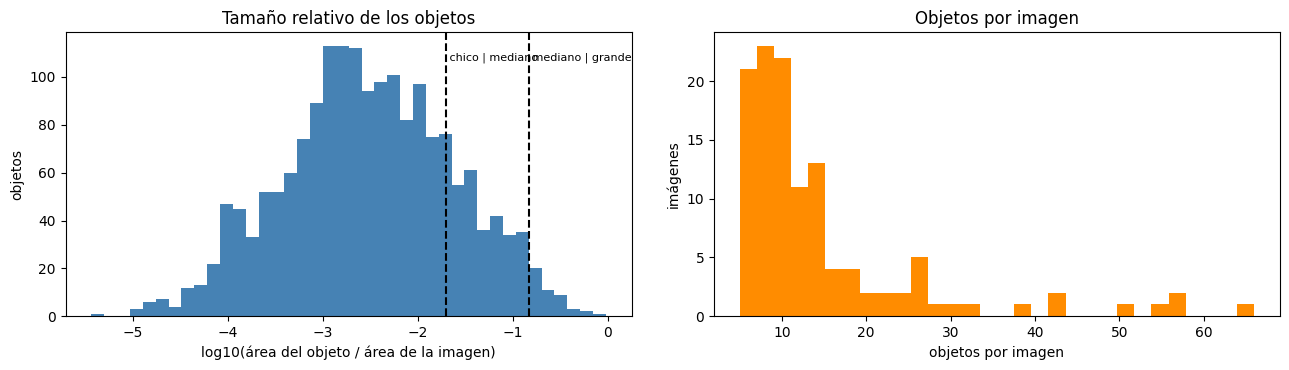

In [16]:
rows = []
for i in dev_ids:
    ref = gt[i]; area = ref["width"] * ref["height"]
    for o in ref["objects"]:
        if o["mask"].any():
            rows.append({"image_id": i, "categoria": categories[o["category_id"]], "area_ratio": o["mask"].sum() / area})
objs = pd.DataFrame(rows)
objs["tamaño"] = objs.area_ratio.map(tc.size_of)
per_image = objs.groupby("image_id").size()
print(f"{len(objs)} objetos anotados; por imagen: media {per_image.mean():.1f}, mediana {per_image.median():.0f}, máximo {per_image.max()}")
print(objs["tamaño"].value_counts(normalize=True).round(3).to_string())
fig, ax = plt.subplots(1, 2, figsize=(13, 3.8))
ax[0].hist(np.log10(objs.area_ratio), bins=40, color="steelblue")
for x, t in [(np.log10(0.02), "chico | mediano"), (np.log10(0.15), "mediano | grande")]:
    ax[0].axvline(x, color="k", ls="--"); ax[0].text(x, ax[0].get_ylim()[1] * 0.9, " " + t, fontsize=8)
ax[0].set(xlabel="log10(área del objeto / área de la imagen)", ylabel="objetos", title="Tamaño relativo de los objetos")
ax[1].hist(per_image, bins=30, color="darkorange"); ax[1].set(xlabel="objetos por imagen", ylabel="imágenes", title="Objetos por imagen")
plt.tight_layout(); plt.show()

**Decisión.** La gran mayoría de los objetos ocupa menos del 2 % de la imagen. Por eso EVA-02 se corre también
sobre recortes 2x2 (cada recorte se agranda a la resolución del modelo), los objetos chicos tienen su propia fuente
de máscara y el recall se mide por tamaño en cada etapa.

**¿Cuántos ejemplos hay por categoría?** Decide si se pueden ajustar parámetros por categoría.

In [17]:
freq = objs.categoria.value_counts()
print(f"categorías con objetos: {len(freq)} de {len(categories)}; con menos de 10 objetos: {(freq < 10).sum()}; "
      f"las 10 más frecuentes suman el {freq.head(10).sum() / len(objs):.0%} de los objetos")
print(freq.head(15).to_string())
imgs_per_cat = objs.groupby("categoria").image_id.nunique()
print(f"imágenes por categoría: mediana {imgs_per_cat.median():.0f}")

categorías con objetos: 120 de 120; con menos de 10 objetos: 36; las 10 más frecuentes suman el 20% de los objetos
categoria
book       46
car        44
chair      40
box        40
wheel      37
pillow     31
shoe       31
curtain    29
person     29
sock       28
cabinet    28
knife      27
bicycle    27
hat        26
lamp       24
imágenes por categoría: mediana 6


**Decisión.** Con pocas imágenes por categoría, un umbral por categoría se sobreajusta: mejora en las imágenes
usadas para elegirlo y no en las otras. Se usan parámetros globales y señales que generalizan entre categorías.

**¿Qué predicciones puede juzgar la métrica?** Anotación federada de LVIS.

In [18]:
meta = pd.DataFrame([{"positivas": len({o["category_id"] for o in gt[i]["objects"]}), "negativas": len(gt[i]["neg"]),
                      "no exhaustivas": len(gt[i]["not_exhaustive"])} for i in dev_ids])
meta["no verificadas"] = len(categories) - meta.positivas - meta.negativas
print(meta.describe().loc[["mean", "50%", "min", "max"]].round(1).to_string())

      positivas  negativas  no exhaustivas  no verificadas
mean        6.4        1.0             0.4           112.6
50%         7.0        1.0             0.0           112.0
min         3.0        0.0             0.0           108.0
max         8.0        4.0             4.0           117.0


**Decisión.** En una imagen típica la mayoría de las 120 categorías no está verificada: una predicción de esas
categorías no suma ni resta en detección. Por eso conviene proponer mucho (recall alto) y se informa la **cobertura
de evaluación** (qué parte de las predicciones juzga la métrica). En las relaciones, en cambio, un objeto de una
categoría no verificada nunca cuenta como acierto (sección 5).

**¿Qué preguntas tiene el benchmark?** Define las operaciones que el motor tiene que soportar.

In [19]:
qdf = pd.DataFrame(questions)
print(qdf.type.value_counts().to_string())
for t in ["count", "existence", "position", "size", "relation"]:
    print(f"- {t}: {qdf[qdf.type == t].question.iloc[0]}")
print("dimensiones de test:", tc.load_test_images()[["width", "height"]].describe().loc[["min", "max"]].to_dict())

type
description    20
count          10
existence      10
relation       10
position        5
size            5
- count: ¿Cuántas instancias de la categoría "pomo de puerta" aparecen en la imagen?
- existence: ¿Hay al menos una instancia de la categoría "tomacorriente" en la imagen?
- position: ¿En qué zona de la imagen está la instancia de "teléfono celular"?
- size: ¿Qué tamaño relativo tiene la instancia de "collar"?
- relation: ¿La instancia de "reloj" está por encima de la instancia de "anillo"?
dimensiones de test: {'width': {'min': 375.0, 'max': 640.0}, 'height': {'min': 304.0, 'max': 640.0}}


**Decisión.** El motor determinista soporta conteo, existencia, posición (grilla 3x3), tamaño relativo y relaciones
izquierda/derecha/arriba/abajo, todo calculado desde las máscaras predichas. Lo demás (color, acciones, materiales)
se responde `unsupported`.

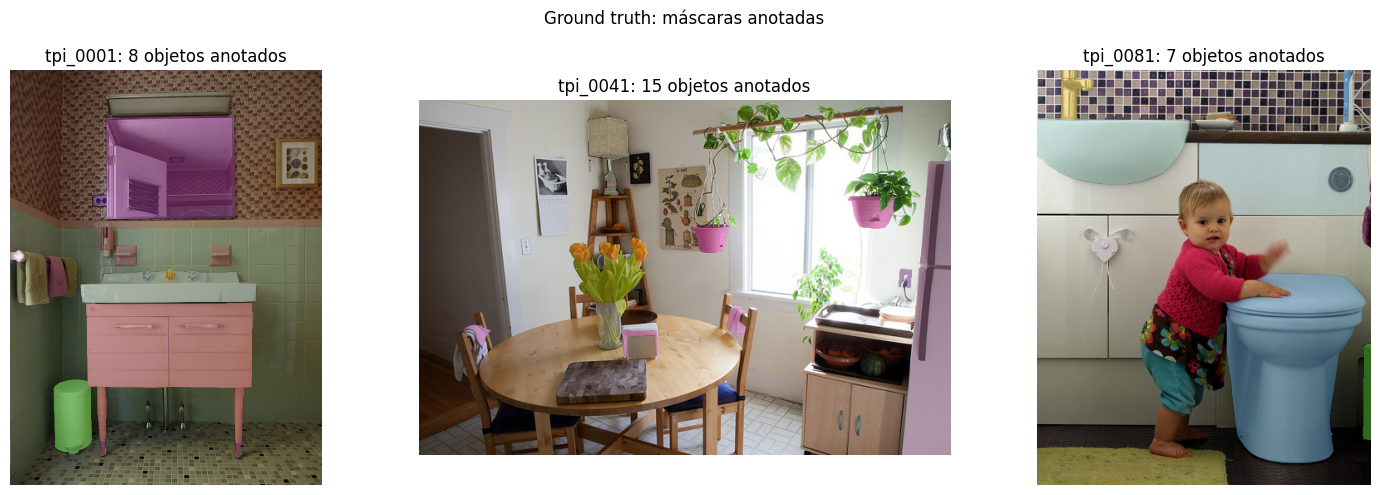

In [20]:
fig, axes = plt.subplots(1, 3, figsize=(16, 5))
for ax, i in zip(axes, [dev_ids[0], dev_ids[40], dev_ids[80]]):
    ax.imshow(images[i]); ax.axis("off")
    overlay = np.zeros((*np.array(images[i]).shape[:2], 4))
    for o in gt[i]["objects"]:
        color = np.random.default_rng(o["category_id"]).random(3)
        overlay[o["mask"]] = [*color, 0.45]
    ax.imshow(overlay); ax.set_title(f"{i}: {len(gt[i]['objects'])} objetos anotados")
plt.suptitle("Ground truth: máscaras anotadas"); plt.tight_layout(); plt.show()

## 2. Detección

Cuatro fuentes de candidatos, todas con un puntaje mínimo bajo (el umbral final se elige después):

- **Grounding DINO base** (vocabulario abierto): las 120 categorías en tandas de 24 nombres. Algunos nombres de LVIS se
  reemplazan por uno que el detector entiende mejor (`tp.PROMPT_NAMES`, por ejemplo cabinet → cupboard).
- **EVA-02-L con ajuste en Objects365** (`eva_o365`): Cascade Mask R-CNN entrenado en las 1203 categorías de LVIS,
  imagen completa a 1536 px. Para los candidatos con puntaje ≥ 0.3 guarda su propia máscara. Además, **recortes 2x2**
  con 25 % de superposición (`eva_o365_2x2`, cada recorte a 1024 px), de los que sólo se guardan las cajas < 5 % de
  la imagen.
- **EVA-02-L sólo LVIS** (`eva_sys`): el mismo detector sin Objects365, como segunda opinión.
- **SAM 3**: segmentación por concepto (una consulta por categoría); da cajas y máscaras.

Las categorías del TPI se buscan en la lista de LVIS v1 por nombre o sinónimo (las 120 tienen equivalente).
Kaggle da dos GPU: EVA-02 corre en la segunda mientras Grounding DINO y SAM 3 usan la primera.

In [21]:
ttr.log("== 2. Detección ==")
tvd.xformers_shim(Path("/tmp/shim"))
sys.path.insert(0, "/tmp/shim")
from PIL import Image as _Image
for old, new in [("LINEAR", "BILINEAR"), ("CUBIC", "BICUBIC"), ("ANTIALIAS", "LANCZOS")]:
    if not hasattr(_Image, old):
        setattr(_Image, old, getattr(_Image.Resampling, new))
for old, new in [("float", float), ("int", int), ("bool", bool), ("object", object), ("str", str)]:
    if old not in np.__dict__:
        setattr(np, old, new)
mapping, missing = tvd.lvis_index(categories)
print(len(mapping), "de", len(categories), "categorías con equivalente en LVIS v1; sin equivalente:", missing)
EVA_DIR = Path("/tmp/eva/EVA-02/det")
N_GPU = torch.cuda.device_count()
EVA_DEVICE = "cuda:1" if N_GPU > 1 else "cuda:0"
print(f"GPU disponibles: {N_GPU} | EVA-02 en {EVA_DEVICE}")


def eva_pass(model, key, label, **kw):
    t0 = time.time()
    out = {}
    for i in ttr.progress(all_ids, f"{label}: {key}"):
        w, h = images[i].size
        with tracer.stage("deteccion", i, fuente=key, modelo=label) as rec:
            cands = (tvd.detect_tiled(model, images[i], mapping, max_ratio=0.05, min_score=0.02, short_edge=1024)
                     if key.endswith("_2x2") else tvd.detect(model, images[i], mapping, min_score=0.02, short_edge=1536, **kw))
            out[i] = {"width": w, "height": h, "candidates": cands}
            rec["salida"] = {"candidatos": len(cands), "con_mascara": sum("mask_vitdet" in c for c in cands)}
    src[key] = out
    print(f"{key}: {(time.time() - t0) / len(all_ids):.1f} s por imagen", flush=True)


EVA_PLAN = [("eva_o365", "EVA-02-L LVIS + O365", [("eva_o365", {"with_masks": True}), ("eva_o365_2x2", {})]),
            ("eva_sys", "EVA-02-L LVIS", [("eva_sys", {})])]
eva_error = []


def eva_branch():
    try:
        for name, label, passes in EVA_PLAN:
            model = tvd.load_eva(EVA_DIR, name, device=EVA_DEVICE)
            for key, kw in passes:
                eva_pass(model, key, label, **kw)
            model = None; gc.collect(); torch.cuda.empty_cache()
    except Exception as exc:
        eva_error.append(exc)
        raise


src = {}  # lo completan los dos hilos, cada uno con sus propias claves
eva_thread = threading.Thread(target=eva_branch, name="eva02") if N_GPU > 1 else None
if eva_thread:
    eva_thread.start()

d = tdet.load("gdino_base")
prepared = tdet.prepare(d, categories)
src["gdino"] = {}
t0 = time.time()
for i in ttr.progress(all_ids, "Grounding DINO"):
    w, h = images[i].size
    with tracer.stage("deteccion", i, fuente="gdino", modelo=d.spec["id"]) as rec:
        cands = tdet.detect(d, images[i], prepared)
        src["gdino"][i] = {"width": w, "height": h, "candidates": cands}
        rec["salida"] = {"candidatos": len(cands)}
print(f"Grounding DINO: {(time.time() - t0) / len(all_ids):.1f} s por imagen", flush=True)
d = None; gc.collect(); torch.cuda.empty_cache()

s3 = ts3.Sam3(ts3.download(), categories, {c: tp.PROMPT_NAMES.get(n, n).lower() for c, n in categories.items()})
src["sam3"] = {}
t0 = time.time()
for i in ttr.progress(all_ids, "SAM 3 (120 categorías por imagen)"):
    w, h = images[i].size
    with tracer.stage("deteccion", i, fuente="sam3", modelo=f"{ts3.REPO}@{ts3.REVISION[:12]}") as rec:
        cands = s3.detect(images[i])
        src["sam3"][i] = {"width": w, "height": h, "candidates": cands}
        rec["salida"] = {"candidatos": len(cands), "con_mascara": sum("mask_sam3" in c for c in cands)}
print(f"SAM 3: {(time.time() - t0) / len(all_ids):.1f} s por imagen", flush=True)
s3 = None; gc.collect(); torch.cuda.empty_cache()

if eva_thread:
    eva_thread.join()
    if eva_error:  # si la rama en paralelo falla, se repite en la primera GPU
        print(f"EVA-02 en {EVA_DEVICE} falló ({type(eva_error[0]).__name__}: {eva_error[0]}); se repite en cuda:0", flush=True)
        EVA_DEVICE = "cuda:0"
        eva_error.clear()
        eva_branch()
else:
    eva_branch()
for key, raw in src.items():
    tp.save_raw(raw, WORK / f"det_{key}.json.gz")
    tracer.artifact(WORK / f"det_{key}.json.gz", f"candidatos de {key}")
print({k: round(np.mean([len(v[i]["candidates"]) for i in dev_ids])) for k, v in src.items()}, "candidatos por imagen")

[0:00:07] == 2. Detección ==
120 de 120 categorías con equivalente en LVIS v1; sin equivalente: []
GPU disponibles: 2 | EVA-02 en cuda:1


/usr/local/lib/python3.13/dist-packages/timm/models/layers/__init__.py:49: FutureWarning: Importing from timm.models.layers is deprecated, please import via timm.layers
  warnings.warn(f"Importing from {__name__} is deprecated, please import via timm.layers", FutureWarning)
/usr/local/lib/python3.13/dist-packages/detectron2/config/lazy.py:154: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  return old_import(name, globals, locals, fromlist=fromlist, level=level)


======== shape of rope freq torch.Size([256, 64]) ========
======== shape of rope freq torch.Size([9216, 64]) ========


[0:00:29] Grounding DINO: empieza (180)


eva_o365: claves del archivo ['ema_state', 'model']
eva_o365: faltan 48 pesos, sobran 5 ['backbone.net.blocks.0.attn.rope.freqs_cos', 'backbone.net.blocks.0.attn.rope.freqs_sin', 'backbone.net.blocks.1.attn.rope.freqs_cos', 'backbone.net.blocks.1.attn.rope.freqs_sin', 'backbone.net.blocks.2.attn.rope.freqs_cos']
[0:00:47] EVA-02-L LVIS + O365: eva_o365: empieza (180)


/usr/local/lib/python3.13/dist-packages/torch/functional.py:505: UserWarning: torch.meshgrid: in an upcoming release, it will be required to pass the indexing argument. (Triggered internally at /pytorch/aten/src/ATen/native/TensorShape.cpp:4381.)
  return _VF.meshgrid(tensors, **kwargs)  # type: ignore[attr-defined]
W1020 17:02:03.580000 22 torch/fx/_symbolic_trace.py:53] is_fx_tracing will return true for both fx.symbolic_trace and torch.export. Please use is_fx_tracing_symbolic_tracing() for specifically fx.symbolic_trace or torch.compiler.is_compiling() for specifically torch.export/compile.


[0:01:32] Grounding DINO: 18/180 (10%) · 1.1 min · faltan ~9.5 min
[0:01:45] EVA-02-L LVIS + O365: eva_o365: 18/180 (10%) · 1.0 min · faltan ~8.6 min
[0:02:33] Grounding DINO: 36/180 (20%) · 2.1 min · faltan ~8.3 min
[0:02:47] EVA-02-L LVIS + O365: eva_o365: 36/180 (20%) · 2.0 min · faltan ~8.0 min
[0:03:38] Grounding DINO: 54/180 (30%) · 3.1 min · faltan ~7.3 min
[0:03:54] EVA-02-L LVIS + O365: eva_o365: 54/180 (30%) · 3.1 min · faltan ~7.2 min
[0:04:40] Grounding DINO: 72/180 (40%) · 4.2 min · faltan ~6.3 min
[0:05:00] EVA-02-L LVIS + O365: eva_o365: 72/180 (40%) · 4.2 min · faltan ~6.3 min
[0:05:42] Grounding DINO: 90/180 (50%) · 5.2 min · faltan ~5.2 min
[0:06:05] EVA-02-L LVIS + O365: eva_o365: 90/180 (50%) · 5.3 min · faltan ~5.3 min
[0:06:44] Grounding DINO: 108/180 (60%) · 6.3 min · faltan ~4.2 min
[0:07:11] EVA-02-L LVIS + O365: eva_o365: 108/180 (60%) · 6.4 min · faltan ~4.3 min
[0:07:48] Grounding DINO: 126/180 (70%) · 7.3 min · faltan ~3.1 min
[0:08:16] EVA-02-L LVIS + O365

[transformers] `memory_attention_rope_theta` is deprecated and will be removed in v5.0. Use `rope_parameters['rope_theta']` instead.


[0:11:23] SAM 3 (120 categorías por imagen): empieza (180)
[0:11:32] EVA-02-L LVIS + O365: eva_o365: 180/180 (100%) · 10.7 min · faltan ~0.0 min
eva_o365: 3.6 s por imagen
[0:11:32] EVA-02-L LVIS + O365: eva_o365_2x2: empieza (180)
[0:14:15] SAM 3 (120 categorías por imagen): 18/180 (10%) · 2.9 min · faltan ~25.8 min
[0:15:39] EVA-02-L LVIS + O365: eva_o365_2x2: 18/180 (10%) · 4.1 min · faltan ~36.9 min
[0:17:08] SAM 3 (120 categorías por imagen): 36/180 (20%) · 5.7 min · faltan ~23.0 min
[0:19:46] EVA-02-L LVIS + O365: eva_o365_2x2: 36/180 (20%) · 8.2 min · faltan ~32.9 min
[0:20:01] SAM 3 (120 categorías por imagen): 54/180 (30%) · 8.6 min · faltan ~20.1 min
[0:22:55] SAM 3 (120 categorías por imagen): 72/180 (40%) · 11.5 min · faltan ~17.3 min
[0:23:55] EVA-02-L LVIS + O365: eva_o365_2x2: 54/180 (30%) · 12.4 min · faltan ~28.9 min
[0:25:48] SAM 3 (120 categorías por imagen): 90/180 (50%) · 14.4 min · faltan ~14.4 min
[0:28:04] EVA-02-L LVIS + O365: eva_o365_2x2: 72/180 (40%) · 16.5 

eva_sys: claves del archivo ['model']
eva_sys: faltan 0 pesos, sobran 3 []
[0:53:08] EVA-02-L LVIS: eva_sys: empieza (180)
[0:54:16] EVA-02-L LVIS: eva_sys: 18/180 (10%) · 1.1 min · faltan ~10.2 min
[0:55:23] EVA-02-L LVIS: eva_sys: 36/180 (20%) · 2.2 min · faltan ~9.0 min
[0:56:31] EVA-02-L LVIS: eva_sys: 54/180 (30%) · 3.4 min · faltan ~7.9 min
[0:57:37] EVA-02-L LVIS: eva_sys: 72/180 (40%) · 4.5 min · faltan ~6.7 min
[0:58:44] EVA-02-L LVIS: eva_sys: 90/180 (50%) · 5.6 min · faltan ~5.6 min
[0:59:52] EVA-02-L LVIS: eva_sys: 108/180 (60%) · 6.7 min · faltan ~4.5 min
[1:00:59] EVA-02-L LVIS: eva_sys: 126/180 (70%) · 7.8 min · faltan ~3.4 min
[1:02:06] EVA-02-L LVIS: eva_sys: 144/180 (80%) · 9.0 min · faltan ~2.2 min
[1:03:13] EVA-02-L LVIS: eva_sys: 162/180 (90%) · 10.1 min · faltan ~1.1 min
[1:04:20] EVA-02-L LVIS: eva_sys: 180/180 (100%) · 11.2 min · faltan ~0.0 min
eva_sys: 3.7 s por imagen
{'gdino': 155, 'sam3': 258, 'eva_o365': 126, 'eva_o365_2x2': 171, 'eva_sys': 112} candidatos

### Cada detector por separado (F1 de cajas, IoU ≥ 0.5, política LVIS)

Cada fuente con su umbral, elegido en una mitad y medido en la otra; en las combinaciones, la unión de los candidatos
con un umbral por fuente. Es la referencia sin re-puntaje para la sección 3.

In [22]:
TH = [0.10, 0.14, 0.18, 0.22, 0.26, 0.30, 0.34, 0.38, 0.44, 0.50]


def union_f1(raws, label):
    cache = {}
    def f1_on(th, ids_):
        key = tuple(sorted(th.items()))
        if key not in cache:
            fused = te.fuse(raws, dev_ids, th, rule="unión")
            cache[key] = (fused, *tt.label_candidates(fused, gt, dev_ids, "detector"))
        _, labels, gtc = cache[key]
        return tt.micro_f1(labels[labels.image_id.isin(ids_)], gtc[gtc.image_id.isin(ids_)], 0.0)
    unseen = []
    for k in range(2):
        th, _ = te.fit_thresholds(lambda t: f1_on(t, folds[k])["f1"], list(raws), TH)
        unseen.append(f1_on(th, folds[1 - k]))
    th_all, _ = te.fit_thresholds(lambda t: f1_on(t, dev_ids)["f1"], list(raws), TH)
    fused = te.fuse(raws, dev_ids, th_all, rule="unión")
    diag = td.diagnose_objects(fused, gt, dev_ids, 0.0, "detector")
    found = diag.assign(ok=diag.estado == "encontrado").groupby("tamaño").ok.mean()
    tp_, fp_ = sum(u["tp"] for u in unseen), sum(u["fp"] for u in unseen)
    return {"variante": label, "F1 no vistas": round(np.mean([u["f1"] for u in unseen]), 4),
            "precisión": round(tp_ / max(tp_ + fp_, 1), 3), "recall": round(tp_ / (tp_ + sum(u["fn"] for u in unseen)), 3),
            "chicos": round(found.get("small", 0), 3), "medianos": round(found.get("medium", 0), 3),
            "grandes": round(found.get("large", 0), 3), "umbrales (120)": th_all}


det_exp = pd.DataFrame([
    union_f1({"gdino": src["gdino"]}, "Grounding DINO base"),
    union_f1({"sam3": src["sam3"]}, "SAM 3"),
    union_f1({"eva_sys": src["eva_sys"]}, "EVA-02-L (LVIS)"),
    union_f1({"eva_o365": src["eva_o365"]}, "EVA-02-L (LVIS + Objects365)"),
    union_f1({k: src[k] for k in ["eva_o365", "eva_o365_2x2"]}, "EVA-02-L (O365) + recortes 2x2"),
    union_f1({k: src[k] for k in ["gdino", "eva_o365", "eva_o365_2x2"]}, "Grounding DINO + EVA-02-L + recortes"),
])
print(det_exp.drop(columns="umbrales (120)").to_string(index=False))
det_exp.to_csv(WORK / "experimentos_deteccion.csv", index=False)

                            variante  F1 no vistas  precisión  recall  chicos  medianos  grandes
                 Grounding DINO base        0.5939      0.639   0.555   0.501     0.814    0.933
                               SAM 3        0.7157      0.790   0.653   0.639     0.811    0.933
                     EVA-02-L (LVIS)        0.7794      0.788   0.771   0.764     0.845    0.911
        EVA-02-L (LVIS + Objects365)        0.7866      0.799   0.775   0.792     0.911    0.933
      EVA-02-L (O365) + recortes 2x2        0.7887      0.773   0.805   0.806     0.900    0.911
Grounding DINO + EVA-02-L + recortes        0.7968      0.793   0.801   0.782     0.911    0.933


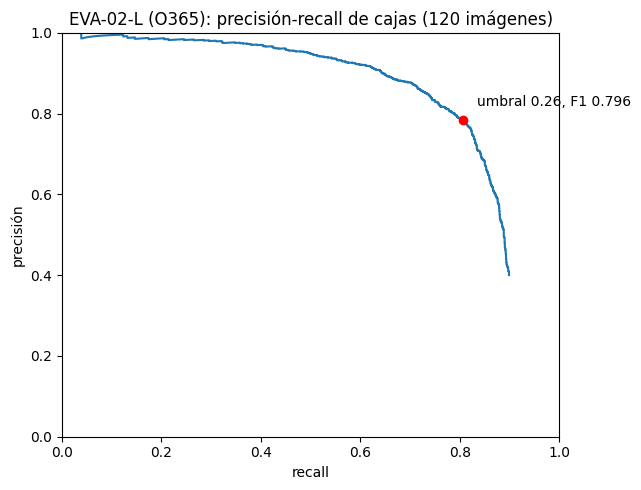

No hay curva ROC: en detección no existen verdaderos negativos (cualquier región sin objeto lo sería).


In [23]:
labels_e, gtc_e = tt.label_candidates(src["eva_o365"], gt, dev_ids, "detector")
curve = tt.pr_curve(labels_e, int(gtc_e.n_gt.sum()))
best = curve.iloc[curve.f1.idxmax()]
fig, ax = plt.subplots(figsize=(6.5, 5))
ax.plot(curve.recall, curve.precision); ax.scatter(best.recall, best.precision, color="red", zorder=3)
ax.annotate(f"umbral {best.threshold:.2f}, F1 {best.f1:.3f}", (best.recall, best.precision), xytext=(10, 10), textcoords="offset points")
ax.set(xlabel="recall", ylabel="precisión", xlim=(0, 1), ylim=(0, 1), title="EVA-02-L (O365): precisión-recall de cajas (120 imágenes)")
plt.tight_layout(); plt.show()
print("No hay curva ROC: en detección no existen verdaderos negativos (cualquier región sin objeto lo sería).")

**Lectura.** En la versión 13, EVA-02 (O365) solo dio 0.787, más que ViTDet-H con Grounding DINO y recortes (0.773)
y que la unión de Grounding DINO y OWLv2 (0.660). Los recortes suben el recall de objetos chicos y Grounding DINO
suma casi un punto más (0.789 → 0.797). Una unión con umbrales fijos no aprovecha del todo las fuentes: eso lo hace
el re-puntaje.

## 3. Re-puntaje aprendido de candidatos

**Idea.** Muchos objetos tienen un candidato correcto con puntaje bajo, mezclado con falsos. Señales que el puntaje
solo no tiene separan mejor aciertos de falsos: ¿lo propone más de una fuente?, ¿lo vio un recorte?, ¿compite con
otra categoría en el mismo lugar?, su tamaño y forma, el **contexto** (un objeto contenedor confiable y su categoría:
una perilla dentro de un mueble, un botón sobre una camisa) y la **apariencia** (convoluciones simples: bordes Sobel,
contraste y color contra un anillo alrededor, manchas con Laplaciano de Gaussiana a la escala de la caja).

**Etiqueta.** 1 si la caja coincide (IoU ≥ 0.5) con un objeto real de su categoría, 0 si la métrica la contaría como
falsa; las que la métrica ignoraría (categoría no verificada) no se usan para entrenar.

**Selección por pasos.** Cada paso parte de lo elegido en el anterior y prueba alternativas, siempre midiendo F1 de
cajas en la mitad no usada para entrenar. Una alternativa reemplaza a la actual sólo si gana por más de 0.002.

| Paso | Qué se decide |
|---|---|
| A | qué fuentes entran |
| C | un clasificador o uno para cajas chicas y otro para el resto |
| D | señales de contexto y de apariencia |
| E, H | suprimir duplicados (NMS) o promediarlos (WBF), y con qué IoU |
| F | hiperparámetros del clasificador |
| J | Soft-NMS: bajar el puntaje de los duplicados en lugar de borrarlos |
| K | mezclar el clasificador con árboles extremos (otro algoritmo, otros errores) |
| L | si quedó Soft-NMS, su sigma con el clasificador elegido |

In [24]:
ttr.log("== 3. Re-puntaje ==")
GRID = np.round(np.arange(0.05, 0.91, 0.01), 2)
CAT_INDEX = {c: k for k, c in enumerate(sorted(categories))}


def unseen_f1(raw):
    labels, gtc = tt.label_candidates(raw, gt, dev_ids, "detector")
    out, ths = [], []
    for k in range(2):
        la, ga = labels[labels.image_id.isin(folds[k])], gtc[gtc.image_id.isin(folds[k])]
        th = max(GRID, key=lambda t: tt.micro_f1(la, ga, t)["f1"])
        out.append(tt.micro_f1(labels[labels.image_id.isin(folds[1 - k])], gtc[gtc.image_id.isin(folds[1 - k])], th)["f1"])
        ths.append(float(th))
    return float(np.mean(out)), out, ths


def found_by_size(raw, th):
    diag = td.diagnose_objects(raw, gt, dev_ids, th, "detector")
    return diag.assign(ok=diag.estado == "encontrado").groupby("tamaño").ok.mean().round(3).to_dict()


def only_large(raw, min_ratio):
    return {i: {**e, "candidates": [c for c in e["candidates"] if (c["box"][2] - c["box"][0]) * (c["box"][3] - c["box"][1])
                                    / (e["width"] * e["height"]) >= min_ratio]} for i, e in raw.items()}


def features(pooled_v, ids, sources, extras, with_labels):
    X, y, g = tr.dataset(pooled_v, gt if with_labels else None, ids, sources)
    names, cat_mask = tr.feature_names(sources), [False] * X.shape[1]
    if "contexto" in extras:
        X = np.hstack([X, np.vstack([tr.context_features(pooled_v[i], CAT_INDEX) for i in ids])])
        names, cat_mask = names + tr.context_feature_names(), cat_mask + [True, True, False, False, False]
    if "apariencia" in extras:
        X = np.hstack([X, np.vstack([tr.signal_features(images[i], pooled_v[i]) for i in ids])])
        names, cat_mask = names + tr.signal_feature_names(), cat_mask + [False] * 4
    return X, y, g, names, (np.array(cat_mask) if any(cat_mask) else None)


MIXES = {"mezcla 0.5 + 0.5 con árboles extremos (mín. 20 por hoja)": 20,
         "mezcla 0.5 + 0.5 con árboles extremos (mín. 10 por hoja)": 10}


def fusion_kw(fusion, param):
    return {} if param is None else ({"wbf_iou": param} if fusion == "wbf" else {"sigma": param} if fusion == "soft" else {"nms_iou": param})


_feat_cache = {}


def run_variant(src_v, rescorer="un modelo", extras=(), fusion="nms", params=None, iou=None):
    sources = list(src_v)
    key = (tuple((k, id(v)) for k, v in src_v.items()), tuple(extras))
    if key not in _feat_cache:  # los pasos que no cambian fuentes ni señales reusan la misma tabla
        pooled_v = tr.pool(src_v, all_ids)
        _feat_cache.clear(); _feat_cache[key] = (pooled_v, *features(pooled_v, dev_ids, sources, extras, True))
    pooled_v, Xd, yd, gd, names, categorical = _feat_cache[key]
    params = dict(params or {})
    make = ((lambda: tr.SizeSplit(SEED, categorical, 0.02, params)) if rescorer == "un modelo por tamaño"
            else (lambda: tr.MixET(SEED, categorical, params, MIXES[rescorer])) if rescorer in MIXES
            else (lambda: tr.make_model(SEED, categorical, **params)))
    probs = np.zeros(len(yd))
    for k in range(2):
        fit_rows = np.isin(gd, folds[k]) & (yd >= 0)
        test_rows = np.isin(gd, folds[1 - k])
        probs[test_rows] = make().fit(Xd[fit_rows], yd[fit_rows]).predict_proba(Xd[test_rows])[:, 1]
    raw_v = tr.rescored(pooled_v, dev_ids, probs, fusion=fusion, **fusion_kw(fusion, iou))
    f1, halves, ths = unseen_f1(raw_v)
    row = {"F1 no vistas": round(f1, 4), "mitad 1": round(halves[0], 4), "mitad 2": round(halves[1], 4),
           **found_by_size(raw_v, float(np.mean(ths)))}
    run = dict(src_v=src_v, rescorer=rescorer, extras=extras, fusion=fusion, params=params, iou=iou, sources=sources,
               pooled=pooled_v, X=Xd, y=yd, g=gd, names=names, make=make, probs=probs)
    return row, run


MIN_GAIN = 0.002
steps = []


def step(title, variants):
    ttr.log(f"{title}: {len(variants)} variantes")
    results = {}
    for name, kw in variants.items():
        t0 = time.time()
        results[name] = run_variant(**kw)
        print(f"  {title} | {name}: {results[name][0]} ({time.time() - t0:.0f} s)", flush=True)
    first = next(iter(results))
    best = max(results, key=lambda n: results[n][0]["F1 no vistas"])
    if results[best][0]["F1 no vistas"] <= results[first][0]["F1 no vistas"] + MIN_GAIN:
        best = first
    for name, (row, _) in results.items():
        steps.append({"paso": title, "variante": name, "elegida": name == best, **row})
    run = results[best][1]
    return {k: run[k] for k in ["src_v", "rescorer", "extras", "fusion", "params", "iou"]}, run


eva_src = {k: src[k] for k in ["gdino", "eva_o365", "eva_o365_2x2"]}
cur, run = step("A. fuentes", {
    "gdino + eva_o365 + eva_o365_2x2": {"src_v": eva_src},
    "gdino + eva_o365 + eva_sys + eva_o365_2x2": {"src_v": {**eva_src, "eva_sys": src["eva_sys"]}},
    "gdino + eva_o365 + eva_sys + eva_o365_2x2 + sam3 (cajas >= 2 %)": {"src_v": {**eva_src, "eva_sys": src["eva_sys"],
                                                                                   "sam3": only_large(src["sam3"], 0.02)}}})
cur, run = step("C. modelo de re-puntaje", {"un modelo": dict(cur), "un modelo por tamaño": {**cur, "rescorer": "un modelo por tamaño"}})
cur, run = step("D. señales extra", {"sólo detección": dict(cur), "+ contexto": {**cur, "extras": ("contexto",)},
                                     "+ apariencia (convoluciones)": {**cur, "extras": ("apariencia",)},
                                     "+ contexto y apariencia": {**cur, "extras": ("contexto", "apariencia")}})
cur, run = step("E. fusión de duplicados", {"NMS": dict(cur), "WBF": {**cur, "fusion": "wbf"}})
cur, run = step("F. hiperparámetros del clasificador", {
    "actuales (lr 0.05, 300 it., 15 hojas, mín. 40, L2 1)": dict(cur),
    "lr 0.1, 150 iteraciones": {**cur, "params": {"learning_rate": 0.1, "max_iter": 150}},
    "lr 0.03, 500 iteraciones": {**cur, "params": {"learning_rate": 0.03, "max_iter": 500}},
    "7 hojas": {**cur, "params": {"max_leaf_nodes": 7}}, "31 hojas": {**cur, "params": {"max_leaf_nodes": 31}},
    "mín. 20 por hoja": {**cur, "params": {"min_samples_leaf": 20}}, "mín. 80 por hoja": {**cur, "params": {"min_samples_leaf": 80}},
    "L2 0": {**cur, "params": {"l2_regularization": 0.0}}, "L2 5": {**cur, "params": {"l2_regularization": 5.0}}})
ious = [0.45, 0.65] if cur["fusion"] == "wbf" else [0.4, 0.6]
cur, run = step("H. IoU de la fusión de duplicados", {
    f"actual ({0.55 if cur['fusion'] == 'wbf' else 0.5})": dict(cur), **{f"IoU {v}": {**cur, "iou": v} for v in ious}})
if cur["fusion"] == "nms":
    cur, run = step("J. Soft-NMS", {"actual (NMS)": dict(cur),
                                    **{f"Soft-NMS gaussiano, sigma {v}": {**cur, "fusion": "soft", "iou": v} for v in [0.2, 0.3, 0.5]}})
if cur["rescorer"] == "un modelo":
    cur, run = step("K. mezcla con árboles extremos", {"actual (un modelo)": dict(cur), **{n: {**cur, "rescorer": n} for n in MIXES}})
if cur["fusion"] == "soft":
    cur, run = step("L. sigma del Soft-NMS con el re-puntaje elegido", {
        f"actual (sigma {cur['iou']})": dict(cur), **{f"sigma {v}": {**cur, "iou": v} for v in [0.15, 0.2, 0.3, 0.4] if v != cur["iou"]}})
e3 = pd.DataFrame(steps)
print(e3.to_string(index=False))
print(f"referencia sin re-puntaje (unión con umbral por fuente): {det_exp['F1 no vistas'].max():.4f}")
e3.to_csv(WORK / "experimento_repuntaje.csv", index=False)

SOURCES, FUSION, FUSION_KW = run["sources"], run["fusion"], fusion_kw(run["fusion"], run["iou"])
CONFIG["repuntaje"].update(fuentes=SOURCES, modelo=run["rescorer"], senales_extra=list(run["extras"]), fusion=FUSION,
                           iou_fusion=run["iou"], recortes="todas las cajas",
                           hiperparametros={**tr.HGB_PARAMS, **run["params"]})
print("elegido:", CONFIG["repuntaje"])

pooled, X_dev, y_dev, g_dev, make_rescorer, probs_dev = run["pooled"], run["X"], run["y"], run["g"], run["make"], run["probs"]
X_test, _, _, _, _ = features(pooled, test_ids, SOURCES, run["extras"], False)
NAMES = run["names"]

[1:04:57] == 3. Re-puntaje ==
[1:04:57] A. fuentes: 3 variantes
  A. fuentes | gdino + eva_o365 + eva_o365_2x2: {'F1 no vistas': 0.7788, 'mitad 1': 0.7638, 'mitad 2': 0.7937, 'large': 0.933, 'medium': 0.911, 'small': 0.733} (6 s)
  A. fuentes | gdino + eva_o365 + eva_sys + eva_o365_2x2: {'F1 no vistas': 0.7762, 'mitad 1': 0.7661, 'mitad 2': 0.7863, 'large': 0.933, 'medium': 0.914, 'small': 0.747} (6 s)
  A. fuentes | gdino + eva_o365 + eva_sys + eva_o365_2x2 + sam3 (cajas >= 2 %): {'F1 no vistas': 0.7809, 'mitad 1': 0.7758, 'mitad 2': 0.786, 'large': 0.978, 'medium': 0.928, 'small': 0.757} (7 s)
[1:05:17] C. modelo de re-puntaje: 2 variantes
  C. modelo de re-puntaje | un modelo: {'F1 no vistas': 0.7809, 'mitad 1': 0.7758, 'mitad 2': 0.786, 'large': 0.978, 'medium': 0.928, 'small': 0.757} (5 s)
  C. modelo de re-puntaje | un modelo por tamaño: {'F1 no vistas': 0.7678, 'mitad 1': 0.7724, 'mitad 2': 0.7632, 'large': 0.956, 'medium': 0.942, 'small': 0.721} (6 s)
[1:05:27] D. señales extra

**Probabilidad de "objeto anotado".** Para las relaciones (sección 5) importa otra cosa: la métrica sólo cuenta una
relación si sus dos objetos coinciden con objetos *anotados*. Un segundo clasificador, con las mismas señales
(incluida la categoría: algunas casi siempre se anotan), estima esa probabilidad; acá las cajas de categorías no
anotadas en la imagen cuentan como 0. También fuera de muestra en desarrollo.

**Modelos finales.** Con la configuración elegida se entrena un re-puntaje con las 120 imágenes (para el test) y otro
con las 100 que no son del benchmark de preguntas (para esas 20).

In [25]:
from sklearn.metrics import roc_auc_score
y_match = (y_dev == 1).astype(int)
CAT_M = np.array([n in ("categoria", "categoria_contenedor") for n in NAMES])
make_match = lambda: tr.make_model(SEED, CAT_M if CAT_M.any() else None)
p_match_dev = np.zeros(len(y_dev))
for k in range(2):
    rows = np.isin(g_dev, folds[1 - k])
    p_match_dev[rows] = make_match().fit(X_dev[np.isin(g_dev, folds[k])], y_match[np.isin(g_dev, folds[k])]).predict_proba(X_dev[rows])[:, 1]
m_match = make_match().fit(X_dev, y_match)
p_match_test = m_match.predict_proba(X_test)[:, 1]
print(f"'objeto anotado': AUC fuera de muestra {roc_auc_score(y_match, p_match_dev):.3f}; "
      f"{y_match.mean():.1%} de los candidatos corresponden a un objeto anotado")


def attach_match(ids, p):
    k = 0
    for i in ids:
        for c in pooled[i]["candidates"]:
            c["p_match"] = float(p[k])
            k += 1


attach_match(dev_ids, p_match_dev)
attach_match(test_ids, p_match_test)


def fit(train_ids, label):
    with tracer.stage("repuntaje_entrenamiento", None, entrenado_con=label, imagenes=len(train_ids)) as rec:
        rows = np.isin(g_dev, train_ids) & (y_dev >= 0)
        model = make_rescorer().fit(X_dev[rows], y_dev[rows])
        rec["salida"] = {"filas": int(rows.sum()), "positivos": int(y_dev[rows].sum())}
    return model


m_bench = fit([i for i in dev_ids if i not in qa_by_image], "las 100 de desarrollo sin benchmark")
m_all = fit(dev_ids, "las 120 de desarrollo")
bench_rows = np.isin(g_dev, bench_ids)
dev_raw = tr.rescored(pooled, dev_ids, probs_dev, fusion=FUSION, **FUSION_KW)
bench_raw = tr.rescored(pooled, bench_ids, m_bench.predict_proba(X_dev[bench_rows])[:, 1], fusion=FUSION, **FUSION_KW)
test_raw = tr.rescored(pooled, test_ids, m_all.predict_proba(X_test)[:, 1], fusion=FUSION, **FUSION_KW)
with open(WORK / "repuntaje_modelos.pkl", "wb") as f:
    pickle.dump({"test": m_all, "benchmark": m_bench, "anotado": m_match, "config": CONFIG["repuntaje"], "senales": NAMES}, f)
tracer.artifact(WORK / "repuntaje_modelos.pkl", "modelos de re-puntaje y de 'objeto anotado'")

'objeto anotado': AUC fuera de muestra 0.876; 12.3% de los candidatos corresponden a un objeto anotado


In [26]:
from sklearn.inspection import permutation_importance
from sklearn.metrics import average_precision_score
rows_a, rows_b = np.isin(g_dev, folds[0]) & (y_dev >= 0), np.isin(g_dev, folds[1]) & (y_dev >= 0)
m = make_rescorer().fit(X_dev[rows_a], y_dev[rows_a])
sel = np.random.default_rng(SEED).choice(np.where(rows_b)[0], min(20000, rows_b.sum()), replace=False)
imp = permutation_importance(m, X_dev[sel], y_dev[sel], n_repeats=3, random_state=SEED,
                             scoring=lambda est, Xs, ys: average_precision_score(ys, est.predict_proba(Xs)[:, 1]))
print("importancia de cada señal (caída de la precisión promedio al desordenarla):")
print(pd.Series(imp.importances_mean, index=NAMES).sort_values(ascending=False).round(4).head(15).to_string())

importancia de cada señal (caída de la precisión promedio al desordenarla):
acuerdo_eva_o365             0.0438
acuerdo_eva_sys              0.0334
puntaje                      0.0280
acuerdo_sam3                 0.0123
acuerdo_eva_o365_2x2         0.0111
categoria                    0.0054
acuerdo_gdino                0.0042
n_misma_categoria            0.0014
fuente=eva_sys               0.0010
blob_LoG                     0.0006
mejor_otra_categoria         0.0005
log_area                     0.0005
borde_dentro_vs_alrededor    0.0003
log_tamano_vs_contenedor     0.0003
diferencia_color             0.0003


## 4. Segmentación con SAM2

Cada caja con P(acierto) ≥ 0.15 se usa como prompt de SAM2 (una máscara por caja); si SAM2 devuelve una máscara vacía
se usa la caja. Para las cajas chicas se calcula además una máscara con SAM2 sobre recortes 2x2 de la imagen (el doble
de resolución). Qué máscara queda para cada objeto se decide en la sección 5 (E6). Las máscaras se guardan como RLE
sin comprimir en orden column-major.

In [27]:
ttr.log("== 4. Segmentación (SAM2) ==")
for raw in (dev_raw, bench_raw, test_raw):
    for e in raw.values():
        e["candidates"] = [c for c in e["candidates"] if c["score"] >= CONFIG["sam_min_score"]]
from transformers import Sam2Model, Sam2Processor
sam = SimpleNamespace(torch=torch, device="cuda", sam_processor=Sam2Processor.from_pretrained(tp.SAM2_ID),
                      sam=Sam2Model.from_pretrained(tp.SAM2_ID).to("cuda").eval())
SAM_MIN = CONFIG["sam_min_score"]
ZOOM_MIN = 0.30


def box_ratio(c, e):
    return (c["box"][2] - c["box"][0]) * (c["box"][3] - c["box"][1]) / (e["width"] * e["height"])


def add_masks(raw, ids, label):
    for i in ttr.progress(ids, f"SAM2 ({label})"):
        e = raw[i]
        with tracer.stage("segmentacion", i, conjunto=label, min_score=SAM_MIN) as rec:
            cands = sorted((c for c in e["candidates"] if c["score"] >= SAM_MIN), key=lambda c: -c["score"])[:300]
            if cands:
                masks, scores = tp.segment(sam, images[i], [c["box"] for c in cands])
                for c, mk, s in zip(cands, masks, scores):
                    if not mk.any():
                        mk = tp.box_mask(c["box"], e["height"], e["width"])
                    c["sam_score"], c["mask"] = float(s), tc.mask_to_rle(mk)
            e["candidates"] = cands
            rec["salida"] = {"segmentados": len(cands)}


def add_zoom_masks(raw, ids, label):
    for i in ttr.progress(ids, f"SAM2 ampliado ({label})"):
        e = raw[i]
        small = [c for c in e["candidates"] if c["score"] >= ZOOM_MIN and box_ratio(c, e) < 0.02]
        with tracer.stage("segmentacion_ampliada", i, conjunto=label, min_score=ZOOM_MIN, recortes="2x2") as rec:
            for c, full in zip(small, tp.segment_zoomed(sam, images[i], [c["box"] for c in small])):
                if full is not None:
                    c["mask_ampliada"] = tc.mask_to_rle(full)
            rec["salida"] = {"cajas": len(small)}


t0 = time.time()
for raw, ids, label in [(dev_raw, dev_ids, "desarrollo"), (bench_raw, bench_ids, "benchmark"), (test_raw, test_ids, "test")]:
    add_masks(raw, ids, label)
    add_zoom_masks(raw, ids, label)
print(f"SAM2: {time.time() - t0:.0f} s")
sam = None; gc.collect(); torch.cuda.empty_cache()

[1:12:30] == 4. Segmentación (SAM2) ==


[transformers] You are using a model of type `sam2_video` to instantiate a model of type `sam2`. This may be expected if you are loading a checkpoint that shares a subset of the architecture (e.g., loading a `sam2_video` checkpoint into `Sam2Model`), but is otherwise not supported and can yield errors. Please verify that the checkpoint is compatible with the model you are instantiating.


[1:12:37] SAM2 (desarrollo): empieza (120)
[1:12:52] SAM2 (desarrollo): 12/120 (10%) · 0.2 min · faltan ~2.2 min
[1:13:11] SAM2 (desarrollo): 24/120 (20%) · 0.6 min · faltan ~2.3 min
[1:13:29] SAM2 (desarrollo): 36/120 (30%) · 0.9 min · faltan ~2.0 min
[1:13:51] SAM2 (desarrollo): 48/120 (40%) · 1.2 min · faltan ~1.8 min
[1:14:15] SAM2 (desarrollo): 60/120 (50%) · 1.6 min · faltan ~1.6 min
[1:14:35] SAM2 (desarrollo): 72/120 (60%) · 2.0 min · faltan ~1.3 min
[1:14:52] SAM2 (desarrollo): 84/120 (70%) · 2.2 min · faltan ~1.0 min
[1:15:16] SAM2 (desarrollo): 96/120 (80%) · 2.6 min · faltan ~0.7 min
[1:15:42] SAM2 (desarrollo): 108/120 (90%) · 3.1 min · faltan ~0.3 min
[1:15:58] SAM2 (desarrollo): 120/120 (100%) · 3.3 min · faltan ~0.0 min
[1:15:58] SAM2 ampliado (desarrollo): empieza (120)
[1:16:33] SAM2 ampliado (desarrollo): 12/120 (10%) · 0.6 min · faltan ~5.4 min
[1:17:15] SAM2 ampliado (desarrollo): 24/120 (20%) · 1.3 min · faltan ~5.2 min
[1:17:56] SAM2 ampliado (desarrollo): 36/120

## 5. Representación estructurada (SceneJSON)

Por objeto: id, categoría, confianza (P(acierto)), caja, máscara RLE y propiedades **derivadas de la máscara**:
centroide, área relativa, posición en la grilla 3x3 y tamaño (chico < 2 %, mediano < 15 %, grande).

**Cómo puntúa la métrica la escena.** 70 % atributos (para cada objeto real encontrado, que sus atributos coincidan
con su máscara: con atributos siempre consistentes, es el recall) y 30 % relaciones: F1 entre la precisión (qué parte
de las relaciones es cierta con las máscaras reales) y la cobertura (qué parte de los objetos reales aparece en una
relación correcta). Una relación sólo cuenta si sus dos objetos coinciden con objetos anotados.

**E4: cómo armar las relaciones** (junto con el umbral de confianza y de dónde sale la caja final):
- todos los pares de objetos confiables;
- cada objeto contra los 3 más confiables ("anclas");
- **pareja**: una relación por objeto con su mejor pareja entre los más confiables ("overlaps" si está contenido en
  ella; si no, el eje en que más se separan los centroides);
- **pareja entre objetos probablemente anotados**: lo mismo, pero sólo con los objetos cuya probabilidad de estar
  anotados (sección 3) supera un mínimo, ordenados por esa probabilidad.

**E7:** umbral propio para las cajas chicas. Cada variante elige sus parámetros en una mitad y se mide en la otra; se
comparan por puntaje de escena.

In [28]:
def build(raw, ids, cfg):
    return {i: tp.build_scene_from_candidates(i, raw[i], **cfg) for i in ids}


_cache = {}


def ev(cfg, part):
    key = (json.dumps(cfg, sort_keys=True), part)
    if key not in _cache:
        ids = {"a": folds[0], "b": folds[1], "all": dev_ids}[part]
        res = tc.evaluate(build(dev_raw, ids, cfg), gt)
        res["visual"] = 0.40 * res["detection_f1"] + 0.35 * res["segmentation_f1"] + 0.15 * res["scene_score"]
        _cache[key] = res
    return _cache[key]


def choose(configs, label=""):
    out = []
    for fit_part, test_part in [("a", "b"), ("b", "a")]:
        best = max(ttr.progress(configs, f"escena {label}, elegir en mitad {fit_part}", every=0.25),
                   key=lambda c: ev(c, fit_part)["visual"])
        out.append((best, ev(best, test_part)))
    return out


base = {"max_relation_objects": 60}
configs = {
    "todos los pares": [{**base, "threshold": th, "box_source": bs, "relation_mode": "all", "relation_threshold": rt}
                        for th in [0.30, 0.40, 0.50] for bs in ["detector", "mask"] for rt in [0.4, 0.5, 0.6]],
    "anclas (3)": [{**base, "threshold": th, "box_source": bs, "relation_mode": "anchor", "n_anchors": 3, "relation_threshold": rt}
                   for th in [0.35, 0.40, 0.45, 0.50] for bs in ["detector", "mask"] for rt in [0.5, 0.6]],
    "pareja (1 por objeto)": [{**base, "threshold": th, "box_source": "detector", "relation_mode": "partner", "relation_threshold": rt}
                              for th in [0.35, 0.40, 0.45, 0.50] for rt in [0.3, 0.4, 0.5, 0.6]],
    "pareja entre objetos probablemente anotados": [
        {**base, "threshold": th, "box_source": "detector", "relation_mode": "partner", "relation_key": "p_match", "relation_min": rm}
        for th in [0.40, 0.45, 0.50] for rm in [0.2, 0.35, 0.5, 0.65]],
}
configs["anclas (3) + umbral para chicas"] = configs["anclas (3)"] + [
    {**c, "small_threshold": round(c["threshold"] + d, 2)} for c in configs["anclas (3)"] for d in [-0.10, -0.05, 0.05]]
rows = []
ttr.log("== 5. SceneJSON: configuraciones (E4/E7) ==")
for name, cfgs in configs.items():
    out = choose(cfgs, name)
    rows.append({"variante": name, **{k: round(np.mean([r[k] for _, r in out]), 4)
                                        for k in ["visual", "detection_f1", "segmentation_f1", "scene_score"]},
                 "elegidas": [{k: c.get(k) for k in ["threshold", "small_threshold", "box_source", "relation_threshold", "relation_min"]}
                              for c, _ in out]})
print(pd.DataFrame(rows).to_string(index=False))
winner = rows[0]
for r in rows[1:]:
    if r["scene_score"] > winner["scene_score"] + MIN_GAIN:
        winner = r
print("variante elegida:", winner["variante"])
SCENE_CFG = max(configs[winner["variante"]], key=lambda c: ev(c, "a")["visual"] + ev(c, "b")["visual"])
print("configuración final:", SCENE_CFG)

[1:28:47] == 5. SceneJSON: configuraciones (E4/E7) ==
[1:28:47] escena todos los pares, elegir en mitad a: empieza (18)
[1:29:05] escena todos los pares, elegir en mitad a: 4/18 (22%) · 0.3 min · faltan ~1.1 min
[1:29:22] escena todos los pares, elegir en mitad a: 8/18 (44%) · 0.6 min · faltan ~0.7 min
[1:29:38] escena todos los pares, elegir en mitad a: 12/18 (67%) · 0.8 min · faltan ~0.4 min
[1:29:52] escena todos los pares, elegir en mitad a: 16/18 (89%) · 1.1 min · faltan ~0.1 min
[1:29:59] escena todos los pares, elegir en mitad a: 18/18 (100%) · 1.2 min · faltan ~0.0 min
[1:30:03] escena todos los pares, elegir en mitad b: empieza (18)
[1:30:22] escena todos los pares, elegir en mitad b: 4/18 (22%) · 0.3 min · faltan ~1.1 min
[1:30:39] escena todos los pares, elegir en mitad b: 8/18 (44%) · 0.6 min · faltan ~0.8 min
[1:30:56] escena todos los pares, elegir en mitad b: 12/18 (67%) · 0.9 min · faltan ~0.4 min
[1:31:08] escena todos los pares, elegir en mitad b: 16/18 (89%) · 1.1 mi

**E6: de dónde sale la máscara de cada objeto.** Con la configuración de escena elegida se comparan SAM2 sobre la
imagen completa, SAM2 ampliado en las cajas chicas, la máscara propia de EVA-02 (para los candidatos que vienen de
EVA-02 con puntaje ≥ 0.3) y la de SAM 3 (la del candidato de SAM 3 de la misma categoría cuya caja coincide con IoU ≥
0.7), según el tamaño del objeto. Se reporta también, por tamaño, qué parte de los objetos con caja correcta tiene
además máscara correcta (IoU ≥ 0.5). Las variantes se comparan por F1 de máscaras.

In [29]:
def with_zoom(raw):
    return {i: {**e, "candidates": [{**c, "mask": c.get("mask_ampliada", c["mask"])} for c in e["candidates"]]}
            for i, e in raw.items()}


def size_name(c, e):
    r = box_ratio(c, e)
    return "small" if r < 0.02 else ("medium" if r < 0.15 else "large")


def with_eva(raw, sizes):
    return {i: {**e, "candidates": [{**c, "mask": c["mask_vitdet"]} if "mask_vitdet" in c and size_name(c, e) in sizes else c
                                    for c in e["candidates"]]} for i, e in raw.items()}


def with_sam3(raw, sizes, min_iou=0.7):
    def pick(c, e, i):
        if size_name(c, e) not in sizes:
            return c
        same = [s for s in src["sam3"][i]["candidates"] if s["category_id"] == c["category_id"] and "mask_sam3" in s]
        best = max(same, key=lambda s: tt.box_iou(s["box"], c["box"]), default=None)
        return {**c, "mask": best["mask_sam3"]} if best is not None and tt.box_iou(best["box"], c["box"]) >= min_iou else c
    return {i: {**e, "candidates": [pick(c, e, i) for c in e["candidates"]]} for i, e in raw.items()}


def mask_ok_by_size(raw, cfg):
    scenes = build(raw, dev_ids, cfg)
    out = []
    for i in dev_ids:
        ref = gt[i]
        for o in ref["objects"]:
            if not o["mask"].any():
                continue
            hits = [p for p in scenes[i]["objects"] if p["category_id"] == o["category_id"]
                    and p["confidence"] >= cfg["threshold"] and tt.box_iou(p["bbox"], o["box"]) >= 0.5]
            if hits:
                ious = [np.logical_and(tc.rle_to_mask(p["mask"]), o["mask"]).sum() / np.logical_or(tc.rle_to_mask(p["mask"]), o["mask"]).sum()
                        for p in hits]
                out.append({"tamaño": tc.size_of(o["mask"].sum() / (ref["width"] * ref["height"])), "mascara_ok": max(ious) >= 0.5})
    return pd.DataFrame(out).groupby("tamaño").mascara_ok.mean().round(3).to_dict()


MASK_VARIANTS = {
    "SAM2 sobre la imagen completa": lambda raw: raw,
    "SAM2 ampliado en cajas chicas": with_zoom,
    "+ EVA-02 en cajas chicas": lambda raw: with_eva(with_zoom(raw), {"small"}),
    "+ EVA-02 en chicas y grandes": lambda raw: with_eva(with_zoom(raw), {"small", "large"}),
    "+ EVA-02 en todas": lambda raw: with_eva(with_zoom(raw), {"small", "medium", "large"}),
    "EVA-02 en chicas + SAM 3 en medianas y grandes": lambda raw: with_sam3(with_eva(with_zoom(raw), {"small"}), {"medium", "large"}),
    "EVA-02 en chicas + SAM 3 en medianas": lambda raw: with_sam3(with_eva(with_zoom(raw), {"small"}), {"medium"}),
    "EVA-02 en chicas y medianas + SAM 3 en grandes": lambda raw: with_sam3(with_eva(with_zoom(raw), {"small", "medium"}), {"large"}),
}
rows = []
for name, f in MASK_VARIANTS.items():
    raw = f(dev_raw)
    res = [tc.evaluate(build(raw, folds[k], SCENE_CFG), gt) for k in range(2)]
    vis = [0.40 * r["detection_f1"] + 0.35 * r["segmentation_f1"] + 0.15 * r["scene_score"] for r in res]
    rows.append({"variante": name, "visual": round(np.mean(vis), 4), "máscaras F1": round(np.mean([r["segmentation_f1"] for r in res]), 4),
                 "cajas F1": round(np.mean([r["detection_f1"] for r in res]), 4),
                 **{f"máscara ok ({k})": v for k, v in mask_ok_by_size(raw, SCENE_CFG).items()}})
e6 = pd.DataFrame(rows)
print(e6.to_string(index=False))
e6.to_csv(WORK / "experimento_mascaras.csv", index=False)
mask_choice = rows[0]
for r in rows[1:]:
    if r["máscaras F1"] > mask_choice["máscaras F1"] + MIN_GAIN:
        mask_choice = r
print("máscaras elegidas:", mask_choice["variante"])
f = MASK_VARIANTS[mask_choice["variante"]]
dev_raw, bench_raw, test_raw = f(dev_raw), f(bench_raw), f(test_raw)
CONFIG["sam_ampliado_chicas"] = mask_choice["variante"] != "SAM2 sobre la imagen completa"
CONFIG["mascaras"] = mask_choice["variante"]

                                      variante  visual  máscaras F1  cajas F1  máscara ok (large)  máscara ok (medium)  máscara ok (small)
                 SAM2 sobre la imagen completa  0.7055       0.7736    0.8152               0.955                0.949               0.905
                 SAM2 ampliado en cajas chicas  0.7103       0.7876    0.8152               0.955                0.949               0.928
                      + EVA-02 en cajas chicas  0.7106       0.7881    0.8152               0.955                0.949               0.928
                  + EVA-02 en chicas y grandes  0.7109       0.7890    0.8152               0.932                0.960               0.928
                             + EVA-02 en todas  0.7111       0.7896    0.8152               0.932                0.963               0.928
EVA-02 en chicas + SAM 3 en medianas y grandes  0.7115       0.7907    0.8152               0.977                0.952               0.931
          EVA-02 en chicas 

## 6. Preguntas y respuestas

### 6.1 Modo determinista

La consulta se arma con los campos estructurados de cada pregunta (tipo, clases) y la ejecuta `tp.execute_query`
sobre el SceneJSON. Conteo y existencia necesitan un umbral de confianza: se elige con **preguntas de práctica**
generadas desde las anotaciones de las 100 imágenes de desarrollo que no están en el benchmark, respondidas con sus
SceneJSON fuera de muestra.

In [30]:
ttr.log("== 6. Preguntas: umbrales con preguntas de práctica ==")
prng = np.random.default_rng(SEED)
practice = []
for i in dev_ids:
    if i in qa_by_image:
        continue
    by = {}
    for o in gt[i]["objects"]:
        if o["mask"].any():
            by.setdefault(o["category_id"], []).append(o)
    cats = sorted(by)
    if not cats:
        continue
    for c in prng.choice(cats, min(2, len(cats)), replace=False):
        practice.append((i, {"operation": "count", "category": categories[int(c)]}, len(by[int(c)])))
    practice.append((i, {"operation": "existence", "category": categories[int(prng.choice(cats))]}, "yes"))
    negs = [c for c in gt[i]["neg"] if c in categories]
    if negs:
        practice.append((i, {"operation": "existence", "category": categories[int(prng.choice(negs))]}, "no"))
practice_scenes = build(dev_raw, sorted({i for i, _, _ in practice}), SCENE_CFG)
es_names = tp.spanish_names(categories, questions)
rows = []
for th in [0.15, 0.20, 0.25, 0.30, 0.35, 0.40, 0.45, 0.50, 0.60, 0.70]:
    for i, query, expected in practice:
        got = tp.execute_query(query, practice_scenes[i], name_to_id, es_names, th)["value"]
        rows.append({"umbral": th, "tipo": query["operation"], "acierto": got == expected})
acc = pd.DataFrame(rows).pivot_table(index="umbral", columns="tipo", values="acierto", aggfunc="mean").round(3)
print(len(practice), "preguntas de práctica"); print(acc.to_string())


def pick_threshold(t, margin=0.01):
    # el umbral de la escena, salvo que otro acierte claramente más (0.005 es una pregunta: ruido)
    base_th = min(acc.index, key=lambda th: abs(th - SCENE_CFG["threshold"]))
    best_th = acc[t].idxmax()
    return float(best_th if acc[t][best_th] > acc[t][base_th] + margin else base_th)


QA_TH = {t: pick_threshold(t) for t in ["count", "existence"]}
print("umbrales del QA:", QA_TH)

bench_scenes = build(bench_raw, bench_ids, SCENE_CFG)
for i in bench_ids:
    with tracer.stage("qa_determinista", i, umbrales=QA_TH) as rec:
        bench_scenes[i]["questions"] = tp.answer_deterministic(qa_by_image[i], bench_scenes[i], name_to_id, es_names,
                                                               SCENE_CFG["threshold"], QA_TH)
        rec["salida"] = {"preguntas": len(qa_by_image[i])}

[1:49:02] == 6. Preguntas: umbrales con preguntas de práctica ==
362 preguntas de práctica
tipo    count  existence
umbral                  
0.15    0.640      0.951
0.20    0.640      0.951
0.25    0.640      0.951
0.30    0.640      0.951
0.35    0.640      0.951
0.40    0.640      0.951
0.45    0.640      0.951
0.50    0.630      0.944
0.60    0.605      0.932
0.70    0.610      0.926
umbrales del QA: {'count': 0.45, 'existence': 0.45}


### 6.2 Modo LLM

**Texto de la pregunta → LLM → JSON intermedio → validación → mismo motor determinista → verbalización por el LLM.**

- El LLM recibe sólo el texto (nunca la imagen ni los campos estructurados). Devuelve la operación, las palabras de
  la pregunta que nombran cada objeto y la categoría del vocabulario que les corresponde.
- Validación en código: esquema JSON; cada objeto tiene que estar nombrado en la pregunta (si no, `ambiguous`); la
  mención se busca primero en el vocabulario (inglés, nombre del prompt, español y sinónimos en español) y sólo si no
  aparece se usa la categoría que propuso el LLM; fuera del vocabulario → `unsupported`. Si el JSON es inválido se
  reintenta una vez y si vuelve a fallar → `unsupported`.
- La respuesta (`normalized_answer`) sale siempre del motor. El LLM la pone en palabras y se verifica que la oración
  diga lo mismo (si no, se usa una plantilla).
- Descripción: el LLM escribe a partir de hechos del SceneJSON (categorías, cantidades, zonas); se rechaza si inventa
  cantidades o nombres o si devuelve una lista, y se completa con las categorías principales si las omite.

**Elección del LLM:** Qwen2.5-0.5B, Qwen2.5-1.5B y Qwen3-1.7B, con y sin nombres en español, sobre preguntas de
práctica y un set propio de preguntas difíciles: Qwen3-1.7B con español acertó 0.95 (los demás, ≤ 0.72). Abajo se
repite la evaluación del modelo elegido.

In [31]:
ttr.log("== 7. Modo LLM ==")
llm = tl.LLM(CONFIG["llm"])
vocab = tl.Vocabulary(categories, spanish=True, official=es_names)
bench_cats = {c for q in questions for c in q.get("class_en", [])}
pool_names = sorted(n for n in categories.values() if n in tp.SPANISH_NAMES and n not in bench_cats)
qrng = np.random.default_rng(SEED)
llm_practice = []
for k in range(10):
    a, b = qrng.choice(pool_names, 2, replace=False)
    ea, eb = tp.SPANISH_NAMES[a], tp.SPANISH_NAMES[b]
    phrase, pred = list(tc.RELATION_PHRASES.items())[k % 4]
    llm_practice += [
        (f'¿Cuántas instancias de la categoría "{ea}" aparecen en la imagen?', {"operation": "count", "category": a}),
        (f'¿Hay al menos una instancia de la categoría "{eb}" en la imagen?', {"operation": "existence", "category": b}),
        (f'¿En qué zona de la imagen está la instancia de "{ea}"?', {"operation": "position", "category": a}),
        (f'¿Qué tamaño relativo tiene la instancia de "{eb}"?', {"operation": "size", "category": b}),
        (f'¿La instancia de "{ea}" está {phrase} la instancia de "{eb}"?',
         {"operation": "relation", "category": a, "category_b": b, "predicate": pred})]
hard = [  # (pregunta, ¿debería resolverse?, consulta esperada)
    ("¿Cuántas sillas hay en total?", True, {"operation": "count", "category": "chair"}),
    ("¿Se ve algún paraguas?", True, {"operation": "existence", "category": "umbrella"}),
    ("¿En qué parte de la foto está el reloj?", True, {"operation": "position", "category": "clock"}),
    ("¿El televisor es chico, mediano o grande?", True, {"operation": "size", "category": "television set"}),
    ("¿La taza está a la derecha del plato?", True, {"operation": "relation", "category": "cup", "category_b": "plate", "predicate": "right_of"}),
    ("¿Hay algún automóvil estacionado?", True, {"operation": "existence", "category": "car"}),
    ("¿Dónde está el ordenador portátil?", True, {"operation": "position", "category": "laptop"}),
    ("Describí la imagen.", True, {"operation": "description"}),
    ("¿De qué color es el sofá?", False, {}), ("¿Qué está haciendo la persona?", False, {}),
    ("¿Cuántos dinosaurios hay?", False, {}), ("¿Qué dice el cartel?", False, {}),
    ("¿Cuántos hay?", False, {}), ("¿Está a la izquierda del auto?", False, {}), ("¿Dónde está?", False, {}),
]
rows = []
for set_name, items in [("práctica", [(q, True, e) for q, e in llm_practice]), ("difíciles", hard)]:
    for question, should, expected in items:
        query, _ = tl.interpret(llm, question, vocab)
        ok = query.get("status") == "ok"
        hit = (ok == should) and (not ok or all(query.get(k) == v for k, v in expected.items()))
        rows.append({"conjunto": set_name, "pregunta": question, "acierto": hit, "estado": query.get("status"),
                     "operación": query.get("operation"), "motivo": query.get("reason", "")})
interp = pd.DataFrame(rows)
print(interp.groupby("conjunto").acierto.mean().round(3).to_string())
print(interp[interp.conjunto == "difíciles"][["pregunta", "acierto", "estado", "operación", "motivo"]].to_string(index=False))

[1:49:12] == 7. Modo LLM ==


conjunto
difíciles    0.933
práctica     1.000
                                 pregunta  acierto      estado   operación                                  motivo
            ¿Cuántas sillas hay en total?     True          ok       count                                        
                   ¿Se ve algún paraguas?     True          ok   existence                                        
  ¿En qué parte de la foto está el reloj?     True          ok    position                                        
¿El televisor es chico, mediano o grande?     True          ok        size                                        
    ¿La taza está a la derecha del plato?     True          ok    relation                                        
        ¿Hay algún automóvil estacionado?     True          ok   existence                                        
       ¿Dónde está el ordenador portátil?     True          ok    position                                        
                      Describí la

In [32]:
es_llm = {n: tp.SPANISH_NAMES.get(n, n) for n in categories.values()}
llm_trace = []
t0 = time.time()
for i in ttr.progress(bench_ids, "modo LLM", every=0.25):
    with tracer.stage("qa_llm", i, modelo=CONFIG["llm"]) as rec:
        bench_scenes[i]["questions_llm"] = tl.answer_llm(llm, qa_by_image[i], bench_scenes[i], vocab, name_to_id, es_llm,
                                                         SCENE_CFG["threshold"], llm_trace, QA_TH)
        rec["salida"] = {"no_soportadas": sum(a["normalized_answer"] == "unsupported" for a in bench_scenes[i]["questions_llm"])}
print(f"modo LLM: {time.time() - t0:.0f} s para {len(llm_trace)} preguntas")
with open(WORK / "traza_llm.jsonl", "w") as f:
    for r in llm_trace:
        f.write(json.dumps(r, ensure_ascii=False, default=str) + "\n")
tracer.artifact(WORK / "traza_llm.jsonl", "interpretación, consulta, resultado y verbalización de cada pregunta")
llm = None; gc.collect(); torch.cuda.empty_cache()

[1:52:31] modo LLM: empieza (20)
[1:53:46] modo LLM: 5/20 (25%) · 1.2 min · faltan ~3.7 min
[1:55:01] modo LLM: 10/20 (50%) · 2.5 min · faltan ~2.5 min
[1:56:23] modo LLM: 15/20 (75%) · 3.9 min · faltan ~1.3 min
[1:57:52] modo LLM: 20/20 (100%) · 5.3 min · faltan ~0.0 min
modo LLM: 321 s para 60 preguntas


## 7. Evaluación

### 7.1 Métrica completa en desarrollo (120 imágenes, todas fuera de muestra)

Línea base: la primera versión completa (Grounding DINO base con nombres ajustados, umbral único 0.14, relaciones
entre todos los pares con confianza ≥ 0.5, sin modo LLM).

In [33]:
qa_refs = tc.qa_reference(questions, gt, categories)
dev_scenes = build(dev_raw, dev_ids, SCENE_CFG)
dev_scenes.update(bench_scenes)
res = tc.evaluate(dev_scenes, gt, qa_refs)
BASE = {"detection_f1": 0.5991, "segmentation_f1": 0.5733, "scene_score": 0.4412, "qa_deterministic_score": 0.775,
        "qa_llm_score": 0.3083, "pipeline_score": 0.5606}
comp = pd.DataFrame({"línea base": BASE, "final": {k: res[k] for k in BASE}}).round(4)
comp["cambio"] = (comp["final"] - comp["línea base"]).round(4)
print(comp.to_string())
comp.to_csv(WORK / "evaluacion.csv")

as_raw = {i: {"width": s["image"]["width"], "height": s["image"]["height"],
              "candidates": [{"category_id": o["category_id"], "score": o["confidence"], "box": o["bbox"]} for o in s["objects"]]}
          for i, s in dev_scenes.items()}
labels_f, _ = tt.label_candidates(as_raw, gt, dev_ids, "detector")
print(f"\npredicciones por imagen: {len(labels_f) / len(dev_ids):.1f} | aciertos {(labels_f.label == 'tp').sum()}, "
      f"falsos {(labels_f.label == 'fp').sum()}, ignoradas {(labels_f.label == 'ignore').sum()} | "
      f"cobertura de evaluación {(labels_f.label != 'ignore').mean():.3f}")

                        línea base   final  cambio
detection_f1                0.5991  0.8143  0.2152
segmentation_f1             0.5733  0.7905  0.2172
scene_score                 0.4412  0.7235  0.2823
qa_deterministic_score      0.7750  0.8500  0.0750
qa_llm_score                0.3083  0.8500  0.5417
pipeline_score              0.5606  0.7959  0.2353

predicciones por imagen: 40.7 | aciertos 1447, falsos 317, ignoradas 3120 | cobertura de evaluación 0.361


### 7.2 Fidelidad del QA respecto del SceneJSON

Las respuestas de ambos modos tienen que ser exactamente lo que el SceneJSON dice: se recalculan desde el JSON
publicado y se comparan. Además se mide cuánto del error del QA viene de la percepción: con las anotaciones como
SceneJSON (oráculo), el mismo motor debería acertar casi todo.

In [34]:
faithful, oracle_rows = [], []
for i in bench_ids:
    scene = json.loads(tc.scene_to_json(bench_scenes[i]))
    for mode in ["questions", "questions_llm"]:
        for q, a in zip(qa_by_image[i], scene[mode]):
            query = tp.structured_query(q) if mode == "questions" else a["interpreted_query"]
            if q["type"] == "description" or (mode == "questions_llm" and (query.get("status") != "ok" or query["operation"] == "description")):
                continue
            th = QA_TH.get(query["operation"], SCENE_CFG["threshold"])
            again = tp.execute_query(query, scene, name_to_id, es_names, th)["value"]
            faithful.append({"modo": mode, "fiel": again == a["normalized_answer"]})
    oracle = tc.gt_scene(i, gt[i])
    for q, ref in zip(qa_by_image[i], qa_refs[i]):
        if q["type"] != "description":
            got = tp.execute_query(tp.structured_query(q), oracle, name_to_id, es_names, 0.0)["value"]
            oracle_rows.append({"tipo": q["type"], "acierto con oráculo": got == ref["expected_normalized_answer"]})
print(pd.DataFrame(faithful).groupby("modo").fiel.mean().to_string())
print(pd.DataFrame(oracle_rows).groupby("tipo")["acierto con oráculo"].mean().round(3).to_string())

modo
questions        1.0
questions_llm    1.0
tipo
count        1.0
existence    1.0
position     1.0
relation     1.0
size         1.0


### 7.3 Propagación de errores: dónde se pierde cada objeto real

Primera etapa en la que se pierde cada objeto anotado: ningún detector lo propone; el re-puntaje o la supresión de
duplicados lo dejan fuera; queda bajo el umbral; o la caja es correcta pero la máscara no alcanza IoU 0.5.

In [35]:
def mask_iou(a, b):
    return np.logical_and(a, b).sum() / max(np.logical_or(a, b).sum(), 1)


funnel = []
for i in dev_ids:
    ref, scene = gt[i], dev_scenes[i]
    for o in ref["objects"]:
        if not o["mask"].any():
            continue
        cat = o["category_id"]
        proposed = any(c["category_id"] == cat and tt.box_iou(c["box"], o["box"]) >= 0.5 for c in pooled[i]["candidates"])
        kept = any(c["category_id"] == cat and tt.box_iou(c["box"], o["box"]) >= 0.5 for c in dev_raw[i]["candidates"])
        hits = [p for p in scene["objects"] if p["category_id"] == cat and p["confidence"] >= SCENE_CFG["threshold"]
                and tt.box_iou(p["bbox"], o["box"]) >= 0.5]
        mask_ok = any(mask_iou(tc.rle_to_mask(p["mask"]), o["mask"]) >= 0.5 for p in hits)
        stage = ("1. ningún detector lo propone" if not proposed else "2. lo descarta el re-puntaje/NMS" if not kept
                 else "3. queda bajo el umbral" if not hits else "4. máscara incorrecta" if not mask_ok
                 else "5. caja y máscara correctas")
        funnel.append({"image_id": i, "tamaño": tc.size_of(o["mask"].sum() / (ref["width"] * ref["height"])), "etapa": stage})
funnel = pd.DataFrame(funnel)
table = pd.crosstab(funnel.etapa, funnel.tamaño, normalize="columns").round(3)
table["todos"] = funnel.etapa.value_counts(normalize=True).sort_index().round(3)
print(table.to_string())
table.to_csv(WORK / "propagacion_errores.csv")

tamaño                            large  medium  small  todos
etapa                                                        
1. ningún detector lo propone     0.000   0.003  0.051  0.042
2. lo descarta el re-puntaje/NMS  0.000   0.027  0.083  0.072
3. queda bajo el umbral           0.022   0.034  0.078  0.069
4. máscara incorrecta             0.022   0.041  0.053  0.050
5. caja y máscara correctas       0.956   0.893  0.735  0.766


### 7.4 Casos correctos, ambiguos y fallidos

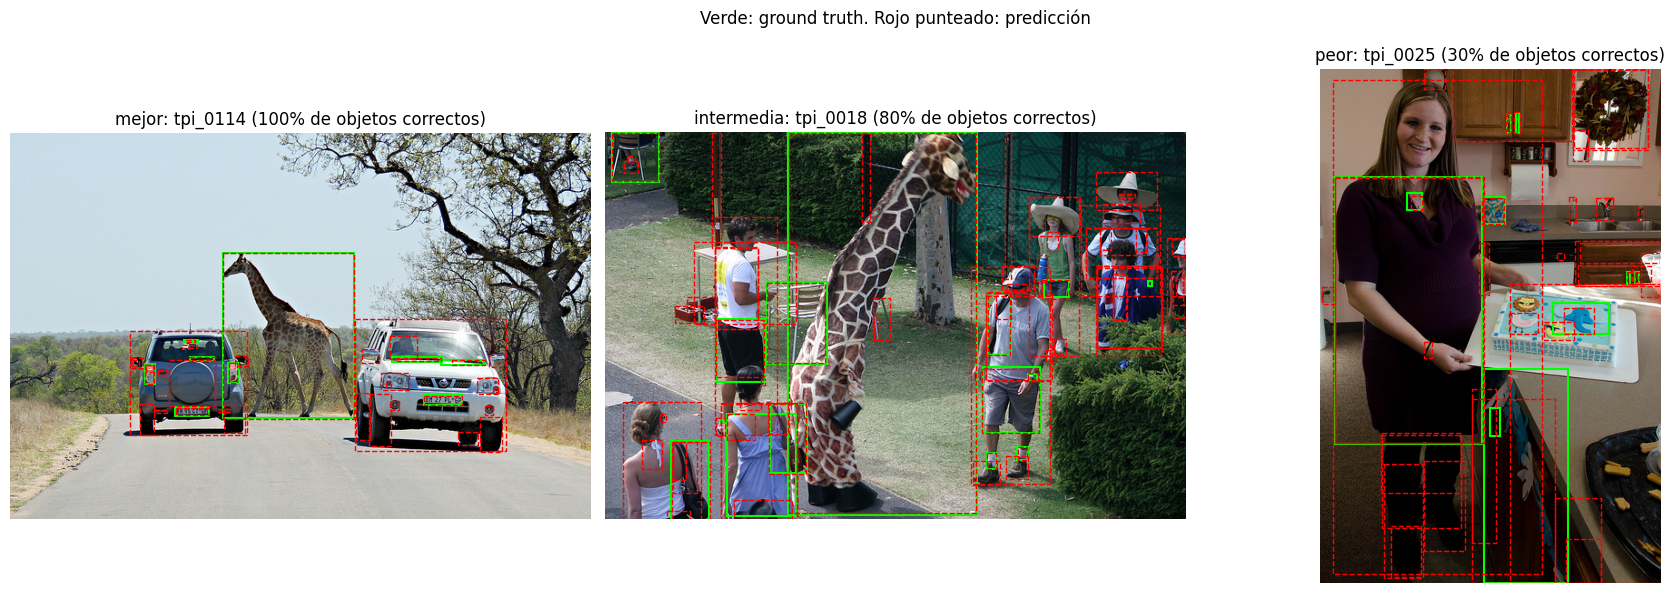

Etapas donde se pierden los objetos de la peor imagen:
etapa
4. máscara incorrecta               3
5. caja y máscara correctas         3
1. ningún detector lo propone       2
2. lo descarta el re-puntaje/NMS    1
3. queda bajo el umbral             1


In [36]:
per_img = funnel.assign(ok=funnel.etapa.str.startswith("5")).groupby("image_id").ok.mean().sort_values()
cases = {"mejor": per_img.index[-1], "intermedia": per_img.index[len(per_img) // 2], "peor": per_img.index[0]}
fig, axes = plt.subplots(1, 3, figsize=(18, 6))
for ax, (label, i) in zip(axes, cases.items()):
    ax.imshow(images[i]); ax.axis("off")
    for o in gt[i]["objects"]:
        x0, y0, x1, y1 = o["box"]
        ax.add_patch(patches.Rectangle((x0, y0), x1 - x0, y1 - y0, fill=False, color="lime", lw=1.5))
    for p in dev_scenes[i]["objects"]:
        if p["confidence"] >= SCENE_CFG["threshold"]:
            x0, y0, x1, y1 = p["bbox"]
            ax.add_patch(patches.Rectangle((x0, y0), x1 - x0, y1 - y0, fill=False, color="red", lw=1, ls="--"))
    ax.set_title(f"{label}: {i} ({per_img[i]:.0%} de objetos correctos)")
plt.suptitle("Verde: ground truth. Rojo punteado: predicción"); plt.tight_layout(); plt.show()
print("Etapas donde se pierden los objetos de la peor imagen:")
print(funnel[funnel.image_id == cases["peor"]].etapa.value_counts().to_string())

In [37]:
expected = {r["question_id"]: r.get("expected_normalized_answer") for i in bench_ids for r in qa_refs[i]}
rows = []
for r in llm_trace:
    if r["question_id"] in expected and expected[r["question_id"]] is not None:
        status = r["query"].get("status")
        verdict = ("ambigua / no soportada" if status != "ok" else "correcta" if r["result"] == expected[r["question_id"]]
                   else "fallida")
        rows.append({"pregunta": r["question"], "JSON": {k: r["query"].get(k) for k in ["operation", "category", "category_b", "predicate", "reason"]
                                                         if r["query"].get(k) is not None},
                     "respuesta": r["result"], "esperada": expected[r["question_id"]], "caso": verdict})
cases_qa = pd.DataFrame(rows)
print(cases_qa.caso.value_counts().to_string())
for verdict in ["correcta", "ambigua / no soportada", "fallida"]:
    print(f"\n== {verdict} ==")
    print(cases_qa[cases_qa.caso == verdict].head(3).drop(columns="caso").to_string(index=False))

caso
correcta    33
fallida      7

== correcta ==
                                                                    pregunta                                                    JSON respuesta esperada
   ¿Hay al menos una instancia de la categoría "tomacorriente" en la imagen?   {'operation': 'existence', 'category': 'wall socket'}       yes      yes
       ¿Cuántas instancias de la categoría "calcetín" aparecen en la imagen?              {'operation': 'count', 'category': 'sock'}         2        2
¿Hay al menos una instancia de la categoría "raqueta de tenis" en la imagen? {'operation': 'existence', 'category': 'tennis racket'}       yes      yes

== ambigua / no soportada ==
Empty DataFrame
Columns: [pregunta, JSON, respuesta, esperada]
Index: []

== fallida ==
                                                                   pregunta                                           JSON respuesta esperada
¿Cuántas instancias de la categoría "pomo de puerta" aparecen en la imagen? {'ope

**Lectura de los fallos.** Una respuesta fallida del modo LLM con la consulta bien interpretada es un error de
percepción (el SceneJSON no tiene el objeto, o tiene de más): coincide con la del modo determinista. Las ambiguas o no
soportadas son preguntas cuyo objeto no se pudo llevar al vocabulario.

## 8. Envío (60 imágenes de test + 20 del benchmark de preguntas)

In [38]:
test_scenes = build(test_raw, test_ids, SCENE_CFG)
submission = tc.scenes_to_submission({**test_scenes, **bench_scenes})
with tracer.stage("validacion_envio", None) as rec:
    errors = tc.validate_submission(submission)
    rec["salida"] = {"filas": len(submission), "errores": errors[:5]}
print(len(submission), "filas;", "errores:", errors[:5] if errors else "ninguno")
submission.to_csv(WORK / "submission.csv", index=False)
ttr.log("== envío escrito ==")
tracer.artifact(WORK / "submission.csv", "envío")
with open(WORK / "config_final.json", "w") as f:
    json.dump({**CONFIG, "escena": SCENE_CFG, "qa_umbrales": QA_TH}, f, indent=1, default=str)
print(tracer.summary().to_string())

80 filas; errores: ninguno
[1:58:17] == envío escrito ==
                         veces  errores  segundos_total  segundos_media
etapa                                                                  
deteccion                  900        0        6150.464           6.834
qa_determinista             20        0           0.000           0.000
qa_llm                      20        0         320.695          16.035
repuntaje_entrenamiento      2        0           9.906           4.953
segmentacion               200        0         331.034           1.655
segmentacion_ampliada      200        0         637.797           3.189
validacion_envio             1        0           5.593           5.593


## 9. Trazabilidad

`traza.jsonl` (primera línea: configuración completa y versiones; después una línea por etapa e imagen con parámetros,
estado, duración, tamaño de la salida y error si lo hubo), `traza_llm.jsonl` (texto crudo del LLM, intentos, consulta
validada, resultado y verbalización de cada pregunta), los candidatos de cada detector (`det_*.json.gz`), los modelos
de re-puntaje (`repuntaje_modelos.pkl`), la configuración elegida (`config_final.json`) y las tablas de cada
experimento (`*.csv`).

In [39]:
config, records = ttr.load(WORK / "traza.jsonl")
print("ejecución", config["ejecucion"], "| versiones", config["versiones"])
print(records[records.tipo == "etapa"].groupby("etapa").agg(veces=("estado", "size"),
      errores=("estado", lambda s: (s == "error").sum()), segundos=("segundos", "sum")).round(1).to_string())

ejecución cebf0add | versiones {'torch': '2.11.0+cu128', 'transformers': '5.20.0', 'numpy': '2.1.3'}
                         veces  errores  segundos
etapa                                            
deteccion                  900        0    6150.5
qa_determinista             20        0       0.0
qa_llm                      20        0     320.7
repuntaje_entrenamiento      2        0       9.9
segmentacion               200        0     331.0
segmentacion_ampliada      200        0     637.8
validacion_envio             1        0       5.6


## Anexo: lo que se probó y no se usa

Cada idea se probó con la misma validación por mitades (F1 de cajas en imágenes no vistas, salvo que se indique otra
cosa) y se descartó porque no mejoró por más de 0.002. Los números son de su experimento; no se recalculan acá.

| Idea | Resultado | Referencia |
|---|---|---|
| OWLv2 large (+ recortes 2x2) como detector | solo 0.6007; con Grounding DINO y re-puntaje 0.6733 | reemplazado por ViTDet-H (0.7659) y luego EVA-02 |
| OWLv2 con vectores de categoría ajustados al dataset | solo 0.6218 (+0.02); en el re-puntaje 0.6635 | 0.6733 sin ajustar |
| Vistas extra: espejo, contraste CLAHE, mayor resolución | 0.6480 a 0.6679 | 0.6733 sin ellas |
| Varias frases por categoría / ejemplos visuales de OWLv2 | 0.6647 / 0.6661 | 0.6733 |
| Verificador con SigLIP sobre recortes de candidatos dudosos | 0.6345 | 0.6744 sin verificador |
| LLMDet y MM-Grounding-DINO | F1 ~0.05 con prompts de 24 categorías | — |
| ViTDet-H (LVIS) como detector principal | re-puntaje 0.7965 | EVA-02: 0.8166 (versión 13) |
| ViTDet-L como fuente extra / ViTDet-H a 1600 px | 0.7655 / 0.7626 | 0.7659 |
| Un clasificador por tamaño (chicas / resto) | 0.6549 | 0.6733 (un solo clasificador) |
| Fuentes desde puntaje 0.02, NMS propio para cajas chicas, más peso a positivos chicos | 0.7342 a 0.7788 | 0.7809 |
| Señales de acuerdo con OWLv2, SAM 3 y ViTDet-L sin sumar sus candidatos | −0.002 a −0.007 | 0.7852 |
| Promedio de varios clasificadores iguales (otras muestras o semillas) | −0.001 a −0.008 | 0.7852 |
| Bosque aleatorio como tercer clasificador / regresión logística | 0.7886 / 0.7861 a 0.7893 | 0.7920 (HGB + árboles extremos) |
| Auto-contexto (segunda pasada con las probabilidades de la primera) | 0.7801 a 0.7926 | 0.7920 |
| Soft-NMS con las fuentes de EVA-02 | 0.8069 a 0.8145 | 0.8166 con NMS |
| Pesos EMA de EVA-02 (O365) | idénticos a los comunes (mismo F1) | — |
| EVA-02 en espejo / recortes 3x3 / ambos, como fuentes extra (4 particiones) | −0.0013 / −0.0049 / +0.0024 (pierde en 1 de 4) | 0.8166 |
| EVA-02 a 1792 px | no corre: su codificación de posición está fija en 1536 px | — |
| Filtros antes de EVA-02: CLAHE, enfoque, reducción de ruido, enfoque en 2x2 (4 particiones) | −0.0024 a −0.0094 | 0.8166 |
| Relaciones: otro mínimo de P(anotado), separación, dos parejas, pareja entre todos, overlaps, máximo de objetos | escena 0.7133 a 0.7216 | escena 0.7242 |
| Máscaras: SAM2 con un punto dentro de la máscara gruesa / mejor fuente por tamaño | F1 de máscaras 0.7636 / 0.7891 | 0.7907 |
| WeDetect-Large (Tencent) como fuente | sin medir: sus pesos no cargan con `weights_only=True` (piden `getattr`) y no se cargan de otra forma | — |